In [ ]:
!pip install -q tensorflow librosa soundfile numpy matplotlib

In [170]:
import os
import pickle
import time
from collections import deque
import glob
import nbformat
import tensorflow as tf

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from datasets import load_dataset

from tensorflow.keras.models import load_model
from sklearn.metrics import recall_score, f1_score
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score)

In [171]:
pasta_backchannel = "/content/drive/MyDrive/speaker-pause-detection/backchannel-lstm"

caminho_modelo = os.path.join(
    pasta_backchannel,
    "modelo_backchannel_audio.keras"
)

caminho_parametros = os.path.join(
    pasta_backchannel,
    "parametros_normalizacao.pkl"
)

print("Pasta:", pasta_backchannel)
print("Modelo:", caminho_modelo)
print("Parâmetros:", caminho_parametros)

Pasta: /content/drive/MyDrive/speaker-pause-detection/backchannel-lstm
Modelo: /content/drive/MyDrive/speaker-pause-detection/backchannel-lstm/modelo_backchannel_audio.keras
Parâmetros: /content/drive/MyDrive/speaker-pause-detection/backchannel-lstm/parametros_normalizacao.pkl


In [172]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(os.listdir("/content/drive/MyDrive"))

['speaker-pause-detection', 'Colab Notebooks', 'IA2_Prática_03.gdoc', 'Cópia de Header Linkedin (2).gslides', 'Cópia de Header Linkedin (1).gslides', 'Cópia de Header Linkedin.gslides', 'Artigo LLMs', 'TCPV_IGM_JULIANA_PRADO_FERREIRA_assinado.pdf', 'IC - CTI Renato Archer', 'WhatsApp Image 2026-09-02 at 15.21.52.jpeg', 'Captura de Tela 2026-09-02 às 15.24.16.png', 'Captura de Tela 2026-09-03 às 14.48.28.png', 'Captura de Tela 2026-09-03 às 15.58.38.png', 'IMG_2875.png', 'IMG_2876.png', 'Classroom', 'ANOTAÇÕES PROJETO INTEGRADOR VI.gdoc', 'kurose2010.pdf', 'IDEIAS PESQUISA DADOS ESPACIAIS.gdoc', 'IDEIAS FINAIS PESQUISA DADOS ESPACIAIS.gdoc', 'IMG_3055.png', 'IMG_3056.png', 'Gemini Gems', 'BarceDivas', 'IMG_3382.png', 'IMG_3383.png', 'copy_FFAB1E8F-1F33-49AB-A191-DBF68AB20864.mov', 'IA.pdf', 'copy_14F40FB3-FA3B-41F2-96D7-2B7BA9FDB4DE.mov', 'IMG_3608.png', 'IMG_3609.png', 'Passo a Passo - MergeSort Concorrente.gdoc', 'Estudos P1_260930_012622.pdf', ' Aula 01: Petrologia Metamórf

In [ ]:
caminho_projeto = "/content/drive/MyDrive/speaker-pause-detection"

print(os.listdir(caminho_projeto))

['backchannel-lstm', 'backchannel-lstm-english']


In [ ]:
pasta_backchannel = "/content/drive/MyDrive/speaker-pause-detection/backchannel-lstm"

print(os.listdir(pasta_backchannel))

['modelo_backchannel_audio.keras', 'parametros_normalizacao.pkl']


In [ ]:
modelo = load_model(caminho_modelo)

with open(caminho_parametros, "rb") as f:
    parametros = pickle.load(f)

print("Modelo carregado!")
print("Parâmetros carregados!")

Modelo carregado!
Parâmetros carregados!


In [ ]:
print("Parâmetros utilizados no treinamento:")

for chave, valor in parametros.items():
    if isinstance(valor, np.ndarray):
        print(f"{chave}: array com shape {valor.shape}")
    else:
        print(f"{chave}: {valor}")

Parâmetros utilizados no treinamento:
media: array com shape (1, 1, 13)
desvio: array com shape (1, 1, 13)
maxlen: 121
n_mfcc: 13


In [ ]:
arquivos_audio = glob.glob(
    "/content/drive/MyDrive/speaker-pause-detection/**/*.wav",
    recursive=True
)

print(f"Encontrados {len(arquivos_audio)} arquivos de áudio.")

for arquivo in arquivos_audio[:10]:
    print(arquivo)

Encontrados 0 arquivos de áudio.


In [ ]:
from google.colab import files

arquivos = files.upload()

Saving Um falante.m4a to Um falante.m4a


In [ ]:
print("Arquivos enviados:")

for nome in arquivos.keys():
    print(nome)

Arquivos enviados:
Um falante.m4a


In [ ]:
nome_audio = "Um falante.m4a"

audio, sr = librosa.load(nome_audio, sr=None, mono=True)

duracao = len(audio) / sr

print(f"Frequência original: {sr} Hz")
print(f"Duração: {duracao:.2f} segundos")
print(f"Formato do áudio: {audio.shape}")
print(f"Áudio carregado: {'Sim' if len(audio) > 0 else 'Não'}")

/tmp/ipykernel_1853/3557305331.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(nome_audio, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Frequência original: 48000 Hz
Duração: 43.54 segundos
Formato do áudio: (2089984,)
Áudio carregado: Sim


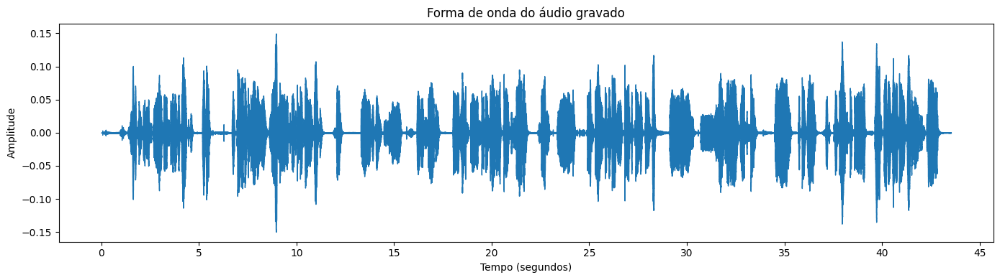

In [ ]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(audio, sr=sr)

plt.title("Forma de onda do áudio gravado")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

In [ ]:
audio_16k = librosa.resample(
    audio,
    orig_sr=sr,
    target_sr=16000
)

sr_modelo = 16000

print(f"Frequência original: {sr} Hz")
print(f"Nova frequência: {sr_modelo} Hz")
print(f"Duração após conversão: {len(audio_16k) / sr_modelo:.2f} segundos")

Frequência original: 48000 Hz
Nova frequência: 16000 Hz
Duração após conversão: 43.54 segundos


In [ ]:
mfcc = librosa.feature.mfcc(
    y=audio_16k,
    sr=16000,
    n_mfcc=parametros["n_mfcc"],
    hop_length=160,
    n_fft=400
)

print("Formato dos MFCCs:", mfcc.shape)
print("Formato esperado por frame:", parametros["n_mfcc"], "coeficientes")
print("Quantidade de frames:", mfcc.shape[1])

Formato dos MFCCs: (13, 4355)
Formato esperado por frame: 13 coeficientes
Quantidade de frames: 4355


In [ ]:
# Transpor para ficar no formato (frames, coeficientes)
mfcc_sequencia = mfcc.T

# Selecionar os primeiros 121 frames
maxlen = parametros["maxlen"]
trecho_mfcc = mfcc_sequencia[:maxlen]

# Adicionar dimensão do lote: (1, 121, 13)
entrada_modelo = np.expand_dims(trecho_mfcc, axis=0)

print("Formato da sequência:", trecho_mfcc.shape)
print("Formato de entrada do LSTM:", entrada_modelo.shape)

Formato da sequência: (121, 13)
Formato de entrada do LSTM: (1, 121, 13)


In [ ]:
media_norm = parametros["media"]
desvio_norm = parametros["desvio"]

# Evitar divisão por zero, caso algum desvio seja zero
desvio_seguro = np.where(desvio_norm == 0, 1e-8, desvio_norm)

entrada_normalizada = (
    entrada_modelo - media_norm
) / desvio_seguro

print("Formato da entrada normalizada:", entrada_normalizada.shape)
print("Contém valores inválidos?", not np.isfinite(entrada_normalizada).all())
print("Média dos valores:", np.mean(entrada_normalizada))
print("Desvio dos valores:", np.std(entrada_normalizada))

Formato da entrada normalizada: (1, 121, 13)
Contém valores inválidos? False
Média dos valores: -0.40711075
Desvio dos valores: 1.3718643


In [ ]:
probabilidade = modelo.predict(
    entrada_normalizada,
    verbose=0
)[0][0]

print(f"Probabilidade de backchannel: {probabilidade:.4f}")
print(f"Probabilidade em porcentagem: {probabilidade * 100:.2f}%")

Probabilidade de backchannel: 0.0380
Probabilidade em porcentagem: 3.80%


In [ ]:
# Parâmetros da análise
maxlen = parametros["maxlen"]
passo_frames = 10  # aproximadamente 0,1 segundo

# MFCCs no formato (frames, coeficientes)
mfcc_sequencia = mfcc.T

resultados = []

for inicio in range(0, len(mfcc_sequencia) - maxlen + 1, passo_frames):
    fim = inicio + maxlen

    janela = mfcc_sequencia[inicio:fim]
    janela = np.expand_dims(janela, axis=0)

    janela_normalizada = (
        janela - media_norm
    ) / desvio_seguro

    prob = modelo.predict(janela_normalizada, verbose=0)[0][0]

    tempo_inicio = inicio * 160 / 16000
    tempo_fim = fim * 160 / 16000

    resultados.append({
        "inicio_s": tempo_inicio,
        "fim_s": tempo_fim,
        "probabilidade": float(prob)
    })

print("Quantidade de janelas analisadas:", len(resultados))
print("Primeiros resultados:")
for resultado in resultados[:5]:
    print(resultado)

Quantidade de janelas analisadas: 424
Primeiros resultados:
{'inicio_s': 0.0, 'fim_s': 1.21, 'probabilidade': 0.037983834743499756}
{'inicio_s': 0.1, 'fim_s': 1.31, 'probabilidade': 0.027916984632611275}
{'inicio_s': 0.2, 'fim_s': 1.41, 'probabilidade': 0.04363304749131203}
{'inicio_s': 0.3, 'fim_s': 1.51, 'probabilidade': 0.11681360006332397}
{'inicio_s': 0.4, 'fim_s': 1.61, 'probabilidade': 0.12381543964147568}


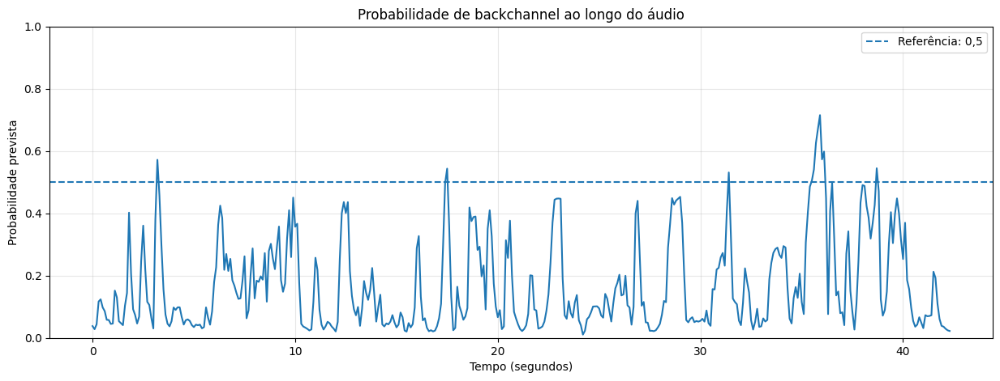

In [ ]:
tempos = [r["inicio_s"] for r in resultados]
probabilidades = [r["probabilidade"] for r in resultados]

plt.figure(figsize=(15, 5))

plt.plot(tempos, probabilidades)
plt.axhline(y=0.5, linestyle="--", label="Referência: 0,5")

plt.title("Probabilidade de backchannel ao longo do áudio")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Probabilidade prevista")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Parâmetros do modelo
maxlen = parametros["maxlen"]
n_mfcc = parametros["n_mfcc"]

duracao_janela = maxlen * 160 / 16000  # aproximadamente 1,21 s
passo_segundos = 0.1
passo_amostras = int(passo_segundos * 16000)
tamanho_janela = int(duracao_janela * 16000)

resultados_corrigidos = []

for inicio in range(
    0,
    len(audio_16k) - tamanho_janela + 1,
    passo_amostras
):
    trecho = audio_16k[inicio:inicio + tamanho_janela].astype(np.float32)

    # Normalização de amplitude, como na função original
    pico = np.max(np.abs(trecho))
    if pico > 0:
        trecho = trecho / pico

    # Extração de MFCCs
    mfcc_trecho = librosa.feature.mfcc(
        y=trecho,
        sr=16000,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc_trecho.T

    # Ajustar para o tamanho esperado pelo LSTM
    sequencia = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    # Normalização com os parâmetros salvos no treinamento
    sequencia_norm = (sequencia - media_norm) / desvio_seguro

    prob = modelo.predict(sequencia_norm, verbose=0)[0][0]

    resultados_corrigidos.append({
        "inicio_s": inicio / 16000,
        "probabilidade": float(prob)
    })

print("Janelas analisadas:", len(resultados_corrigidos))
print("Maior probabilidade:", max(
    r["probabilidade"] for r in resultados_corrigidos
))

Janelas analisadas: 424
Maior probabilidade: 0.8334071040153503


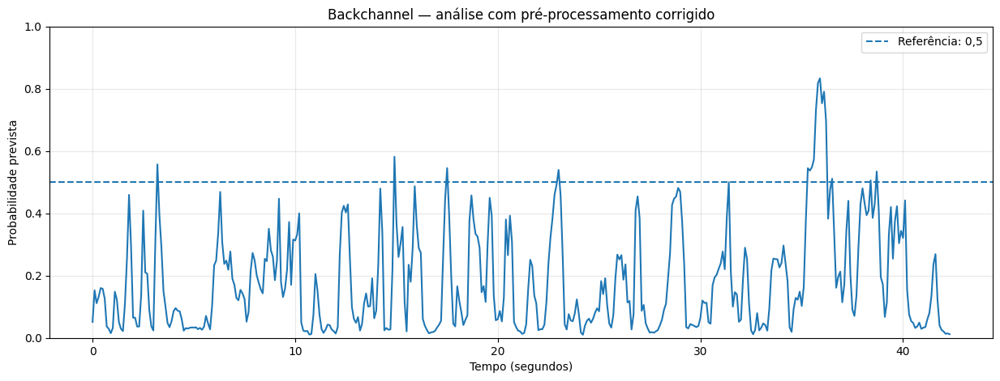

In [ ]:
tempos = [r["inicio_s"] for r in resultados_corrigidos]
probabilidades = [r["probabilidade"] for r in resultados_corrigidos]

plt.figure(figsize=(15, 5))
plt.plot(tempos, probabilidades)
plt.axhline(y=0.5, linestyle="--", label="Referência: 0,5")

plt.title("Backchannel — análise com pré-processamento corrigido")
plt.xlabel("Tempo (segundos)")
plt.ylabel("Probabilidade prevista")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Mostrar as 10 janelas com maiores probabilidades
top_janelas = sorted(
    resultados_corrigidos,
    key=lambda r: r["probabilidade"],
    reverse=True
)[:10]

for r in top_janelas:
    print(
        f"Tempo: {r['inicio_s']:.2f} s | "
        f"Probabilidade: {r['probabilidade']:.2%}"
    )

Tempo: 35.90 s | Probabilidade: 83.34%
Tempo: 35.80 s | Probabilidade: 81.86%
Tempo: 36.10 s | Probabilidade: 79.04%
Tempo: 36.00 s | Probabilidade: 75.32%
Tempo: 35.70 s | Probabilidade: 73.07%
Tempo: 36.20 s | Probabilidade: 69.63%
Tempo: 14.90 s | Probabilidade: 58.18%
Tempo: 35.60 s | Probabilidade: 57.31%
Tempo: 3.20 s | Probabilidade: 55.73%
Tempo: 35.50 s | Probabilidade: 54.78%


In [ ]:
inicio_trecho = 35
fim_trecho = 38

trecho_audio = audio_16k[
    int(inicio_trecho * 16000):
    int(fim_trecho * 16000)
]

display(Audio(trecho_audio, rate=16000))

In [ ]:
inicio_trecho = 14
fim_trecho = 17

trecho_audio = audio_16k[
    int(inicio_trecho * 16000):
    int(fim_trecho * 16000)
]

display(Audio(trecho_audio, rate=16000))

In [ ]:
inicio_trecho = 2
fim_trecho = 5

trecho_audio = audio_16k[
    int(inicio_trecho * 16000):
    int(fim_trecho * 16000)
]

display(Audio(trecho_audio, rate=16000))

In [ ]:
# Examinar janelas próximas de 5,5 segundos
tempo_alvo = 5.5
margem = 0.5

janelas_proximas = [
    r for r in resultados_corrigidos
    if tempo_alvo - margem <= r["inicio_s"] <= tempo_alvo + margem
]

for r in janelas_proximas:
    print(
        f"Janela: {r['inicio_s']:.2f}–"
        f"{r['inicio_s'] + 1.21:.2f} s | "
        f"Probabilidade: {r['probabilidade']:.2%}"
    )

Janela: 5.00–6.21 s | Probabilidade: 3.28%
Janela: 5.10–6.31 s | Probabilidade: 3.42%
Janela: 5.20–6.41 s | Probabilidade: 2.80%
Janela: 5.30–6.51 s | Probabilidade: 3.20%
Janela: 5.40–6.61 s | Probabilidade: 2.62%
Janela: 5.50–6.71 s | Probabilidade: 3.57%
Janela: 5.60–6.81 s | Probabilidade: 7.06%
Janela: 5.70–6.91 s | Probabilidade: 4.68%
Janela: 5.80–7.01 s | Probabilidade: 2.75%
Janela: 5.90–7.11 s | Probabilidade: 10.24%
Janela: 6.00–7.21 s | Probabilidade: 23.30%


In [ ]:
inicio_trecho = 5.4
fim_trecho = 5.4 + 1.21

trecho_audio = audio_16k[
    int(inicio_trecho * 16000):
    int(fim_trecho * 16000)
]

display(Audio(trecho_audio, rate=16000))

In [ ]:
# Testar janelas antes e durante o "uhum"
tempos_teste = np.arange(4.5, 5.51, 0.1)
resultados_uhum = []

for inicio_s in tempos_teste:
    inicio_amostra = int(inicio_s * 16000)
    fim_amostra = inicio_amostra + int(1.21 * 16000)

    trecho = audio_16k[inicio_amostra:fim_amostra].astype(np.float32)

    if len(trecho) < int(1.21 * 16000):
        continue

    pico = np.max(np.abs(trecho))
    if pico > 0:
        trecho = trecho / pico

    mfcc_trecho = librosa.feature.mfcc(
        y=trecho,
        sr=16000,
        n_mfcc=parametros["n_mfcc"],
        hop_length=160,
        n_fft=400
    )

    sequencia = pad_sequences(
        [mfcc_trecho.T],
        maxlen=parametros["maxlen"],
        dtype="float32",
        padding="post",
        truncating="post"
    )

    sequencia_norm = (sequencia - media_norm) / desvio_seguro
    prob = modelo.predict(sequencia_norm, verbose=0)[0][0]

    resultados_uhum.append((inicio_s, float(prob)))

for inicio_s, prob in resultados_uhum:
    print(f"Início: {inicio_s:.1f} s | Probabilidade: {prob:.2%}")

Início: 4.5 s | Probabilidade: 2.33%
Início: 4.6 s | Probabilidade: 3.14%
Início: 4.7 s | Probabilidade: 3.01%
Início: 4.8 s | Probabilidade: 3.23%
Início: 4.9 s | Probabilidade: 3.38%
Início: 5.0 s | Probabilidade: 3.28%
Início: 5.1 s | Probabilidade: 3.42%
Início: 5.2 s | Probabilidade: 2.80%
Início: 5.3 s | Probabilidade: 3.21%
Início: 5.4 s | Probabilidade: 2.62%
Início: 5.5 s | Probabilidade: 3.67%


In [ ]:
inicio_trecho = 5.0
fim_trecho = 6.0

trecho_audio = audio_16k[
    int(inicio_trecho * 16000):
    int(fim_trecho * 16000)
]

display(Audio(trecho_audio, rate=16000))

In [ ]:

def prever_backchannel(
    audio_trecho,
    sr_original,
    modelo,
    media_norm,
    desvio_norm,
    maxlen,
    n_mfcc=13,
    target_sr=16000
):
    audio_f = audio_trecho.astype(np.float32)

    # Normalizar a amplitude do áudio
    pico = np.max(np.abs(audio_f))
    if pico > 0:
        audio_f = audio_f / pico

    # Converter a frequência de amostragem, se necessário
    if sr_original != target_sr:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_original,
            target_sr=target_sr
        )

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=target_sr,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    # Preparar a sequência para o modelo
    sequencia = mfcc.T

    sequencia_padded = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    # Aplicar a normalização salva no treinamento
    desvio_seguro = np.where(desvio_norm == 0, 1e-8, desvio_norm)
    sequencia_norm = (sequencia_padded - media_norm) / desvio_seguro

    # Prever a probabilidade de backchannel
    probabilidade = modelo.predict(
        sequencia_norm,
        verbose=0
    )[0][0]

    return float(probabilidade)

In [ ]:

# Comparar diferentes janelas que contêm o "uhum"

def testar_janela(inicio_s, fim_s):
    trecho = audio_16k[
        int(inicio_s * 16000):int(fim_s * 16000)
    ].astype(np.float32)

    return prever_backchannel(
        trecho,
        sr_original=16000,
        modelo=modelo,
        media_norm=media_norm,
        desvio_norm=desvio_seguro,
        maxlen=parametros["maxlen"],
        n_mfcc=parametros["n_mfcc"],
        target_sr=16000
    )

janelas = [
    (5.0, 6.0),
    (4.5, 5.7),
    (4.0, 6.0),
    (4.0, 7.0)
]

for inicio, fim in janelas:
    prob = testar_janela(inicio, fim)
    print(f"{inicio:.1f}–{fim:.1f} s: {prob:.2%}")

5.0–6.0 s: 0.46%
4.5–5.7 s: 2.60%
4.0–6.0 s: 7.17%
4.0–7.0 s: 7.17%


In [ ]:
caminho_notebook = os.path.join(
    pasta_backchannel,
    "LSTM_Backchannel_PT.ipynb"
)

print("Notebook encontrado:", os.path.exists(caminho_notebook))
print("Caminho:", caminho_notebook)

Notebook encontrado: False
Caminho: /content/drive/MyDrive/speaker-pause-detection/backchannel-lstm/LSTM_Backchannel_PT.ipynb


In [ ]:

# Verificando as dimensões esperadas pelo modelo e os dados de entrada

print("Formato esperado pelo modelo:", modelo.input_shape)
print("Formato dos parâmetros de normalização:")
print("Média:", media_norm.shape)
print("Desvio:", desvio_norm.shape)

print("\nParâmetros do modelo:")
print("Número de MFCC:", n_mfcc)
print("Número máximo de frames:", maxlen)
print("Duração da janela:", round(duracao_janela, 3), "segundos")

# Extrair MFCC de um trecho de 1,21 segundo
inicio_teste = int(5.0 * sr_modelo)
fim_teste = inicio_teste + tamanho_janela
trecho_teste = audio_16k[inicio_teste:fim_teste].astype(np.float32)

# Aplicar a mesma normalização de amplitude usada na inferência
pico = np.max(np.abs(trecho_teste))
if pico > 0:
    trecho_teste = trecho_teste / pico

mfcc_teste = librosa.feature.mfcc(
    y=trecho_teste,
    sr=sr_modelo,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

print("\nFormato dos MFCC extraídos:", mfcc_teste.shape)
print("Número de frames:", mfcc_teste.shape[1])
print("Formato após transposição:", mfcc_teste.T.shape)

Formato esperado pelo modelo: (None, 121, 13)
Formato dos parâmetros de normalização:
Média: (1, 1, 13)
Desvio: (1, 1, 13)

Parâmetros do modelo:
Número de MFCC: 13
Número máximo de frames: 121
Duração da janela: 1.21 segundos

Formato dos MFCC extraídos: (13, 122)
Número de frames: 122
Formato após transposição: (122, 13)


In [ ]:

# Comparar durações diferentes ao redor do "uhum"

duracoes = [0.4, 0.6, 0.8, 1.0, 1.2]
centro = 5.5  # posição aproximada do "uhum" no áudio

for duracao in duracoes:
    inicio = max(0, centro - duracao / 2)
    fim = centro + duracao / 2

    trecho = audio_16k[
        int(inicio * sr_modelo):int(fim * sr_modelo)
    ].astype(np.float32)

    # Normalização da amplitude
    pico = np.max(np.abs(trecho))
    if pico > 0:
        trecho = trecho / pico

    # Extração dos MFCC
    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=sr_modelo,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc.T

    # Ajustar para o tamanho esperado pelo modelo
    sequencia = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    # Normalização com os parâmetros salvos
    sequencia_norm = (sequencia - media_norm) / desvio_seguro

    probabilidade = modelo.predict(
        sequencia_norm, verbose=0
    )[0][0]

    print(
        f"Janela: {duracao:.1f} s | "
        f"Trecho: {inicio:.2f}–{fim:.2f} s | "
        f"Probabilidade: {probabilidade:.2%}"
    )

Janela: 0.4 s | Trecho: 5.30–5.70 s | Probabilidade: 2.16%
Janela: 0.6 s | Trecho: 5.20–5.80 s | Probabilidade: 0.87%
Janela: 0.8 s | Trecho: 5.10–5.90 s | Probabilidade: 0.65%
Janela: 1.0 s | Trecho: 5.00–6.00 s | Probabilidade: 0.46%
Janela: 1.2 s | Trecho: 4.90–6.10 s | Probabilidade: 3.58%


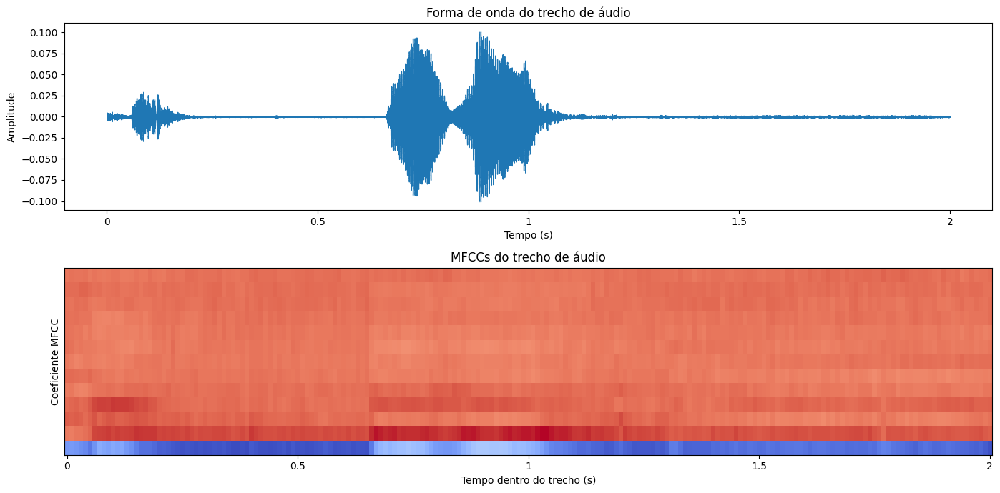

In [ ]:
inicio = 4.5
fim = 6.5

trecho = audio_16k[
    int(inicio * sr_modelo):int(fim * sr_modelo)
]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Forma de onda
librosa.display.waveshow(
    trecho,
    sr=sr_modelo,
    ax=axes[0]
)
axes[0].set_title("Forma de onda do trecho de áudio")
axes[0].set_xlabel("Tempo (s)")
axes[0].set_ylabel("Amplitude")

# MFCCs do mesmo trecho
mfcc = librosa.feature.mfcc(
    y=trecho.astype(np.float32),
    sr=sr_modelo,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

librosa.display.specshow(
    mfcc,
    sr=sr_modelo,
    hop_length=160,
    x_axis="time",
    ax=axes[1]
)
axes[1].set_title("MFCCs do trecho de áudio")
axes[1].set_xlabel("Tempo dentro do trecho (s)")
axes[1].set_ylabel("Coeficiente MFCC")

plt.tight_layout()
plt.show()

In [ ]:

duracoes = [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]
centro = 5.35

for duracao in duracoes:
    inicio = max(0, centro - duracao / 2)
    fim = centro + duracao / 2

    trecho = audio_16k[
        int(inicio * sr_modelo):int(fim * sr_modelo)
    ].astype(np.float32)

    pico = np.max(np.abs(trecho))
    if pico > 0:
        trecho = trecho / pico

    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=sr_modelo,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc.T

    sequencia = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    sequencia_norm = (
        sequencia - media_norm
    ) / desvio_seguro

    probabilidade = modelo.predict(
        sequencia_norm, verbose=0
    )[0][0]

    print(
        f"{duracao:.1f} s | "
        f"{inicio:.2f}–{fim:.2f} s | "
        f"{probabilidade:.2%}"
    )

0.3 s | 5.20–5.50 s | 93.02%
0.4 s | 5.15–5.55 s | 89.81%
0.5 s | 5.10–5.60 s | 39.48%
0.6 s | 5.05–5.65 s | 1.41%
0.8 s | 4.95–5.75 s | 0.54%
1.0 s | 4.85–5.85 s | 0.35%
1.2 s | 4.75–5.95 s | 1.29%


In [ ]:

for raiz, pastas, arquivos in os.walk(pasta_backchannel):
    # Evita listar pastas internas muito grandes
    pastas[:] = [
        p for p in pastas
        if p not in [".git", "__pycache__"]
    ]

    for arquivo in arquivos:
        if arquivo.endswith((".ipynb", ".py", ".pkl", ".csv", ".npy")):
            print(os.path.join(raiz, arquivo))

/content/drive/MyDrive/speaker-pause-detection/backchannel-lstm/parametros_normalizacao.pkl


In [ ]:

pasta_projeto = "/content/drive/MyDrive/speaker-pause-detection"

for raiz, pastas, arquivos in os.walk(pasta_projeto):
    pastas[:] = [
        p for p in pastas
        if p not in [".git", "__pycache__"]
    ]

    for arquivo in arquivos:
        if arquivo.endswith(".ipynb"):
            print(os.path.join(raiz, arquivo))

In [ ]:
pasta_backchannel = (
    "/content/drive/MyDrive/speaker-pause-detection/backchannel-lstm"
)

print("A pasta existe?", os.path.exists(pasta_backchannel))
print("\nArquivos encontrados:")

if os.path.exists(pasta_backchannel):
    for item in os.listdir(pasta_backchannel):
        caminho = os.path.join(pasta_backchannel, item)
        tipo = "Pasta" if os.path.isdir(caminho) else "Arquivo"
        print(f"{tipo}: {item}")

A pasta existe? True

Arquivos encontrados:
Arquivo: modelo_backchannel_audio.keras
Arquivo: parametros_normalizacao.pkl


In [ ]:

%history -g

   1:
import os
import pickle
import time
from collections import deque
import glob
import nbformat
import tensorflow as tf

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from datasets import load_dataset

from tensorflow.keras.models import load_model
from sklearn.metrics import recall_score, f1_score
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score)
   2:
pasta_backchannel = "/content/drive/MyDrive/speaker-pause-detection/backchannel-lstm"

caminho_modelo = os.path.join(
    pasta_backchannel,
    "modelo_backchannel_audio.keras"
)

caminho_para

In [ ]:

# Comparar o preenchimento antes e depois da normalização

duracao = 0.3
centro = 5.35

inicio = centro - duracao / 2
fim = centro + duracao / 2

trecho = audio_16k[
    int(inicio * sr_modelo):int(fim * sr_modelo)
].astype(np.float32)

pico = np.max(np.abs(trecho))
if pico > 0:
    trecho = trecho / pico

mfcc_teste = librosa.feature.mfcc(
    y=trecho,
    sr=sr_modelo,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

sequencia = mfcc_teste.T

print("Frames extraídos:", sequencia.shape[0])
print("Frames esperados:", maxlen)

sequencia_preenchida = pad_sequences(
    [sequencia],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

quantidade_frames_reais = min(sequencia.shape[0], maxlen)

print(
    "Frames preenchidos:",
    maxlen - quantidade_frames_reais
)

sequencia_norm = (
    sequencia_preenchida - media_norm
) / desvio_seguro

if quantidade_frames_reais < maxlen:
    parte_preenchida = sequencia_norm[
        0, quantidade_frames_reais:, :
    ]

    print(
        "Média dos valores normalizados no preenchimento:",
        float(np.mean(parte_preenchida))
    )

    print(
        "Mínimo no preenchimento:",
        float(np.min(parte_preenchida))
    )

    print(
        "Máximo no preenchimento:",
        float(np.max(parte_preenchida))
    )

Frames extraídos: 31
Frames esperados: 121
Frames preenchidos: 90
Média dos valores normalizados no preenchimento: 0.05372270569205284
Mínimo no preenchimento: -1.2535382509231567
Máximo no preenchimento: 1.2565895318984985


In [ ]:

duracao = 0.3
centro = 5.35

inicio = centro - duracao / 2
fim = centro + duracao / 2

trecho = audio_16k[
    int(inicio * sr_modelo):int(fim * sr_modelo)
].astype(np.float32)

pico = np.max(np.abs(trecho))
if pico > 0:
    trecho = trecho / pico

mfcc_teste = librosa.feature.mfcc(
    y=trecho,
    sr=sr_modelo,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

sequencia = mfcc_teste.T
frames_reais = min(len(sequencia), maxlen)

# Método A: preencher antes de normalizar
entrada_a = pad_sequences(
    [sequencia],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

entrada_a = (entrada_a - media_norm) / desvio_seguro

# Método B: normalizar os frames reais e depois preencher
sequencia_real_norm = (
    sequencia[:frames_reais] - media_norm.reshape(-1, n_mfcc)
) / desvio_seguro.reshape(-1, n_mfcc)

entrada_b = np.zeros((1, maxlen, n_mfcc), dtype=np.float32)
entrada_b[0, :frames_reais, :] = sequencia_real_norm

# Comparar previsões
prob_a = modelo.predict(entrada_a, verbose=0)[0][0]
prob_b = modelo.predict(entrada_b, verbose=0)[0][0]

print(f"Preenchimento antes da normalização: {prob_a:.2%}")
print(f"Preenchimento depois da normalização: {prob_b:.2%}")

Preenchimento antes da normalização: 93.02%
Preenchimento depois da normalização: 78.09%


In [ ]:

print("Média por coeficiente MFCC:")
print(np.round(media_norm.reshape(-1), 4))

print("\nDesvio padrão por coeficiente MFCC:")
print(np.round(desvio_norm.reshape(-1), 4))

print("\nResumo dos parâmetros:")
print("Média global:", float(np.mean(media_norm)))
print("Desvio global:", float(np.mean(desvio_norm)))
print("Menor desvio:", float(np.min(desvio_norm)))
print("Maior desvio:", float(np.max(desvio_norm)))

Média por coeficiente MFCC:
[-201.0796  106.4766  -19.2039   34.2571  -13.9716   11.3556   -5.3404
   -2.3055    3.2402   -8.8191    6.7719   -8.4843    3.3018]

Desvio padrão por coeficiente MFCC:
[160.0201  84.9408  27.3436  32.6477  18.669   17.6983  12.0534  11.4355
  11.482   11.6577  11.4257  11.4503   9.954 ]

Resumo dos parâmetros:
Média global: -7.215482711791992
Desvio global: 32.3675422668457
Menor desvio: 9.953993797302246
Maior desvio: 160.02008056640625


In [ ]:

# Quantidade de frames reais do recorte de 0,3 s
frames_reais = min(sequencia.shape[0], maxlen)

# Estatísticas apenas dos frames reais
mfcc_reais = sequencia[:frames_reais]

mfcc_norm_reais = (
    mfcc_reais - media_norm.reshape(-1, n_mfcc)
) / desvio_seguro.reshape(-1, n_mfcc)

print("Quantidade de frames reais:", frames_reais)
print("Média global antes da normalização:", float(np.mean(mfcc_reais)))
print("Média global depois da normalização:", float(np.mean(mfcc_norm_reais)))
print("Desvio global depois da normalização:", float(np.std(mfcc_norm_reais)))

print("\nMédia normalizada por coeficiente:")
print(np.round(np.mean(mfcc_norm_reais, axis=0), 3))

print("\nDesvio normalizado por coeficiente:")
print(np.round(np.std(mfcc_norm_reais, axis=0), 3))

Quantidade de frames reais: 31
Média global antes da normalização: -24.794775009155273
Média global depois da normalização: -0.9298493266105652
Desvio global depois da normalização: 1.534141182899475

Média normalizada por coeficiente:
[-0.748  0.2   -0.017  0.428  1.587 -2.136 -1.847 -3.747 -2.686 -0.132
 -1.974 -0.677 -0.338]

Desvio normalizado por coeficiente:
[0.326 0.171 0.564 0.298 0.799 0.473 0.677 0.914 0.533 0.448 0.698 0.465
 0.965]


In [ ]:

# Procurar variáveis de treinamento que ainda estejam na memória

variaveis_interesse = [
    "X", "X_train", "X_test",
    "X_padded", "X_norm",
    "X_train_norm", "X_test_norm",
    "mfcc_sequences", "sequencias",
    "maxlen", "media", "desvio"
]

for nome in variaveis_interesse:
    if nome in globals():
        valor = globals()[nome]

        print(f"\nVariável: {nome}")
        print("Tipo:", type(valor))

        if hasattr(valor, "shape"):
            print("Shape:", valor.shape)
        elif isinstance(valor, list):
            print("Quantidade de elementos:", len(valor))
        else:
            print("Valor:", str(valor)[:200])


Variável: maxlen
Tipo: <class 'int'>
Valor: 121


In [ ]:

# Procurar no histórico comandos relacionados ao pré-processamento

ip = get_ipython()

for numero, codigo in enumerate(ip.history_manager.input_hist_raw):
    if any(
        termo in codigo.lower()
        for termo in [
            "pad_sequences",
            "fit_transform",
            "media_norm",
            "desvio_norm",
            "standardscaler",
            "mfcc",
            "x_train"
        ]
    ):
        print(f"\n--- Célula histórica {numero} ---")
        print(codigo[:2500])


--- Célula histórica 1 ---
import os
import pickle
import time
from collections import deque
import glob
import nbformat
import tensorflow as tf

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from datasets import load_dataset

from tensorflow.keras.models import load_model
from sklearn.metrics import recall_score, f1_score
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score)

--- Célula histórica 15 ---
mfcc = librosa.feature.mfcc(
    y=audio_16k,
    sr=16000,
    n_mfcc=parametros["n_mfcc"],
    hop_length=160,
    n_fft=400
)

print("Formato dos

In [ ]:

ip = get_ipython()
historico = ip.history_manager.input_hist_raw

termos = [
    "pad_sequences(",
    "np.mean(",
    "np.std(",
    "np.save",
    "pickle.dump",
    "fit(",
    "mfcc.T",
    "maxlen =",
    "maxlen="
]

for termo in termos:
    print(f"\n{'='*20} BUSCA: {termo} {'='*20}")
    encontrados = 0

    for i, codigo in enumerate(historico):
        if termo.lower() in codigo.lower():
            print(f"\n--- Célula {i} ---")
            print(codigo[:1800])
            encontrados += 1

            if encontrados >= 4:
                print("(limite de 4 resultados por termo)")
                break

    if encontrados == 0:
        print("Nenhum resultado encontrado.")


==================== BUSCA: pad_sequences( ====================

--- Célula 21 ---
# Parâmetros do modelo
maxlen = parametros["maxlen"]
n_mfcc = parametros["n_mfcc"]

duracao_janela = maxlen * 160 / 16000  # aproximadamente 1,21 s
passo_segundos = 0.1
passo_amostras = int(passo_segundos * 16000)
tamanho_janela = int(duracao_janela * 16000)

resultados_corrigidos = []

for inicio in range(
    0,
    len(audio_16k) - tamanho_janela + 1,
    passo_amostras
):
    trecho = audio_16k[inicio:inicio + tamanho_janela].astype(np.float32)

    # Normalização de amplitude, como na função original
    pico = np.max(np.abs(trecho))
    if pico > 0:
        trecho = trecho / pico

    # Extração de MFCCs
    mfcc_trecho = librosa.feature.mfcc(
        y=trecho,
        sr=16000,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc_trecho.T

    # Ajustar para o tamanho esperado pelo LSTM
    sequencia = pad_sequences(
        [sequencia],
        maxlen=maxl

In [ ]:
nome_procurado = "LSTM_Backchannel.ipynb"
raiz_drive = "/content/drive/MyDrive"

encontrados = []

for raiz, pastas, arquivos in os.walk(raiz_drive):
    # Evita procurar em pastas de cache e lixeira
    pastas[:] = [
        p for p in pastas
        if p not in [".Trash", ".cache", "node_modules"]
    ]

    if nome_procurado in arquivos:
        encontrados.append(os.path.join(raiz, nome_procurado))

print("Arquivos encontrados:", len(encontrados))

for caminho in encontrados:
    print(caminho)


Arquivos encontrados: 1
/content/drive/MyDrive/IC - CTI Renato Archer/LSTM_Backchannel.ipynb


In [ ]:
caminho_notebook = (
    "/content/drive/MyDrive/"
    "IC - CTI Renato Archer/LSTM_Backchannel.ipynb"
)

notebook = nbformat.read(caminho_notebook, as_version=4)

print("Total de células:", len(notebook.cells))

for i, celula in enumerate(notebook.cells):
    if celula.cell_type != "code":
        continue

    codigo = celula.source.lower()

    termos = [
        "mfcc",
        "pad_sequences",
        "normaliz",
        "media",
        "desvio",
        "pickle.dump",
        "model.fit",
        ".fit("
    ]

    if any(termo in codigo for termo in termos):
        print(f"\n{'='*18} CÉLULA {i} {'='*18}")
        print(celula.source[:3500])

Total de células: 42

================== CÉLULA 1 ==================
import numpy as np
import pandas as pd
import librosa
import random
import os
import pickle
import IPython.display as ipd
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Dropout
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.sequence import pad_sequences

================== CÉLULA 23 ==================
def extrair_mfcc_sequencia_coraa(audio_arr, sr_original, target_sr=16000, n_mfcc=13):
    audio_f = audio_arr.astype(np.float32)
    if np.max(np.abs(audio_f)) > 0:
        audio_f = audio_f / np.max(np.abs(audio_f))

    if sr_original != target_sr:
        audio_f = librosa.resample(audio_f, orig_sr=sr_original, target_sr=target_sr)

    mfcc = librosa.feature.mfcc(y=audio_f, sr=target_sr, n_mfcc=n_mfcc, hop_length=160, n_fft=400)
    return mfcc.T

In [ ]:

for i in range(24, min(31, len(notebook.cells))):
    celula = notebook.cells[i]

    print(f"\n{'='*15} CÉLULA {i} ({celula.cell_type}) {'='*15}")
    print(celula.source[:5000])


=============== CÉLULA 24 (markdown) ===============
Como cada segmento tem duração diferente (logo, número diferente de "quadros" de MFCC), aplica padding pra deixar todos com o mesmo tamanho (121 quadros). Depois normaliza os valores (média 0, desvio padrão 1), o que ajuda a rede neural a treinar melhor.

=============== CÉLULA 25 (code) ===============
maxlen_coraa = 121

X_audio_coraa = pad_sequences(sequencias_coraa, maxlen=maxlen_coraa, dtype='float32', padding='post', truncating='post')
print("Shape X_audio_coraa:", X_audio_coraa.shape)

media_coraa = X_audio_coraa.mean(axis=(0,1), keepdims=True)
desvio_coraa = X_audio_coraa.std(axis=(0,1), keepdims=True) + 1e-8
X_audio_coraa_norm = (X_audio_coraa - media_coraa) / desvio_coraa

=============== CÉLULA 26 (markdown) ===============
Organiza os dados de entrada: X_texto_coraa (se bate com léxico, 0 ou 1) e y_coraa (o rótulo que o modelo vai aprender a prever, nesse caso, igual ao léxico).

=============== CÉLULA 27 (code) ========

In [ ]:

# Verificar quais variáveis relacionadas ao treinamento ainda existem

variaveis = [
    "sequencias_coraa",
    "df_coraa_candidatos",
    "X_audio_coraa",
    "X_audio_coraa_norm",
    "y_coraa",
    "comprimentos",
    "modelo"
]

for nome in variaveis:
    print(f"{nome}: {'disponível' if nome in globals() else 'não disponível'}")

sequencias_coraa: não disponível
df_coraa_candidatos: não disponível
X_audio_coraa: não disponível
X_audio_coraa_norm: não disponível
y_coraa: não disponível
comprimentos: não disponível
modelo: disponível


In [ ]:

caminho_notebook = "/content/drive/MyDrive/IC - CTI Renato Archer/LSTM_Backchannel.ipynb"

print("Notebook encontrado:", os.path.exists(caminho_notebook))

if os.path.exists(caminho_notebook):
    print("Tamanho do arquivo:", round(os.path.getsize(caminho_notebook) / 1024, 2), "KB")

Notebook encontrado: True
Tamanho do arquivo: 852.61 KB


In [ ]:

notebook = nbformat.read(caminho_notebook, as_version=4)

for i, celula in enumerate(notebook.cells):
    if celula.cell_type == "code" and any(
        termo in celula.source
        for termo in [
            "sequencias_coraa =",
            "extrair_mfcc_sequencia_coraa",
            "df_coraa_candidatos",
            "candidatos_coraa"
        ]
    ):
        print(f"\n{'='*20} CÉLULA {i} {'='*20}\n")
        print(celula.source[:5000])


==================== CÉLULA 9 ====================

tamanho_amostra = 3000
duracao_maxima_backchannel_coraa = 1.2

candidatos_coraa = []

for i, exemplo in enumerate(ds_coraa):
    if i >= tamanho_amostra:
        break

    samples = exemplo['audio'].get_all_samples()
    duracao = samples.duration_seconds

    if duracao <= duracao_maxima_backchannel_coraa and duracao > 0.2:
        texto = exemplo['text'].strip()
        candidatos_coraa.append({
            "idx": i,
            "texto": texto,
            "duracao": duracao,
            "genero": exemplo['speech_genre'],
            "dataset_origem": exemplo['dataset'],
            "sample_rate": samples.sample_rate,
            "audio_array": samples.data.numpy().squeeze(),
            "candidato_lexico": eh_candidato_lexico(texto, lexico_backchannel)
        })

    if (i + 1) % 500 == 0:
        print(f"  {i+1}/{tamanho_amostra} exemplos verificados... ({len(candidatos_coraa)} candidatos até agora)")

print(f"\nTotal de candid

In [ ]:

# Procurar saídas salvas das células de treinamento
for i in [9, 23, 25, 29, 33, 39]:
    celula = notebook.cells[i]

    print(f"\n{'='*15} CÉLULA {i} {'='*15}")

    if celula.cell_type == "code":
        if celula.outputs:
            for saida in celula.outputs:
                if "text" in saida:
                    print(saida["text"][:2500])
                elif "data" in saida and "text/plain" in saida["data"]:
                    print(saida["data"]["text/plain"][:2500])
        else:
            print("Nenhuma saída salva.")


=============== CÉLULA 9 ===============
  500/3000 exemplos verificados... (141 candidatos até agora)
  1000/3000 exemplos verificados... (247 candidatos até agora)
  1500/3000 exemplos verificados... (402 candidatos até agora)
  2000/3000 exemplos verificados... (537 candidatos até agora)
  2500/3000 exemplos verificados... (724 candidatos até agora)
  3000/3000 exemplos verificados... (877 candidatos até agora)

Total de candidatos encontrados: 877
Candidatos que batem com léxico: 250

    idx                            texto   duracao  \
0     1                               uh  0.530062   
1     2       eu quero um café por favor  1.005062   
2     4     então vou começar de novo tá  1.171062   
3     5                            claro  0.382063   
4     8                             aham  0.409062   
5    10                                é  0.297063   
6    12                             aham  0.439063   
7    14  desde que eu estou na mooca sim  0.987062   
8    19            

In [ ]:
saida_celula_9 = notebook.cells[9].outputs

for saida in saida_celula_9:
    if "data" in saida and "text/html" in saida["data"]:
        print("A saída contém uma tabela HTML salva.")
        display(__import__("pandas").read_html(saida["data"]["text/html"])[0])
        break
else:
    print("Não encontrei uma tabela HTML salva.")
    print("Tipos de saída disponíveis:")
    for saida in saida_celula_9:
        print(list(saida.keys()))

A saída contém uma tabela HTML salva.


/tmp/ipykernel_1853/4173075520.py:6: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  display(__import__("pandas").read_html(saida["data"]["text/html"])[0])


,Unnamed: 0,idx,texto,duracao,genero,dataset_origem,sample_rate,candidato_lexico
0,0,1,uh,0.530062,Conversation or Interview or Reading,SP2010,16000,True
1,1,2,eu quero um café por favor,1.005062,Conversation or Interview or Reading,SP2010,16000,False
2,2,4,então vou começar de novo tá,1.171062,Conversation or Interview or Reading,SP2010,16000,False
3,3,5,claro,0.382063,Conversation or Interview or Reading,SP2010,16000,True
4,4,8,aham,0.409062,Conversation or Interview or Reading,SP2010,16000,True
5,5,10,é,0.297063,Conversation or Interview or Reading,SP2010,16000,True
6,6,12,aham,0.439063,Conversation or Interview or Reading,SP2010,16000,True
7,7,14,desde que eu estou na mooca sim,0.987062,Conversation or Interview or Reading,SP2010,16000,False
8,8,19,ãham,0.447062,Conversation or Interview or Reading,SP2010,16000,False
9,9,20,aham,0.400000,Conversation or Interview or Reading,SP2010,16000,True


In [ ]:

print("Dataset ds_coraa disponível:", "ds_coraa" in globals())

if "ds_coraa" in globals():
    print("Tipo:", type(ds_coraa))
else:
    print("Precisaremos recuperar o dataset antes de calcular as durações.")

Dataset ds_coraa disponível: False
Precisaremos recuperar o dataset antes de calcular as durações.


In [ ]:

termos = [
    "ds_coraa =",
    "load_dataset",
    "CORAA",
    "corAA",
    "datasets"
]

for i, celula in enumerate(notebook.cells):
    if celula.cell_type == "code":
        linhas_relevantes = [
            linha for linha in celula.source.splitlines()
            if any(termo.lower() in linha.lower() for termo in termos)
        ]

        if linhas_relevantes:
            print(f"\n--- CÉLULA {i} ---")
            print("\n".join(linhas_relevantes[:20]))


--- CÉLULA 3 ---
from datasets import load_dataset
ds_coraa = load_dataset("Racoci/CORAA-v1.1", split="train", streaming=True)
for i, exemplo in enumerate(ds_coraa):

--- CÉLULA 5 ---
for i, exemplo in enumerate(ds_coraa):

--- CÉLULA 9 ---
duracao_maxima_backchannel_coraa = 1.2
candidatos_coraa = []
for i, exemplo in enumerate(ds_coraa):
    if duracao <= duracao_maxima_backchannel_coraa and duracao > 0.2:
        candidatos_coraa.append({
        print(f"  {i+1}/{tamanho_amostra} exemplos verificados... ({len(candidatos_coraa)} candidatos até agora)")
print(f"\nTotal de candidatos encontrados: {len(candidatos_coraa)}")
df_coraa_candidatos = pd.DataFrame([{k: v for k, v in c.items() if k != "audio_array"} for c in candidatos_coraa])
print(f"Candidatos que batem com léxico: {df_coraa_candidatos['candidato_lexico'].sum()}")
df_coraa_candidatos.head(20)

--- CÉLULA 11 ---
print(df_coraa_candidatos["genero"].value_counts())
print(df_coraa_candidatos["dataset_origem"].value_counts())

---

In [ ]:
# Recarregar o dataset em uma nova iteração
ds_coraa_analise = load_dataset(
    "Racoci/CORAA-v1.1",
    split="train",
    streaming=True
)

duracoes_coraa = []
tamanho_amostra = 3000

for i, exemplo in enumerate(ds_coraa_analise):
    if i >= tamanho_amostra:
        break

    samples = exemplo["audio"].get_all_samples()
    duracao = samples.duration_seconds

    # Mesmo critério usado no treinamento
    if 0.2 < duracao <= 1.2:
        duracoes_coraa.append(duracao)

    if (i + 1) % 500 == 0:
        print(f"Exemplos verificados: {i + 1}/{tamanho_amostra}")

duracoes_coraa = np.array(duracoes_coraa)

print("\n--- Estatísticas das durações ---")
print("Total de segmentos:", len(duracoes_coraa))
print("Mínima:", round(float(duracoes_coraa.min()), 3), "s")
print("Mediana:", round(float(np.median(duracoes_coraa)), 3), "s")
print("Média:", round(float(duracoes_coraa.mean()), 3), "s")
print("Máxima:", round(float(duracoes_coraa.max()), 3), "s")

print("\n--- Percentual de segmentos ---")
for limite in [0.3, 0.6, 1.0]:
    percentual = np.mean(duracoes_coraa <= limite) * 100
    print(f"Até {limite:.1f} s: {percentual:.2f}%")

README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/127 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/127 [00:00<?, ?it/s]

Exemplos verificados: 500/3000
Exemplos verificados: 1000/3000
Exemplos verificados: 1500/3000
Exemplos verificados: 2000/3000
Exemplos verificados: 2500/3000
Exemplos verificados: 3000/3000

--- Estatísticas das durações ---
Total de segmentos: 877
Mínima: 0.208 s
Mediana: 0.765 s
Média: 0.764 s
Máxima: 1.2 s

--- Percentual de segmentos ---
Até 0.3 s: 2.51%
Até 0.6 s: 30.10%
Até 1.0 s: 77.42%


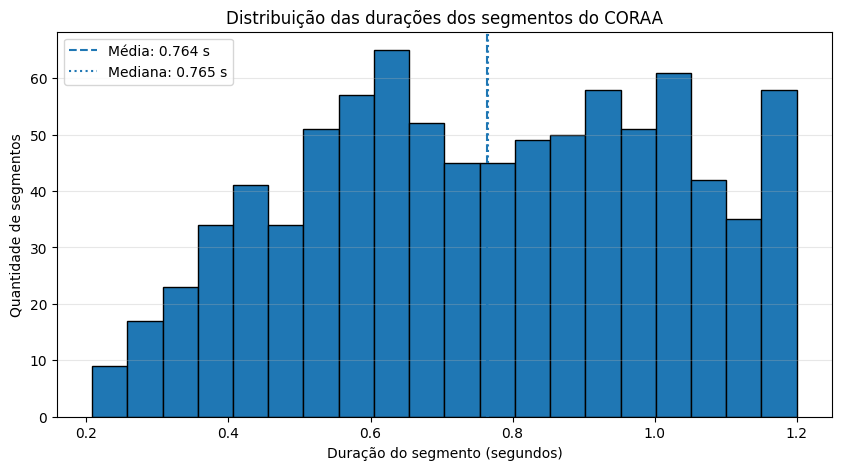

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(duracoes_coraa, bins=20, edgecolor="black")

plt.axvline(
    np.mean(duracoes_coraa),
    linestyle="--",
    label=f"Média: {np.mean(duracoes_coraa):.3f} s"
)

plt.axvline(
    np.median(duracoes_coraa),
    linestyle=":",
    label=f"Mediana: {np.median(duracoes_coraa):.3f} s"
)

plt.xlabel("Duração do segmento (segundos)")
plt.ylabel("Quantidade de segmentos")
plt.title("Distribuição das durações dos segmentos do CORAA")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:

# Comparação da previsão para diferentes durações
# usando o mesmo ponto central da gravação

centro = 5.35
duracoes_teste = [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]

resultados_duracao = []

for duracao in duracoes_teste:
    inicio = max(0, centro - duracao / 2)
    fim = min(len(audio_16k) / 16000, centro + duracao / 2)

    trecho = audio_16k[
        int(inicio * 16000):int(fim * 16000)
    ]

    prob = prever_backchannel(
        trecho,
        16000,
        modelo,
        media_norm,
        desvio_norm,
        maxlen,
        n_mfcc=13,
        target_sr=16000
    )

    resultados_duracao.append({
        "duracao_s": duracao,
        "inicio_s": round(inicio, 2),
        "fim_s": round(fim, 2),
        "probabilidade_%": round(float(prob) * 100, 2)
    })

for resultado in resultados_duracao:
    print(resultado)

{'duracao_s': 0.3, 'inicio_s': 5.2, 'fim_s': 5.5, 'probabilidade_%': 93.02}
{'duracao_s': 0.4, 'inicio_s': 5.15, 'fim_s': 5.55, 'probabilidade_%': 89.81}
{'duracao_s': 0.5, 'inicio_s': 5.1, 'fim_s': 5.6, 'probabilidade_%': 39.48}
{'duracao_s': 0.6, 'inicio_s': 5.05, 'fim_s': 5.65, 'probabilidade_%': 1.41}
{'duracao_s': 0.8, 'inicio_s': 4.95, 'fim_s': 5.75, 'probabilidade_%': 0.54}
{'duracao_s': 1.0, 'inicio_s': 4.85, 'fim_s': 5.85, 'probabilidade_%': 0.35}
{'duracao_s': 1.2, 'inicio_s': 4.75, 'fim_s': 5.95, 'probabilidade_%': 1.29}


Trecho de 5.20 s a 5.50 s


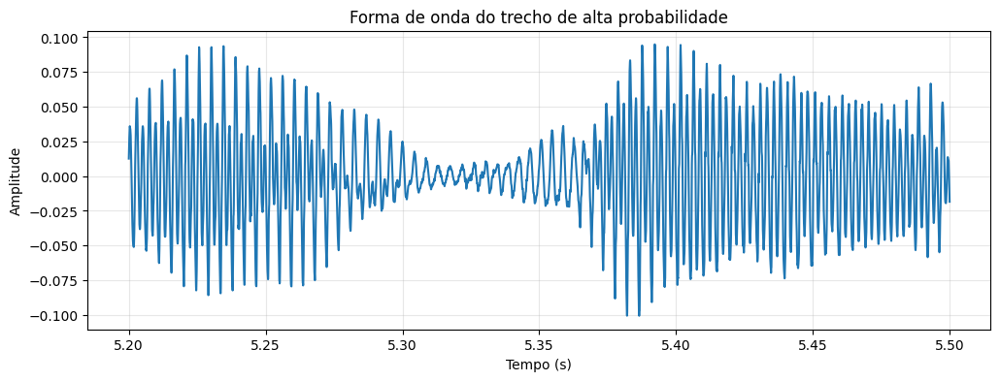

In [ ]:
inicio = 5.2
fim = 5.5

trecho = audio_16k[
    int(inicio * 16000):int(fim * 16000)
]

print(f"Trecho de {inicio:.2f} s a {fim:.2f} s")
display(Audio(trecho, rate=16000))

tempo = inicio + (
    __import__("numpy").arange(len(trecho)) / 16000
)

plt.figure(figsize=(12, 4))
plt.plot(tempo, trecho)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Forma de onda do trecho de alta probabilidade")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("Janela de 0,3 s:")
display(Audio(audio_16k[int(5.2 * 16000):int(5.5 * 16000)], rate=16000))

print("Janela de 0,6 s:")
display(Audio(audio_16k[int(5.05 * 16000):int(5.65 * 16000)], rate=16000))

Janela de 0,3 s:


Janela de 0,6 s:


In [ ]:

# Mantém o início fixo e aumenta o final da janela

inicio = 5.2
finais = [5.5, 5.55, 5.6, 5.65, 5.7, 5.8, 5.9]

for fim in finais:
    trecho = audio_16k[
        int(inicio * 16000):int(fim * 16000)
    ]

    prob = prever_backchannel(
        trecho,
        16000,
        modelo,
        media_norm,
        desvio_norm,
        maxlen,
        n_mfcc=13,
        target_sr=16000
    )

    print(
        f"Janela {inicio:.2f}–{fim:.2f} s "
        f"({fim-inicio:.2f} s): "
        f"{float(prob)*100:.2f}%"
    )

Janela 5.20–5.50 s (0.30 s): 93.01%
Janela 5.20–5.55 s (0.35 s): 92.43%
Janela 5.20–5.60 s (0.40 s): 70.69%
Janela 5.20–5.65 s (0.45 s): 10.66%
Janela 5.20–5.70 s (0.50 s): 1.07%
Janela 5.20–5.80 s (0.60 s): 0.87%
Janela 5.20–5.90 s (0.70 s): 0.84%


In [ ]:
for fim in [5.50, 5.55, 5.60, 5.65, 5.70]:
    print(f"Trecho: 5.20 s até {fim:.2f} s")
    display(
        Audio(
            audio_16k[int(5.20 * 16000):int(fim * 16000)],
            rate=16000
        )
    )

Trecho: 5.20 s até 5.50 s


Trecho: 5.20 s até 5.55 s


Trecho: 5.20 s até 5.60 s


Trecho: 5.20 s até 5.65 s


Trecho: 5.20 s até 5.70 s


In [ ]:
for duracao in [0.30, 0.40, 0.45, 0.50, 0.60]:
    inicio = 5.20
    fim = inicio + duracao

    trecho = audio_16k[
        int(inicio * 16000):int(fim * 16000)
    ].astype(np.float32)

    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    quadros_reais = mfcc.shape[1]
    quadros_preenchidos = max(0, maxlen - quadros_reais)

    print(
        f"{duracao:.2f} s | "
        f"quadros reais: {quadros_reais} | "
        f"quadros preenchidos: {quadros_preenchidos}"
    )

0.30 s | quadros reais: 31 | quadros preenchidos: 90
0.40 s | quadros reais: 41 | quadros preenchidos: 80
0.45 s | quadros reais: 46 | quadros preenchidos: 75
0.50 s | quadros reais: 51 | quadros preenchidos: 70
0.60 s | quadros reais: 61 | quadros preenchidos: 60


In [ ]:
inicio = 5.20
fim = 5.50

trecho_uhum = audio_16k[
    int(inicio * 16000):int(fim * 16000)
].astype(np.float32)

for duracao_alvo in [0.30, 0.40, 0.45, 0.50, 0.60]:
    tamanho_alvo = int(duracao_alvo * 16000)

    if len(trecho_uhum) < tamanho_alvo:
        trecho_teste = np.pad(
            trecho_uhum,
            (0, tamanho_alvo - len(trecho_uhum))
        )
    else:
        trecho_teste = trecho_uhum[:tamanho_alvo]

    prob = prever_backchannel(
        trecho_teste,
        16000,
        modelo,
        media_norm,
        desvio_norm,
        maxlen,
        n_mfcc=13,
        target_sr=16000
    )

    print(
        f"Áudio original de 0,30 s + silêncio até "
        f"{duracao_alvo:.2f} s: {float(prob)*100:.2f}%"
    )

Áudio original de 0,30 s + silêncio até 0.30 s: 93.01%
Áudio original de 0,30 s + silêncio até 0.40 s: 1.45%
Áudio original de 0,30 s + silêncio até 0.45 s: 1.06%
Áudio original de 0,30 s + silêncio até 0.50 s: 1.02%
Áudio original de 0,30 s + silêncio até 0.60 s: 0.89%


In [ ]:
trecho = audio_16k[int(5.20 * 16000):int(5.50 * 16000)].astype(np.float32)

# Extrair MFCCs
mfcc = librosa.feature.mfcc(
    y=trecho,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
).T

# Método A: preencher primeiro, normalizar depois
seq_padded_A = pad_sequences(
    [mfcc],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)
seq_norm_A = (seq_padded_A - media_norm) / desvio_norm

# Método B: normalizar os quadros reais primeiro,
# depois preencher com zeros normalizados
mfcc_norm = (mfcc - media_norm.reshape(13)) / desvio_norm.reshape(13)

seq_norm_B = pad_sequences(
    [mfcc_norm],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post",
    value=0.0
)

# Comparar previsões
prob_A = modelo.predict(seq_norm_A, verbose=0)[0][0]
prob_B = modelo.predict(seq_norm_B, verbose=0)[0][0]

print(f"Método A — preencher antes de normalizar: {prob_A*100:.2f}%")
print(f"Método B — normalizar antes de preencher: {prob_B*100:.2f}%")

Método A — preencher antes de normalizar: 59.11%
Método B — normalizar antes de preencher: 77.48%


In [ ]:
# 1. Selecionar o trecho do "uhum" (5,20 s a 5,50 s)
inicio = 5.20
fim = 5.50

trecho = audio_16k[
    int(inicio * 16000):int(fim * 16000)
].astype(np.float32)

# 2. Normalizar a amplitude do áudio,
# seguindo exatamente a função original de inferência
amplitude_maxima = np.max(np.abs(trecho))

if amplitude_maxima > 0:
    trecho = trecho / amplitude_maxima

# 3. Extrair os MFCCs
mfcc = librosa.feature.mfcc(
    y=trecho,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
).T

print("Formato dos MFCCs:", mfcc.shape)
print("Número de frames reais:", len(mfcc))

# MÉTODO A — preencher primeiro e normalizar depois
sequencia_A = pad_sequences(
    [mfcc],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

sequencia_A = (
    sequencia_A - media_norm
) / desvio_norm

# MÉTODO B — normalizar os frames reais e preencher depois
media_13 = media_norm.reshape(13)
desvio_13 = desvio_norm.reshape(13)

mfcc_normalizados = (
    mfcc - media_13
) / desvio_13

sequencia_B = pad_sequences(
    [mfcc_normalizados],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post",
    value=0.0
)

# 4. Fazer as previsões
probabilidade_A = modelo.predict(
    sequencia_A, verbose=0
)[0][0]

probabilidade_B = modelo.predict(
    sequencia_B, verbose=0
)[0][0]

# 5. Conferir o Método A com a função original
probabilidade_original = prever_backchannel(
    audio_trecho=audio_16k[
        int(inicio * 16000):int(fim * 16000)
    ],
    sr_original=16000,
    modelo=modelo,
    media_norm=media_norm,
    desvio_norm=desvio_norm,
    maxlen=maxlen,
    n_mfcc=13,
    target_sr=16000
)

print("\n--- RESULTADOS ---")
print(f"Função original: {probabilidade_original:.2%}")
print(f"Método A:        {probabilidade_A:.2%}")
print(f"Método B:        {probabilidade_B:.2%}")

Formato dos MFCCs: (31, 13)
Número de frames reais: 31

--- RESULTADOS ---
Função original: 93.01%
Método A:        93.01%
Método B:        78.09%


In [ ]:
# Selecionar o trecho de áudio
inicio = 5.20
fim = 5.50

trecho_original = audio_16k[
    int(inicio * 16000):int(fim * 16000)
].astype(np.float32)

# Normalizar a amplitude, como no treinamento/inferência atual
amplitude_maxima = np.max(np.abs(trecho_original))

if amplitude_maxima > 0:
    trecho_original = trecho_original / amplitude_maxima

# MÉTODO A: pipeline atual (padding)

mfcc_A = librosa.feature.mfcc(
    y=trecho_original,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
).T

entrada_A = pad_sequences(
    [mfcc_A],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

entrada_A = (entrada_A - media_norm) / desvio_norm

prob_A = modelo.predict(entrada_A, verbose=0)[0][0]

# MÉTODO C: ajustar o áudio para 1 segundo

duracao_alvo = 1.0
amostras_alvo = int(duracao_alvo * 16000)

trecho_ajustado = librosa.effects.time_stretch(
    trecho_original,
    rate=len(trecho_original) / amostras_alvo
)

print("Duração original:", round(len(trecho_original) / 16000, 3), "s")
print("Duração ajustada:", round(len(trecho_ajustado) / 16000, 3), "s")

mfcc_C = librosa.feature.mfcc(
    y=trecho_ajustado,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
).T

entrada_C = pad_sequences(
    [mfcc_C],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

entrada_C = (entrada_C - media_norm) / desvio_norm

prob_C = modelo.predict(entrada_C, verbose=0)[0][0]


print("\n--- COMPARAÇÃO ---")
print(f"Método A (padding): {prob_A:.2%}")
print(f"Método C (áudio ajustado): {prob_C:.2%}")

Duração original: 0.3 s
Duração ajustada: 1.0 s

--- COMPARAÇÃO ---
Método A (padding): 93.01%
Método C (áudio ajustado): 9.22%


In [ ]:

print("Áudio original — 0,30 s")
display(Audio(trecho_original, rate=16000))

print("Áudio ajustado — 1,00 s")
display(Audio(trecho_ajustado, rate=16000))

Áudio original — 0,30 s


Áudio ajustado — 1,00 s


In [ ]:
# 1. Selecionar o trecho do "uhum"
inicio = 5.20
fim = 5.50

trecho = audio_16k[
    int(inicio * 16000):int(fim * 16000)
].astype(np.float32)

# 2. Normalizar a amplitude, como na inferência atual
amplitude_maxima = np.max(np.abs(trecho))

if amplitude_maxima > 0:
    trecho = trecho / amplitude_maxima

# 3. Extrair os MFCCs
mfcc = librosa.feature.mfcc(
    y=trecho,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
)

print("Formato dos MFCCs:", mfcc.shape)

Formato dos MFCCs: (13, 31)


In [ ]:

# Calcular estatísticas ao longo do tempo
media_mfcc = np.mean(mfcc, axis=1)
desvio_mfcc = np.std(mfcc, axis=1)

# Concatenar em um único vetor
caracteristicas = np.concatenate([
    media_mfcc,
    desvio_mfcc
])

print("Quantidade de características:", len(caracteristicas))
print("Formato do vetor:", caracteristicas.shape)

print("\nMédias dos MFCCs:")
print(np.round(media_mfcc, 3))

print("\nDesvios-padrão dos MFCCs:")
print(np.round(desvio_mfcc, 3))

Quantidade de características: 26
Formato do vetor: (26,)

Médias dos MFCCs:
[-3.19989e+02  1.22551e+02 -1.90820e+01  4.78280e+01  1.57420e+01
 -2.63860e+01 -2.76410e+01 -4.51290e+01 -2.76260e+01 -1.04770e+01
 -1.58120e+01 -1.61170e+01 -1.01000e-01]

Desvios-padrão dos MFCCs:
[52.541 12.11  16.51  10.71  14.86   8.43   8.145 10.495  6.206  5.283
  7.988  5.419  9.601]


In [ ]:

# Verificar variáveis relacionadas aos dados de treinamento

variaveis_interesse = [
    "X", "y",
    "X_train", "X_test",
    "y_train", "y_test",
    "audios", "labels",
    "dados", "amostras",
    "candidatos", "df"
]

for nome in variaveis_interesse:
    if nome in globals():
        valor = globals()[nome]

        print(f"\n{nome}:")
        print("Tipo:", type(valor))

        if hasattr(valor, "shape"):
            print("Formato:", valor.shape)
        elif hasattr(valor, "__len__"):
            print("Quantidade:", len(valor))

In [ ]:

# Mostrar variáveis relacionadas a dados, áudio e treinamento

for nome in sorted(globals().keys()):
    if not nome.startswith("_"):
        if any(palavra in nome.lower() for palavra in [
            "audio", "label", "train", "test",
            "dataset", "amostra", "candidato",
            "mfcc", "modelo", "backchannel", "caminho"
        ]):
            valor = globals()[nome]
            print(nome, "->", type(valor).__name__)

Audio -> type
amostras_alvo -> int
arquivos_audio -> list
audio -> ndarray
audio_16k -> ndarray
caminho -> str
caminho_modelo -> str
caminho_notebook -> str
caminho_parametros -> str
caminho_projeto -> str
duracoes_teste -> list
entrada_modelo -> ndarray
fim_amostra -> int
fim_teste -> int
inicio_amostra -> int
inicio_teste -> int
load_dataset -> function
mfcc -> ndarray
mfcc_A -> ndarray
mfcc_C -> ndarray
mfcc_norm -> ndarray
mfcc_norm_reais -> ndarray
mfcc_normalizados -> ndarray
mfcc_reais -> ndarray
mfcc_sequencia -> ndarray
mfcc_teste -> ndarray
mfcc_trecho -> ndarray
modelo -> Functional
n_mfcc -> int
nome_audio -> str
passo_amostras -> int
pasta_backchannel -> str
prever_backchannel -> function
sr_modelo -> int
tamanho_amostra -> int
tempos_teste -> ndarray
testar_janela -> function
train_test_split -> function
trecho_audio -> ndarray
trecho_mfcc -> ndarray
trecho_teste -> ndarray


In [ ]:
print("Caminho do notebook:")
print(caminho_notebook)

print("\nArquivo existe?", os.path.exists(caminho_notebook))

if os.path.exists(caminho_notebook):
    notebook_original = nbformat.read(
        caminho_notebook,
        as_version=4
    )

    print("\nQuantidade de células:",
          len(notebook_original.cells))

    print("\nCélulas relacionadas aos dados e rótulos:\n")

    termos = [
        "label", "labels", "backchannel",
        "coraa", "candidato", "treino",
        "train_test_split", "mfcc",
        "X_train", "y_train"
    ]

    for i, celula in enumerate(notebook_original.cells):
        if celula.cell_type == "code":
            codigo = celula.source
            if any(termo.lower() in codigo.lower()
                   for termo in termos):
                print(f"\n--- Célula {i} ---")
                print(codigo[:1800])

Caminho do notebook:
/content/drive/MyDrive/IC - CTI Renato Archer/LSTM_Backchannel.ipynb

Arquivo existe? True

Quantidade de células: 42

Células relacionadas aos dados e rótulos:


--- Célula 1 ---
import numpy as np
import pandas as pd
import librosa
import random
import os
import pickle
import IPython.display as ipd
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Dropout
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.sequence import pad_sequences

--- Célula 3 ---
from datasets import load_dataset

ds_coraa = load_dataset("Racoci/CORAA-v1.1", split="train", streaming=True)

for i, exemplo in enumerate(ds_coraa):
    print(exemplo.keys())
    print({k: v for k, v in exemplo.items() if k != "audio"})
    if i >= 3:
        break

--- Célula 5 ---
for i, exemplo in enumerate(ds_coraa):
    print(type(exemplo['audi

In [ ]:

termos = [
    "X_audio_treino",
    "X_audio_teste",
    "y_treino",
    "y_teste",
    "media_coraa",
    "desvio_coraa",
    "maxlen_coraa",
    "train_test_split"
]

for i, celula in enumerate(notebook_original.cells):
    if celula.cell_type == "code":
        codigo = celula.source
        encontrados = [
            termo for termo in termos
            if termo in codigo
        ]

        if encontrados:
            print(f"\n{'='*60}")
            print(f"CÉLULA {i} | Encontrados: {encontrados}")
            print(codigo)


CÉLULA 1 | Encontrados: ['train_test_split']
import numpy as np
import pandas as pd
import librosa
import random
import os
import pickle
import IPython.display as ipd
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Dropout
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.sequence import pad_sequences

CÉLULA 25 | Encontrados: ['media_coraa', 'desvio_coraa', 'maxlen_coraa']
maxlen_coraa = 121

X_audio_coraa = pad_sequences(sequencias_coraa, maxlen=maxlen_coraa, dtype='float32', padding='post', truncating='post')
print("Shape X_audio_coraa:", X_audio_coraa.shape)

media_coraa = X_audio_coraa.mean(axis=(0,1), keepdims=True)
desvio_coraa = X_audio_coraa.std(axis=(0,1), keepdims=True) + 1e-8
X_audio_coraa_norm = (X_audio_coraa - media_coraa) / desvio_coraa

CÉLULA 29 | Encontrados: ['X_audio_treino', 'X_audio_teste', 'y_t

In [ ]:

for i, celula in enumerate(notebook_original.cells):
    if celula.cell_type == "code":
        codigo = celula.source

        if "sequencias_coraa" in codigo:
            print(f"\n{'='*60}")
            print(f"CÉLULA {i}")
            print(codigo)


CÉLULA 23
def extrair_mfcc_sequencia_coraa(audio_arr, sr_original, target_sr=16000, n_mfcc=13):
    audio_f = audio_arr.astype(np.float32)
    if np.max(np.abs(audio_f)) > 0:
        audio_f = audio_f / np.max(np.abs(audio_f))

    if sr_original != target_sr:
        audio_f = librosa.resample(audio_f, orig_sr=sr_original, target_sr=target_sr)

    mfcc = librosa.feature.mfcc(y=audio_f, sr=target_sr, n_mfcc=n_mfcc, hop_length=160, n_fft=400)
    return mfcc.T  # (n_frames, n_mfcc)

# Mapeia idx -> audio_array/sample_rate a partir da lista original
mapa_audio = {c["idx"]: (c["audio_array"], c["sample_rate"]) for c in candidatos_coraa}

sequencias_coraa = []
for _, row in df_coraa_candidatos.iterrows():
    audio_arr, sr_original = mapa_audio[row["idx"]]
    seq = extrair_mfcc_sequencia_coraa(audio_arr, sr_original)
    sequencias_coraa.append(seq)

comprimentos = [s.shape[0] for s in sequencias_coraa]
print(f"Comprimentos: min={min(comprimentos)}, max={max(comprimentos)}, média={np.me

In [ ]:

variaveis_necessarias = [
    "candidatos_coraa",
    "df_coraa_candidatos",
    "y_coraa",
    "idx_treino",
    "idx_teste"
]

for nome in variaveis_necessarias:
    existe = nome in globals()
    print(f"{nome}: {'disponível' if existe else 'não encontrada'}")

if "candidatos_coraa" in globals():
    print("\nQuantidade de candidatos:", len(candidatos_coraa))

if "df_coraa_candidatos" in globals():
    print("Quantidade de linhas no DataFrame:", len(df_coraa_candidatos))

candidatos_coraa: não encontrada
df_coraa_candidatos: não encontrada
y_coraa: não encontrada
idx_treino: não encontrada
idx_teste: não encontrada


In [ ]:

termos = [
    "candidatos_coraa",
    "df_coraa_candidatos",
    "y_coraa",
    "backchannel",
    "CORAA",
]

for i, celula in enumerate(notebook_original.cells):
    if celula.cell_type != "code":
        continue

    codigo = celula.source
    linhas = codigo.lower()

    encontrados = [
        termo for termo in termos
        if termo.lower() in linhas
    ]

    # Mostra as células que parecem preparar os dados,
    # evitando repetir as células de treinamento e avaliação.
    if encontrados and i < 25:
        print(f"\n{'='*60}")
        print(f"CÉLULA {i} | Termos: {encontrados}")
        print(codigo)


CÉLULA 3 | Termos: ['CORAA']
from datasets import load_dataset

ds_coraa = load_dataset("Racoci/CORAA-v1.1", split="train", streaming=True)

for i, exemplo in enumerate(ds_coraa):
    print(exemplo.keys())
    print({k: v for k, v in exemplo.items() if k != "audio"})
    if i >= 3:
        break

CÉLULA 5 | Termos: ['CORAA']
for i, exemplo in enumerate(ds_coraa):
    print(type(exemplo['audio']))
    print(exemplo['audio'])
    break

CÉLULA 7 | Termos: ['backchannel']
lexico_backchannel = [
    "uhum", "ahã", "aham", "hum", "hmm", "mm", "mhm", "uh",
    "sim", "é", "tá", "ta", "ok", "certo", "exato", "isso",
    "entendi", "sei", "verdade", "nossa", "sério", "uau",
    "certeza", "com certeza", "claro"
]

def eh_candidato_lexico(texto, lexico):
    texto_limpo = texto.lower().strip().strip(".,!?")
    return texto_limpo in lexico

print("Setup concluído.")

CÉLULA 9 | Termos: ['candidatos_coraa', 'df_coraa_candidatos', 'backchannel', 'CORAA']
tamanho_amostra = 3000
duracao_maxima_bac

In [ ]:

for i, celula in enumerate(notebook_original.cells):
    if celula.cell_type != "code" or i >= 19:
        continue

    codigo = celula.source
    termos = [
        "candidatos_coraa",
        "df_coraa_candidatos",
        "audio_array",
        "sample_rate",
        "read_csv",
        "load_dataset",
        "iterrows",
        "duracao",
        "duration",
    ]

    encontrados = [
        termo for termo in termos
        if termo.lower() in codigo.lower()
    ]

    if encontrados:
        print(f"\n{'='*60}")
        print(f"CÉLULA {i} | {encontrados}")
        print(codigo)


CÉLULA 3 | ['load_dataset']
from datasets import load_dataset

ds_coraa = load_dataset("Racoci/CORAA-v1.1", split="train", streaming=True)

for i, exemplo in enumerate(ds_coraa):
    print(exemplo.keys())
    print({k: v for k, v in exemplo.items() if k != "audio"})
    if i >= 3:
        break

CÉLULA 9 | ['candidatos_coraa', 'df_coraa_candidatos', 'audio_array', 'sample_rate', 'duracao', 'duration']
tamanho_amostra = 3000
duracao_maxima_backchannel_coraa = 1.2

candidatos_coraa = []

for i, exemplo in enumerate(ds_coraa):
    if i >= tamanho_amostra:
        break

    samples = exemplo['audio'].get_all_samples()
    duracao = samples.duration_seconds

    if duracao <= duracao_maxima_backchannel_coraa and duracao > 0.2:
        texto = exemplo['text'].strip()
        candidatos_coraa.append({
            "idx": i,
            "texto": texto,
            "duracao": duracao,
            "genero": exemplo['speech_genre'],
            "dataset_origem": exemplo['dataset'],
            "

In [ ]:

for i in range(2, 13):
    celula = notebook_original.cells[i]

    if celula.cell_type == "code":
        print(f"\n{'='*60}")
        print(f"CÉLULA {i}")
        print(celula.source)


CÉLULA 3
from datasets import load_dataset

ds_coraa = load_dataset("Racoci/CORAA-v1.1", split="train", streaming=True)

for i, exemplo in enumerate(ds_coraa):
    print(exemplo.keys())
    print({k: v for k, v in exemplo.items() if k != "audio"})
    if i >= 3:
        break

CÉLULA 5
for i, exemplo in enumerate(ds_coraa):
    print(type(exemplo['audio']))
    print(exemplo['audio'])
    break

CÉLULA 7
lexico_backchannel = [
    "uhum", "ahã", "aham", "hum", "hmm", "mm", "mhm", "uh",
    "sim", "é", "tá", "ta", "ok", "certo", "exato", "isso",
    "entendi", "sei", "verdade", "nossa", "sério", "uau",
    "certeza", "com certeza", "claro"
]

def eh_candidato_lexico(texto, lexico):
    texto_limpo = texto.lower().strip().strip(".,!?")
    return texto_limpo in lexico

print("Setup concluído.")

CÉLULA 9
tamanho_amostra = 3000
duracao_maxima_backchannel_coraa = 1.2

candidatos_coraa = []

for i, exemplo in enumerate(ds_coraa):
    if i >= tamanho_amostra:
        break

    samples = ex

In [ ]:

print("Dataset disponível:", "ds_coraa" in globals())
print("Modelo salvo:", os.path.exists(caminho_modelo))
print("Parâmetros salvos:", os.path.exists(caminho_parametros))

if "ds_coraa" in globals():
    print("Tipo do dataset:", type(ds_coraa))

print("\nVariáveis atuais relacionadas ao CORAA:")
for nome in [
    "candidatos_coraa",
    "df_coraa_candidatos",
    "sequencias_coraa",
    "y_coraa",
    "idx_treino",
    "idx_teste"
]:
    print(f"{nome}: {nome in globals()}")

Dataset disponível: False
Modelo salvo: True
Parâmetros salvos: True

Variáveis atuais relacionadas ao CORAA:
candidatos_coraa: False
df_coraa_candidatos: False
sequencias_coraa: False
y_coraa: False
idx_treino: False
idx_teste: False


In [ ]:

try:
    from datasets import load_dataset

    ds_coraa = load_dataset(
        "Racoci/CORAA-v1.1",
        split="train",
        streaming=True
    )

    print("Dataset carregado com sucesso!")

except Exception as erro:
    print("Não foi possível carregar o dataset.")
    print("Erro:", repr(erro))

Resolving data files:   0%|          | 0/127 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/127 [00:00<?, ?it/s]

Dataset carregado com sucesso!


In [ ]:

# Função para verificar se a transcrição corresponde
# a uma expressão da lista de backchannels

lexico_backchannel = [
    "uhum", "ahã", "aham", "hum", "hmm", "mm", "mhm", "uh",
    "sim", "é", "tá", "ta", "ok", "certo", "exato", "isso",
    "entendi", "sei", "verdade", "nossa", "sério", "uau",
    "certeza", "com certeza", "claro"
]

def eh_candidato_lexico(texto, lexico):
    texto_limpo = texto.lower().strip().strip(".,!?")
    return texto_limpo in lexico

print("Função e léxico carregados com sucesso!")

Função e léxico carregados com sucesso!


In [ ]:
# Mantém os mesmos parâmetros do notebook original
tamanho_amostra = 3000
duracao_maxima_backchannel_coraa = 1.2

candidatos_coraa = []

for i, exemplo in enumerate(ds_coraa):
    if i >= tamanho_amostra:
        break

    samples = exemplo["audio"].get_all_samples()
    duracao = samples.duration_seconds

    if 0.2 < duracao <= duracao_maxima_backchannel_coraa:
        texto = exemplo["text"].strip()

        candidatos_coraa.append({
            "idx": i,
            "texto": texto,
            "duracao": duracao,
            "genero": exemplo["speech_genre"],
            "dataset_origem": exemplo["dataset"],
            "sample_rate": samples.sample_rate,
            "audio_array": samples.data.numpy().squeeze(),
            "candidato_lexico": eh_candidato_lexico(
                texto, lexico_backchannel
            )
        })

    if (i + 1) % 500 == 0:
        print(
            f"{i+1}/{tamanho_amostra} exemplos verificados; "
            f"{len(candidatos_coraa)} candidatos encontrados"
        )

df_coraa_candidatos = pd.DataFrame([
    {k: v for k, v in c.items() if k != "audio_array"}
    for c in candidatos_coraa
])

print("\nTotal de candidatos:", len(candidatos_coraa))
print(
    "Candidatos positivos pelo léxico:",
    int(df_coraa_candidatos["candidato_lexico"].sum())
)

500/3000 exemplos verificados; 141 candidatos encontrados
1000/3000 exemplos verificados; 247 candidatos encontrados
1500/3000 exemplos verificados; 402 candidatos encontrados
2000/3000 exemplos verificados; 537 candidatos encontrados
2500/3000 exemplos verificados; 724 candidatos encontrados
3000/3000 exemplos verificados; 877 candidatos encontrados

Total de candidatos: 877
Candidatos positivos pelo léxico: 250


In [ ]:

# Adicionar as expressões incluídas na versão anterior
lexico_backchannel = list(set(
    lexico_backchannel + ["né", "ne", "eh", "éh"]
))

# Recalcular os rótulos
df_coraa_candidatos["candidato_lexico"] = (
    df_coraa_candidatos["texto"].apply(
        lambda texto: eh_candidato_lexico(
            texto, lexico_backchannel
        )
    )
)

df_coraa_candidatos["backchannel"] = (
    df_coraa_candidatos["candidato_lexico"].astype(int)
)

# Reconstruir o vetor de rótulos
y_coraa = df_coraa_candidatos["backchannel"].to_numpy()

print("Total de candidatos:", len(df_coraa_candidatos))
print("Backchannels positivos:", int(y_coraa.sum()))
print("Não backchannels:", int((y_coraa == 0).sum()))

Total de candidatos: 877
Backchannels positivos: 303
Não backchannels: 574


In [ ]:
def extrair_mfcc_estatistico(
    audio_arr,
    sr_original,
    target_sr=16000,
    n_mfcc=13
):
    # Converter o áudio para float32
    audio_f = audio_arr.astype(np.float32)

    # Normalizar a amplitude, como no pipeline original
    if np.max(np.abs(audio_f)) > 0:
        audio_f = audio_f / np.max(np.abs(audio_f))

    # Converter para 16 kHz
    if sr_original != target_sr:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_original,
            target_sr=target_sr
        )

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=target_sr,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    # Calcular estatísticas ao longo do tempo
    medias = np.mean(mfcc, axis=1)
    desvios = np.std(mfcc, axis=1)

    # Concatenar: 13 médias + 13 desvios = 26 características
    return np.concatenate([medias, desvios])


# Recuperar os áudios já selecionados
mapa_audio = {
    c["idx"]: (c["audio_array"], c["sample_rate"])
    for c in candidatos_coraa
}

# Extrair as características de todos os candidatos
X_estatistico = []

for i, (_, linha) in enumerate(df_coraa_candidatos.iterrows()):
    audio_arr, sr_original = mapa_audio[linha["idx"]]

    vetor = extrair_mfcc_estatistico(
        audio_arr,
        sr_original
    )

    X_estatistico.append(vetor)

X_estatistico = np.array(X_estatistico, dtype=np.float32)

print("Formato da matriz:", X_estatistico.shape)
print("Quantidade de rótulos:", len(y_coraa))
print("Valores ausentes:", np.isnan(X_estatistico).sum())

Formato da matriz: (877, 26)
Quantidade de rótulos: 877
Valores ausentes: 0


In [ ]:
# Separar os índices de treino e teste
indices = np.arange(len(y_coraa))

idx_treino, idx_teste = train_test_split(
    indices,
    test_size=0.2,
    stratify=y_coraa,
    random_state=42
)

X_treino = X_estatistico[idx_treino]
X_teste = X_estatistico[idx_teste]

y_treino = y_coraa[idx_treino]
y_teste = y_coraa[idx_teste]

# Pipeline: padronização + regressão logística
# O scaler é ajustado somente com os dados de treino
modelo_estatistico = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

# Treinar o classificador estatístico
modelo_estatistico.fit(X_treino, y_treino)

# Avaliar no conjunto de teste
y_pred = modelo_estatistico.predict(X_teste)

print("Acurácia:", round(accuracy_score(y_teste, y_pred), 4))
print(
    "Acurácia balanceada:",
    round(balanced_accuracy_score(y_teste, y_pred), 4)
)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_teste,
        y_pred,
        target_names=["Não backchannel", "Backchannel"],
        digits=4
    )
)

print("Matriz de confusão:")
print(confusion_matrix(y_teste, y_pred))

Acurácia: 0.8693
Acurácia balanceada: 0.8808

Relatório de classificação:
                 precision    recall  f1-score   support

Não backchannel     0.9510    0.8435    0.8940       115
    Backchannel     0.7568    0.9180    0.8296        61

       accuracy                         0.8693       176
      macro avg     0.8539    0.8808    0.8618       176
   weighted avg     0.8837    0.8693    0.8717       176

Matriz de confusão:
[[97 18]
 [ 5 56]]


In [ ]:
caminho_projeto = (
    "/content/drive/MyDrive/"
    "speaker-pause-detection/backchannel-lstm"
)

caminho_modelo = os.path.join(
    caminho_projeto, "modelo_backchannel_audio.keras"
)

caminho_parametros = os.path.join(
    caminho_projeto, "parametros_normalizacao.pkl"
)

print("Modelo encontrado:", os.path.exists(caminho_modelo))
print("Parâmetros encontrados:", os.path.exists(caminho_parametros))

Modelo encontrado: True
Parâmetros encontrados: True


In [ ]:

modelo = tf.keras.models.load_model(caminho_modelo)

with open(caminho_parametros, "rb") as arquivo:
    parametros = pickle.load(arquivo)

media_norm = parametros["media"]
desvio_norm = parametros["desvio"]
maxlen = parametros["maxlen"]
n_mfcc = parametros["n_mfcc"]

print("Modelo carregado!")
print("Entrada esperada:", modelo.input_shape)
print("Média:", np.shape(media_norm))
print("Desvio:", np.shape(desvio_norm))
print("maxlen:", maxlen)
print("n_mfcc:", n_mfcc)

Modelo carregado!
Entrada esperada: (None, 121, 13)
Média: (1, 1, 13)
Desvio: (1, 1, 13)
maxlen: 121
n_mfcc: 13


In [ ]:

print("Quantidade de exemplos de teste:", len(idx_teste))
print("Formato do teste estatístico:", X_teste.shape)
print("Formato dos rótulos:", y_teste.shape)

print("\nDistribuição real das classes:")
print("Não backchannel:", int((y_teste == 0).sum()))
print("Backchannel:", int((y_teste == 1).sum()))

Quantidade de exemplos de teste: 176
Formato do teste estatístico: (176, 26)
Formato dos rótulos: (176,)

Distribuição real das classes:
Não backchannel: 115
Backchannel: 61


In [ ]:
def extrair_sequencia_mfcc(
    audio_arr,
    sr_original,
    target_sr=16000,
    n_mfcc=13
):
    audio_f = audio_arr.astype(np.float32)

    # Mesma normalização de amplitude usada no treinamento
    if np.max(np.abs(audio_f)) > 0:
        audio_f = audio_f / np.max(np.abs(audio_f))

    if sr_original != target_sr:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_original,
            target_sr=target_sr
        )

    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=target_sr,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    return mfcc.T.astype(np.float32)


# Recuperar as sequências dos mesmos exemplos de teste
sequencias_teste_lstm = []

for indice in idx_teste:
    idx_original = int(df_coraa_candidatos.iloc[indice]["idx"])
    audio_arr, sr_original = mapa_audio[idx_original]

    sequencia = extrair_sequencia_mfcc(
        audio_arr,
        sr_original,
        n_mfcc=n_mfcc
    )

    sequencias_teste_lstm.append(sequencia)

# Aplicar o mesmo padding usado no treinamento
X_teste_lstm = pad_sequences(
    sequencias_teste_lstm,
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

# Aplicar os parâmetros originais de normalização
X_teste_lstm = (
    X_teste_lstm - media_norm
) / desvio_norm

print("Formato para a LSTM:", X_teste_lstm.shape)
print("Valores ausentes:", np.isnan(X_teste_lstm).sum())
print("Valores infinitos:", np.isinf(X_teste_lstm).sum())

Formato para a LSTM: (176, 121, 13)
Valores ausentes: 0
Valores infinitos: 0


In [ ]:
# Previsões com a LSTM já treinada
probabilidades_lstm = modelo.predict(
    X_teste_lstm,
    verbose=0
).ravel()

# Converter probabilidades em classes usando limiar 0.5
y_pred_lstm = (probabilidades_lstm >= 0.5).astype(int)

print("Acurácia:", round(
    accuracy_score(y_teste, y_pred_lstm), 4
))

print("Acurácia balanceada:", round(
    balanced_accuracy_score(y_teste, y_pred_lstm), 4
))

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred_lstm,
    target_names=["Não backchannel", "Backchannel"],
    digits=4
))

print("Matriz de confusão:")
print(confusion_matrix(y_teste, y_pred_lstm))

Acurácia: 0.8466
Acurácia balanceada: 0.848

Relatório de classificação:
                 precision    recall  f1-score   support

Não backchannel     0.9151    0.8435    0.8778       115
    Backchannel     0.7429    0.8525    0.7939        61

       accuracy                         0.8466       176
      macro avg     0.8290    0.8480    0.8359       176
   weighted avg     0.8554    0.8466    0.8487       176

Matriz de confusão:
[[97 18]
 [ 9 52]]


In [ ]:
# Montar tabela dos exemplos de teste
dados_teste = []

for posicao, indice in enumerate(idx_teste):
    linha = df_coraa_candidatos.iloc[int(indice)]

    dados_teste.append({
        "duracao": float(linha["duracao"]),
        "real": int(y_teste[posicao]),
        "LSTM": int(y_pred_lstm[posicao]),
        "MFCC_estatistico": int(y_pred[posicao])
    })

df_comparacao = pd.DataFrame(dados_teste)

# Agrupar os áudios por duração
faixas = [0.2, 0.4, 0.7, 1.200001]
rotulos = ["Curtos (0,2–0,4 s)", "Médios (0,4–0,7 s)", "Longos (0,7–1,2 s)"]

df_comparacao["faixa_duracao"] = pd.cut(
    df_comparacao["duracao"],
    bins=faixas,
    labels=rotulos,
    right=False,
    include_lowest=True
)

# Avaliar cada modelo em cada faixa
resultados = []

for faixa in rotulos:
    grupo = df_comparacao[
        df_comparacao["faixa_duracao"] == faixa
    ]

    if len(grupo) == 0:
        continue

    y_real = grupo["real"].to_numpy()

    for nome_modelo in ["LSTM", "MFCC_estatistico"]:
        y_previsto = grupo[nome_modelo].to_numpy()

        resultados.append({
            "Faixa": faixa,
            "Modelo": nome_modelo,
            "Amostras": len(grupo),
            "Backchannels reais": int(y_real.sum()),
            "Acurácia": round(
                accuracy_score(y_real, y_previsto), 3
            ),
            "Acurácia balanceada": round(
                balanced_accuracy_score(y_real, y_previsto), 3
            ) if len(np.unique(y_real)) == 2 else np.nan,
            "Recall backchannel": round(
                recall_score(y_real, y_previsto, zero_division=0), 3
            ),
            "F1 backchannel": round(
                f1_score(y_real, y_previsto, zero_division=0), 3
            )
        })

df_resultados_duracao = pd.DataFrame(resultados)

print("Quantidade de áudios por faixa:")
print(
    df_comparacao.groupby(
        "faixa_duracao", observed=False
    ).size()
)

print("\nComparação por duração:")
display(df_resultados_duracao)

Quantidade de áudios por faixa:
faixa_duracao
Curtos (0,2–0,4 s)     9
Médios (0,4–0,7 s)    69
Longos (0,7–1,2 s)    98
dtype: int64

Comparação por duração:


,Faixa,Modelo,Amostras,Backchannels reais,Acurácia,Acurácia balanceada,Recall backchannel,F1 backchannel
0,"Curtos (0,2–0,4 s)",LSTM,9,9,0.889,NaN,0.889,0.941
1,"Curtos (0,2–0,4 s)",MFCC_estatistico,9,9,1.000,NaN,1.000,1.000
2,"Médios (0,4–0,7 s)",LSTM,69,40,0.783,0.775,0.825,0.815
3,"Médios (0,4–0,7 s)",MFCC_estatistico,69,40,0.884,0.881,0.900,0.900
4,"Longos (0,7–1,2 s)",LSTM,98,12,0.888,0.900,0.917,0.667
5,"Longos (0,7–1,2 s)",MFCC_estatistico,98,12,0.847,0.877,0.917,0.595


In [ ]:

from google.colab import files

arquivos_enviados = files.upload()


Saving Dois falantes 2.m4a to Dois falantes 2.m4a


In [ ]:
nome_audio = "Dois falantes 2.m4a"
caminho_audio = os.path.abspath(nome_audio)

audio_dois_falantes, sr_original = librosa.load(
    caminho_audio,
    sr=None,
    mono=True
)

duracao_audio = len(audio_dois_falantes) / sr_original

print("Arquivo:", nome_audio)
print("Taxa de amostragem:", sr_original, "Hz")
print("Duração:", round(duracao_audio, 2), "segundos")
print("Formato do sinal:", audio_dois_falantes.shape)


/tmp/ipykernel_1853/1870095409.py:4: UserWarning: PySoundFile failed. Trying audioread instead.
  audio_dois_falantes, sr_original = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Arquivo: Dois falantes 2.m4a
Taxa de amostragem: 48000 Hz
Duração: 22.72 segundos
Formato do sinal: (1090560,)


In [ ]:

# Converter o áudio para 16 kHz, como no treinamento da LSTM
sr_alvo = 16000

audio_16k = librosa.resample(
    audio_dois_falantes,
    orig_sr=sr_original,
    target_sr=sr_alvo
)

duracao_16k = len(audio_16k) / sr_alvo

print("Taxa de amostragem após conversão:", sr_alvo, "Hz")
print("Duração após conversão:", round(duracao_16k, 2), "segundos")
print("Quantidade de amostras:", len(audio_16k))

display(Audio(audio_16k, rate=sr_alvo))


Taxa de amostragem após conversão: 16000 Hz
Duração após conversão: 22.72 segundos
Quantidade de amostras: 363520


In [ ]:
# Caminho dos arquivos salvos no Google Drive
pasta_modelo = (
    "/content/drive/MyDrive/"
    "speaker-pause-detection/backchannel-lstm"
)

caminho_lstm = os.path.join(
    pasta_modelo, "modelo_backchannel_audio.keras"
)

caminho_parametros = os.path.join(
    pasta_modelo, "parametros_normalizacao.pkl"
)

# Verificar se o Google Drive está montado
print("Modelo LSTM encontrado:", os.path.exists(caminho_lstm))
print("Parâmetros encontrados:", os.path.exists(caminho_parametros))


Modelo LSTM encontrado: True
Parâmetros encontrados: True


In [ ]:

# Carregar a LSTM e os parâmetros utilizados no treinamento
modelo_lstm = load_model(caminho_lstm)

with open(caminho_parametros, "rb") as arquivo:
    parametros = pickle.load(arquivo)

media_norm = parametros["media"]
desvio_norm = parametros["desvio"]
maxlen = parametros["maxlen"]
n_mfcc = parametros["n_mfcc"]

print("Modelo carregado.")
print("Formato esperado:", modelo_lstm.input_shape)
print("maxlen:", maxlen)
print("n_mfcc:", n_mfcc)
print("Formato da média:", media_norm.shape)
print("Formato do desvio:", desvio_norm.shape)


Modelo carregado.
Formato esperado: (None, 121, 13)
maxlen: 121
n_mfcc: 13
Formato da média: (1, 1, 13)
Formato do desvio: (1, 1, 13)


In [ ]:
# Configurações utilizadas no teste anterior
tamanho_janela = 1.21
passo = 0.1
sr_alvo = 16000

# Garantir que o áudio esteja em float32
audio = audio_16k.astype(np.float32)

# Normalizar a amplitude do áudio completo
if np.max(np.abs(audio)) > 0:
    audio = audio / np.max(np.abs(audio))

# Criar janelas deslizantes
amostras_janela = int(tamanho_janela * sr_alvo)
amostras_passo = int(passo * sr_alvo)

resultados_lstm = []

for inicio_amostra in range(
    0,
    len(audio) - amostras_janela + 1,
    amostras_passo
):
    fim_amostra = inicio_amostra + amostras_janela
    trecho = audio[inicio_amostra:fim_amostra]

    # Extrair os MFCCs seguindo a configuração do treinamento
    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=sr_alvo,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc.T

    # Ajustar a sequência ao formato esperado pela LSTM
    sequencia_preenchida = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    # Aplicar os parâmetros de normalização salvos
    sequencia_normalizada = (
        sequencia_preenchida - media_norm
    ) / desvio_norm

    # Prever a probabilidade de backchannel
    probabilidade = float(
        modelo_lstm.predict(
            sequencia_normalizada,
            verbose=0
        )[0][0]
    )

    resultados_lstm.append({
        "inicio_s": inicio_amostra / sr_alvo,
        "fim_s": fim_amostra / sr_alvo,
        "probabilidade": probabilidade
    })

df_resultados_lstm = pd.DataFrame(resultados_lstm)

df_resultados_lstm["probabilidade_pct"] = (
    df_resultados_lstm["probabilidade"] * 100
)

print("Janelas analisadas:", len(df_resultados_lstm))
print("Duração do áudio:", round(len(audio) / sr_alvo, 2), "s")

display(
    df_resultados_lstm
    .sort_values("probabilidade", ascending=False)
    .head(20)
    .round(3)
)


Janelas analisadas: 216
Duração do áudio: 22.72 s


,inicio_s,fim_s,probabilidade,probabilidade_pct
55,5.5,6.71,0.575,57.509
54,5.4,6.61,0.550,55.047
172,17.2,18.41,0.528,52.777
36,3.6,4.81,0.524,52.433
173,17.3,18.51,0.506,50.623
174,17.4,18.61,0.494,49.431
175,17.5,18.71,0.485,48.514
183,18.3,19.51,0.473,47.271
86,8.6,9.81,0.463,46.329
141,14.1,15.31,0.454,45.397


In [ ]:
# Trechos identificados pela LSTM
trechos_para_ouvir = [
    (2.8, 5.2, "Trecho próximo de 3,6 s"),
    (4.7, 7.2, "Trecho próximo de 5,5 s"),
    (16.4, 19.8, "Trecho próximo de 17,2 s")
]

for inicio, fim, descricao in trechos_para_ouvir:
    print(f"{descricao} — {inicio:.1f}s a {fim:.1f}s")

    trecho = audio_16k[
        int(inicio * sr_alvo):int(fim * sr_alvo)
    ]

    display(Audio(trecho, rate=sr_alvo))


Trecho próximo de 3,6 s — 2.8s a 5.2s


Trecho próximo de 5,5 s — 4.7s a 7.2s


Trecho próximo de 17,2 s — 16.4s a 19.8s


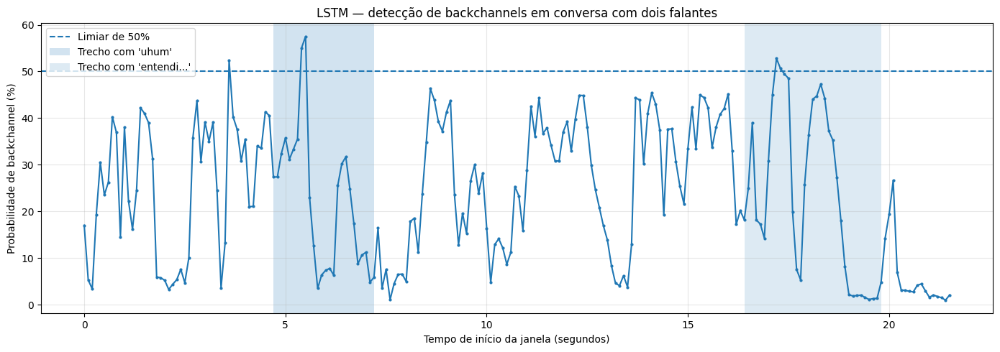

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_resultados_lstm["inicio_s"],
    df_resultados_lstm["probabilidade_pct"],
    marker=".",
    markersize=4
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Limiar de 50%"
)

# Momentos aproximados para inspeção
plt.axvspan(4.7, 7.2, alpha=0.2, label="Trecho com 'uhum'")
plt.axvspan(16.4, 19.8, alpha=0.15, label="Trecho com 'entendi...'")

plt.xlabel("Tempo de início da janela (segundos)")
plt.ylabel("Probabilidade de backchannel (%)")
plt.title("LSTM — detecção de backchannels em conversa com dois falantes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
resultados_estatistico = []

for inicio_amostra in range(
    0,
    len(audio) - amostras_janela + 1,
    amostras_passo
):
    trecho = audio[
        inicio_amostra:inicio_amostra + amostras_janela
    ]

    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=sr_alvo,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    # 13 médias + 13 desvios-padrão = 26 características
    caracteristicas = np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1)
    ]).reshape(1, -1)

    probabilidade = modelo_estatistico.predict_proba(
        caracteristicas
    )[0, 1]

    inicio_s = inicio_amostra / sr_alvo

    resultados_estatistico.append({
        "inicio_s": inicio_s,
        "fim_s": inicio_s + 1.21,
        "probabilidade_pct": probabilidade * 100
    })

df_resultados_estatistico = pd.DataFrame(
    resultados_estatistico
)

print("Total de janelas:", len(df_resultados_estatistico))
print(
    df_resultados_estatistico.nlargest(
        10, "probabilidade_pct"
    ).round(2)
)

Total de janelas: 216
     inicio_s  fim_s  probabilidade_pct
208      20.8  22.01              54.62
205      20.5  21.71              44.80
207      20.7  21.91              43.47
204      20.4  21.61              43.15
209      20.9  22.11              42.11
55        5.5   6.71              42.00
203      20.3  21.51              41.52
206      20.6  21.81              40.83
53        5.3   6.51              39.74
202      20.2  21.41              39.34


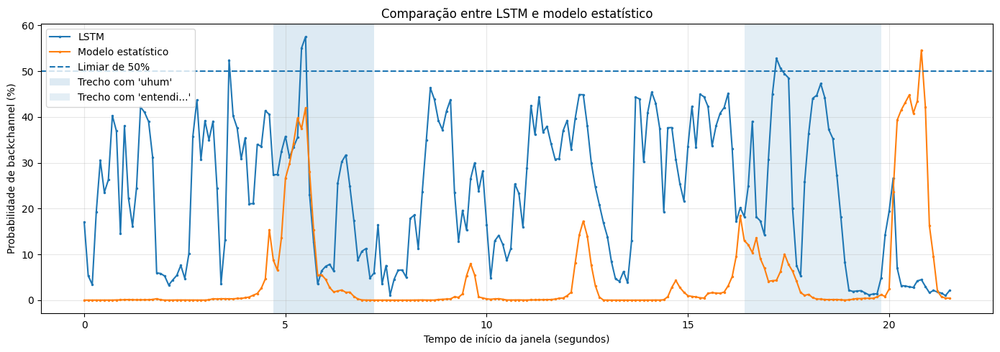

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_resultados_lstm["inicio_s"],
    df_resultados_lstm["probabilidade_pct"],
    label="LSTM",
    marker=".",
    markersize=3
)

plt.plot(
    df_resultados_estatistico["inicio_s"],
    df_resultados_estatistico["probabilidade_pct"],
    label="Modelo estatístico",
    marker=".",
    markersize=3
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Limiar de 50%"
)

plt.axvspan(4.7, 7.2, alpha=0.15, label="Trecho com 'uhum'")
plt.axvspan(16.4, 19.8, alpha=0.12, label="Trecho com 'entendi...'")

plt.xlabel("Tempo de início da janela (segundos)")
plt.ylabel("Probabilidade de backchannel (%)")
plt.title("Comparação entre LSTM e modelo estatístico")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
inicio = 20.0
fim = 22.5

trecho_final = audio_dois_falantes[
    int(inicio * sr_original):int(fim * sr_original)
]

display(Audio(trecho_final, rate=sr_original))

In [ ]:
# Mostrar as janelas com maior probabilidade no final do áudio
df_resultados_estatistico[
    (df_resultados_estatistico["inicio_s"] >= 19.5) &
    (df_resultados_estatistico["inicio_s"] <= 21.5)
].sort_values(
    "probabilidade_pct",
    ascending=False
).round(2)

,inicio_s,fim_s,probabilidade_pct
208,20.8,22.01,54.62
205,20.5,21.71,44.80
207,20.7,21.91,43.47
204,20.4,21.61,43.15
209,20.9,22.11,42.11
203,20.3,21.51,41.52
206,20.6,21.81,40.83
202,20.2,21.41,39.34
201,20.1,21.31,23.74
210,21.0,22.21,16.24


In [ ]:
resultados_curto = []

duracao_janela = 0.3
passo = 0.1

amostras_janela_curta = int(duracao_janela * sr_alvo)
amostras_passo_curto = int(passo * sr_alvo)

for inicio_amostra in range(
    int(19.5 * sr_alvo),
    int(22.5 * sr_alvo) - amostras_janela_curta + 1,
    amostras_passo_curto
):
    trecho = audio[inicio_amostra:inicio_amostra + amostras_janela_curta]

    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=sr_alvo,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    caracteristicas = np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1)
    ]).reshape(1, -1)

    probabilidade = modelo_estatistico.predict_proba(
        caracteristicas
    )[0, 1]

    resultados_curto.append({
        "inicio_s": inicio_amostra / sr_alvo,
        "fim_s": (inicio_amostra / sr_alvo) + duracao_janela,
        "probabilidade_pct": probabilidade * 100
    })

df_resultados_curto = pd.DataFrame(resultados_curto)

display(
    df_resultados_curto
    .sort_values("probabilidade_pct", ascending=False)
    .head(10)
    .round(2)
)

,inicio_s,fim_s,probabilidade_pct
13,20.8,21.1,98.15
12,20.7,21.0,97.08
16,21.1,21.4,95.93
14,20.9,21.2,92.12
15,21.0,21.3,89.13
17,21.2,21.5,76.09
11,20.6,20.9,28.63
2,19.7,20.0,18.51
18,21.3,21.6,14.87
1,19.6,19.9,7.21


In [ ]:
inicio = 20.6
fim = 21.5

trecho_pico = audio_dois_falantes[
    int(inicio * sr_original):int(fim * sr_original)
]

display(Audio(trecho_pico, rate=sr_original))

In [ ]:
# Reamostrar o trecho para 16 kHz
trecho_16k = librosa.resample(
    trecho_uhum.astype(np.float32),
    orig_sr=sr_original,
    target_sr=16000
)

# Normalização de amplitude, seguindo o teste anterior
if np.max(np.abs(trecho_16k)) > 0:
    trecho_16k = trecho_16k / np.max(np.abs(trecho_16k))

# Extrair MFCCs
mfcc = librosa.feature.mfcc(
    y=trecho_16k,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
)

# Modelo estatístico: médias e desvios-padrão
caracteristicas = np.concatenate([
    mfcc.mean(axis=1),
    mfcc.std(axis=1)
]).reshape(1, -1)

prob_estatistico = modelo_estatistico.predict_proba(
    caracteristicas
)[0, 1]

# LSTM: preparar a sequência no formato esperado
sequencia = mfcc.T

sequencia_preenchida = pad_sequences(
    [sequencia],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

sequencia_normalizada = (
    sequencia_preenchida - media_norm
) / desvio_norm

prob_lstm = modelo_lstm.predict(
    sequencia_normalizada,
    verbose=0
)[0][0]

print(f"Modelo estatístico: {prob_estatistico * 100:.2f}%")
print(f"LSTM: {prob_lstm * 100:.2f}%")

Modelo estatístico: 3.61%
LSTM: 93.58%


In [ ]:
inicio = 20.6
duracoes = [0.9, 1.0, 1.21]

resultados_duracao = []

for duracao in duracoes:
    fim = inicio + duracao

    # Recortar o áudio original
    trecho = audio_dois_falantes[
        int(inicio * sr_original):int(fim * sr_original)
    ].astype(np.float32)

    # Converter para 16 kHz
    trecho_16k = librosa.resample(
        trecho,
        orig_sr=sr_original,
        target_sr=16000
    )

    # Normalizar amplitude
    pico = np.max(np.abs(trecho_16k))
    if pico > 0:
        trecho_16k = trecho_16k / pico

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=trecho_16k,
        sr=16000,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    # Preparar a sequência para a LSTM
    sequencia = mfcc.T

    sequencia_preenchida = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    sequencia_normalizada = (
        sequencia_preenchida - media_norm
    ) / desvio_norm

    probabilidade = modelo_lstm.predict(
        sequencia_normalizada,
        verbose=0
    )[0][0]

    resultados_duracao.append({
        "inicio_s": inicio,
        "fim_s": fim,
        "duracao_s": duracao,
        "quadros_mfcc": len(sequencia),
        "probabilidade_pct": probabilidade * 100
    })

df_resultados_duracao = pd.DataFrame(resultados_duracao)

display(df_resultados_duracao.round(2))

,inicio_s,fim_s,duracao_s,quadros_mfcc,probabilidade_pct
0,20.6,21.50,0.90,91,0.41
1,20.6,21.60,1.00,101,0.33
2,20.6,21.81,1.21,122,1.83


In [ ]:
inicio_janelas = np.arange(20.2, 21.21, 0.1)
duracao = 1.0

resultados_posicao = []

for inicio in inicio_janelas:
    fim = inicio + duracao

    trecho = audio_dois_falantes[
        int(inicio * sr_original):int(fim * sr_original)
    ].astype(np.float32)

    trecho_16k = librosa.resample(
        trecho,
        orig_sr=sr_original,
        target_sr=16000
    )

    pico = np.max(np.abs(trecho_16k))
    if pico > 0:
        trecho_16k /= pico

    mfcc = librosa.feature.mfcc(
        y=trecho_16k,
        sr=16000,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    sequencia = mfcc.T

    sequencia_preenchida = pad_sequences(
        [sequencia],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    sequencia_normalizada = (
        sequencia_preenchida - media_norm
    ) / desvio_norm

    probabilidade = modelo_lstm.predict(
        sequencia_normalizada,
        verbose=0
    )[0][0]

    resultados_posicao.append({
        "inicio_s": inicio,
        "fim_s": fim,
        "probabilidade_pct": probabilidade * 100
    })

df_resultados_posicao = pd.DataFrame(resultados_posicao)

display(
    df_resultados_posicao.round(2)
    .sort_values("probabilidade_pct", ascending=False)
)

,inicio_s,fim_s,probabilidade_pct
0,20.2,21.2,62.080002
1,20.3,21.3,44.680000
10,21.2,22.2,0.670000
9,21.1,22.1,0.610000
8,21.0,22.0,0.500000
7,20.9,21.9,0.460000
2,20.4,21.4,0.450000
6,20.8,21.8,0.390000
5,20.7,21.7,0.340000
4,20.6,21.6,0.330000


In [ ]:
inicio = 20.6
fim = 21.6

trecho = audio_dois_falantes[
    int(inicio * sr_original):int(fim * sr_original)
].astype(np.float32)

trecho_16k = librosa.resample(
    trecho,
    orig_sr=sr_original,
    target_sr=16000
)

pico = np.max(np.abs(trecho_16k))
if pico > 0:
    trecho_16k = trecho_16k / pico

mfcc = librosa.feature.mfcc(
    y=trecho_16k,
    sr=16000,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

sequencia = mfcc.T

sequencia_preenchida = pad_sequences(
    [sequencia],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

sequencia_normalizada = (
    sequencia_preenchida - media_norm
) / desvio_norm

for i in range(3):
    prob = modelo_lstm.predict(
        sequencia_normalizada,
        verbose=0
    )[0][0]

    print(f"Tentativa {i + 1}: {prob * 100:.2f}%")

Tentativa 1: 0.33%
Tentativa 2: 0.33%
Tentativa 3: 0.33%


In [ ]:
print("Resultados do teste de duração:")
display(
    df_resultados_duracao[
        np.isclose(df_resultados_duracao["inicio_s"], 20.6)
    ].round(4)
)

print("Resultados do teste de posição:")
display(
    df_resultados_posicao[
        np.isclose(df_resultados_posicao["inicio_s"], 20.6)
    ].round(4)
)

Resultados do teste de duração:


,inicio_s,fim_s,duracao_s,quadros_mfcc,probabilidade_pct
0,20.6,21.50,0.90,91,0.4080
1,20.6,21.60,1.00,101,0.3280
2,20.6,21.81,1.21,122,1.8329


Resultados do teste de posição:


,inicio_s,fim_s,probabilidade_pct
4,20.6,21.6,0.328


In [ ]:
print("Formato dos MFCCs:", mfcc.shape)
print("Formato da sequência preenchida:", sequencia_preenchida.shape)
print("Formato da sequência normalizada:", sequencia_normalizada.shape)

print(
    "Contém NaN:",
    np.isnan(sequencia_normalizada).any()
)

print(
    "Contém infinito:",
    np.isinf(sequencia_normalizada).any()
)

print(
    "Mínimo da sequência normalizada:",
    np.min(sequencia_normalizada)
)

print(
    "Máximo da sequência normalizada:",
    np.max(sequencia_normalizada)
)

Formato dos MFCCs: (13, 101)
Formato da sequência preenchida: (1, 121, 13)
Formato da sequência normalizada: (1, 121, 13)
Contém NaN: False
Contém infinito: False
Mínimo da sequência normalizada: -3.9382737
Máximo da sequência normalizada: 2.5315628


In [ ]:
inicio = 20.6
fim = 21.6

inicio_amostra = int(inicio * 16000)
fim_amostra = int(fim * 16000)

trecho_completo = audio_16k[inicio_amostra:fim_amostra].astype(np.float32)

pico = np.max(np.abs(trecho_completo))
if pico > 0:
    trecho_completo = trecho_completo / pico

mfcc_completo = librosa.feature.mfcc(
    y=trecho_completo,
    sr=16000,
    n_mfcc=13,
    hop_length=160,
    n_fft=400
)

seq = mfcc_completo.T

seq_preenchida = pad_sequences(
    [seq],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post"
)

seq_normalizada = (seq_preenchida - media_norm) / desvio_norm

prob = modelo_lstm.predict(seq_normalizada, verbose=0)[0][0]

print(f"Quadros MFCC: {seq.shape[0]}")
print(f"Probabilidade da LSTM: {prob * 100:.2f}%")

Quadros MFCC: 101
Probabilidade da LSTM: 0.33%


In [ ]:
inicio = 20.6
fim = 21.5

# Trecho recortado antes da reamostragem
trecho_original = audio_dois_falantes[
    int(inicio * sr_original):int(fim * sr_original)
].astype(np.float32)

trecho_original_16k = librosa.resample(
    trecho_original,
    orig_sr=sr_original,
    target_sr=16000
)

# Trecho recortado depois da reamostragem do áudio completo
trecho_reamostrado = audio_16k[
    int(inicio * 16000):int(fim * 16000)
].astype(np.float32)

# Comparar os sinais
print("Amostras — recorte antes da reamostragem:", len(trecho_original_16k))
print("Amostras — recorte após a reamostragem:", len(trecho_reamostrado))

print(
    "Diferença máxima entre os sinais:",
    np.max(np.abs(trecho_original_16k[:min(
        len(trecho_original_16k), len(trecho_reamostrado)
    )] - trecho_reamostrado[:min(
        len(trecho_original_16k), len(trecho_reamostrado)
    )]))
)

Amostras — recorte antes da reamostragem: 14400
Amostras — recorte após a reamostragem: 14400
Diferença máxima entre os sinais: 3.241721e-05


In [ ]:
print("Média de normalização:")
print(media_norm)

print("\nDesvio-padrão de normalização:")
print(desvio_norm)

print("\nFormato esperado pelo modelo:")
print(modelo_lstm.input_shape)

print("\nParâmetros carregados:")
print("maxlen =", maxlen)
print("n_mfcc =", n_mfcc)

Média de normalização:
[[[-201.07956    106.47655    -19.20392     34.257133   -13.971649
     11.355603    -5.3403983   -2.305462     3.2402177   -8.819124
      6.771867    -8.48432      3.3017879]]]

Desvio-padrão de normalização:
[[[160.02008    84.9408     27.343567   32.647747   18.668976
    17.698315   12.053429   11.435464   11.481958   11.657722
    11.425737   11.4502735   9.953994 ]]]

Formato esperado pelo modelo:
(None, 121, 13)

Parâmetros carregados:
maxlen = 121
n_mfcc = 13


In [ ]:
# Verificar se a função original de inferência está disponível
print("Função original disponível:", "prever_backchannel" in globals())

Função original disponível: True


In [ ]:
prob_original = prever_backchannel(
    audio_dois_falantes[
        int(20.6 * sr_original):int(21.5 * sr_original)
    ],
    sr_original,
    modelo_lstm,
    media_norm,
    desvio_norm,
    maxlen,
    n_mfcc=n_mfcc,
    target_sr=16000
)

print(f"Função original: {prob_original * 100:.2f}%")

Função original: 0.41%


In [ ]:
def inspecionar_janela(inicio, fim):
    # Recorta o áudio original
    trecho = audio_dois_falantes[
        int(inicio * sr_original):int(fim * sr_original)
    ].astype(np.float32)

    # Aplica o mesmo pré-processamento da função original
    if np.max(np.abs(trecho)) > 0:
        trecho = trecho / np.max(np.abs(trecho))

    if sr_original != 16000:
        trecho = librosa.resample(
            trecho,
            orig_sr=sr_original,
            target_sr=16000
        )

    mfcc = librosa.feature.mfcc(
        y=trecho,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    sequencia = pad_sequences(
        [mfcc.T],
        maxlen=maxlen,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    sequencia_norm = (sequencia - media_norm) / desvio_norm

    prob = modelo_lstm.predict(sequencia_norm, verbose=0)[0][0]

    print(f"\nJanela: {inicio:.1f}–{fim:.1f} s")
    print(f"Frames MFCC: {mfcc.shape[1]}")
    print(f"Probabilidade: {prob * 100:.2f}%")
    print(f"MFCC antes da normalização: min={mfcc.min():.2f}, max={mfcc.max():.2f}")
    print(f"Entrada normalizada: min={sequencia_norm.min():.2f}, max={sequencia_norm.max():.2f}")

inspecionar_janela(20.2, 21.2)
inspecionar_janela(20.6, 21.5)


Janela: 20.2–21.2 s
Frames MFCC: 101
Probabilidade: 62.03%
MFCC antes da normalização: min=-599.41, max=161.28
Entrada normalizada: min=-3.94, max=2.53

Janela: 20.6–21.5 s
Frames MFCC: 91
Probabilidade: 0.41%
MFCC antes da normalização: min=-619.17, max=162.81
Entrada normalizada: min=-3.94, max=2.53


In [ ]:
resultados_deslocamento = []

for inicio in np.arange(20.0, 21.21, 0.1):
    inicio = round(float(inicio), 1)
    fim = inicio + 1.0

    trecho = audio_dois_falantes[
        int(inicio * sr_original):int(fim * sr_original)
    ]

    prob = prever_backchannel(
        trecho,
        sr_original,
        modelo_lstm,
        media_norm,
        desvio_norm,
        maxlen,
        n_mfcc=n_mfcc,
        target_sr=16000
    )

    resultados_deslocamento.append({
        "inicio_s": inicio,
        "fim_s": round(fim, 1),
        "probabilidade_%": round(prob * 100, 2)
    })

df_deslocamento = pd.DataFrame(resultados_deslocamento)
display(df_deslocamento)

,inicio_s,fim_s,probabilidade_%
0,20.0,21.0,0.98
1,20.1,21.1,47.47
2,20.2,21.2,62.03
3,20.3,21.3,44.58
4,20.4,21.4,0.45
5,20.5,21.5,0.32
6,20.6,21.6,0.33
7,20.7,21.7,0.34
8,20.8,21.8,0.39
9,20.9,21.9,0.46


In [ ]:
# Janela com probabilidade alta
print("Janela 20,2–21,2 s — 62,03%")
display(Audio(
    audio_dois_falantes[int(20.2 * sr_original):int(21.2 * sr_original)],
    rate=sr_original
))

# Janela com probabilidade baixa
print("Janela 20,4–21,4 s — 0,45%")
display(Audio(
    audio_dois_falantes[int(20.4 * sr_original):int(21.4 * sr_original)],
    rate=sr_original
))

Janela 20,2–21,2 s — 62,03%


Janela 20,4–21,4 s — 0,45%


In [ ]:
# Testar segmentos de 0,3 segundo, deslocados em 0,1 segundo
inicio_base = 20.0
fim_base = 21.5
duracao = 0.3
passo = 0.1

resultados_curto = []

inicio = inicio_base

while inicio + duracao <= fim_base + 1e-9:
    fim = inicio + duracao

    trecho = audio_dois_falantes[
        int(inicio * sr_original):int(fim * sr_original)
    ]

    prob = prever_backchannel(
        trecho,
        sr_original,
        modelo_lstm,
        media_norm,
        desvio_norm,
        maxlen,
        n_mfcc=n_mfcc,
        target_sr=16000
    )

    resultados_curto.append({
        "inicio_s": round(inicio, 1),
        "fim_s": round(fim, 1),
        "probabilidade_%": round(prob * 100, 2)
    })

    inicio = round(inicio + passo, 10)

df_curto = pd.DataFrame(resultados_curto)
display(df_curto)

,inicio_s,fim_s,probabilidade_%
0,20.0,20.3,1.09
1,20.1,20.4,41.08
2,20.2,20.5,92.19
3,20.3,20.6,93.39
4,20.4,20.7,93.57
5,20.5,20.8,93.60
6,20.6,20.9,92.61
7,20.7,21.0,93.60
8,20.8,21.1,93.60
9,20.9,21.2,93.60


In [ ]:
segmentos = [
    (20.0, 20.3),
    (20.2, 21.1),
    (21.1, 21.5)
]

for inicio, fim in segmentos:
    print(f"Trecho: {inicio:.1f}–{fim:.1f} s")
    display(Audio(
        audio_dois_falantes[
            int(inicio * sr_original):int(fim * sr_original)
        ],
        rate=sr_original
    ))

Trecho: 20.0–20.3 s


Trecho: 20.2–21.1 s


Trecho: 21.1–21.5 s


In [ ]:
# Intervalo estimado do backchannel
inicio_uhum = 20.6
fim_uhum = 21.2

trecho_uhum = audio_dois_falantes[
    int(inicio_uhum * sr_original):
    int(fim_uhum * sr_original)
]

# Ouvir o intervalo completo
from IPython.display import Audio, display

display(Audio(trecho_uhum, rate=sr_original))

# Previsão da LSTM com a função original
prob_lstm = prever_backchannel(
    trecho_uhum,
    sr_original,
    modelo_lstm,
    media_norm,
    desvio_norm,
    maxlen,
    n_mfcc=n_mfcc,
    target_sr=16000
)

print(f"Duração do trecho: {fim_uhum - inicio_uhum:.1f} s")
print(f"Probabilidade prevista pela LSTM: {prob_lstm * 100:.2f}%")

Duração do trecho: 0.6 s
Probabilidade prevista pela LSTM: 93.46%


In [173]:
arquivos_enviados = files.upload()

nome_arquivo = next(iter(arquivos_enviados))

audio_novo, sr_novo = librosa.load(
    nome_arquivo,
    sr=None,
    mono=True
)

duracao = len(audio_novo) / sr_novo

print(f"Arquivo: {nome_arquivo}")
print(f"Duração: {duracao:.2f} segundos")
print(f"Taxa de amostragem: {sr_novo} Hz")
print(f"Número de amostras: {len(audio_novo)}")

display(Audio(audio_novo, rate=sr_novo))

Saving Sobreposicao.m4a to Sobreposicao (1).m4a
Arquivo: Sobreposicao (1).m4a
Duração: 14.72 segundos
Taxa de amostragem: 48000 Hz
Número de amostras: 706560


/tmp/ipykernel_1853/1867378048.py:5: UserWarning: PySoundFile failed. Trying audioread instead.
  audio_novo, sr_novo = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


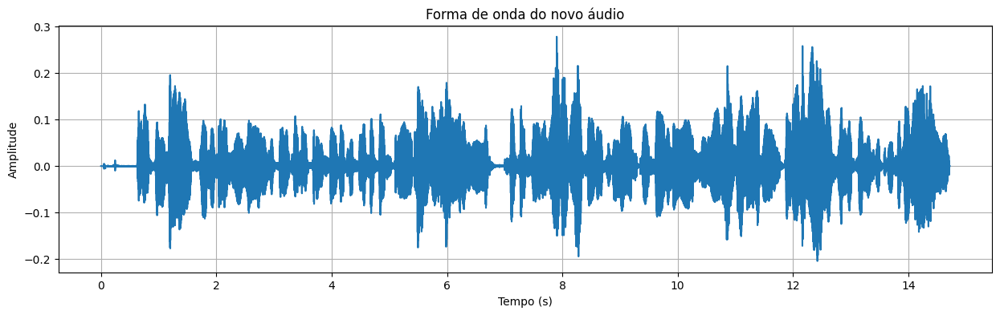

In [174]:
tempo = np.arange(len(audio_novo)) / sr_novo

plt.figure(figsize=(15, 4))
plt.plot(tempo, audio_novo)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Forma de onda do novo áudio")
plt.grid(True)
plt.show()

In [175]:
duracao = len(audio_novo) / sr_novo

for inicio in range(0, int(duracao), 10):
    fim = min(inicio + 10, duracao)

    print(f"Áudio de {inicio} a {fim:.1f} segundos")

    trecho = audio_novo[
        int(inicio * sr_novo):int(fim * sr_novo)
    ]

    display(Audio(trecho, rate=sr_novo))

Áudio de 0 a 10.0 segundos


Áudio de 10 a 14.7 segundos


In [176]:
duracao = len(audio_novo) / sr_novo

for inicio_bloco in range(0, int(duracao), 10):
    fim_bloco = min(inicio_bloco + 10, duracao)

    print(f"Bloco: {inicio_bloco}–{fim_bloco:.1f} s")
    display(Audio(
        audio_novo[
            int(inicio_bloco * sr_novo):
            int(fim_bloco * sr_novo)
        ],
        rate=sr_novo
    ))

Bloco: 0–10.0 s


Bloco: 10–14.7 s


In [206]:
duracao = len(audio_novo) / sr_novo

print(f"Taxa de amostragem: {sr_novo} Hz")
print(f"Duração real: {duracao:.3f} segundos")

# Ouvir uma janela maior ao redor de cada exemplo
exemplos = [
    ("uhum_1", 5.0, 5.5),
    ("entendi", 7.8, 8.4),
    ("uhum_2", 10.5, 11.0),
]

for nome, inicio, fim in exemplos:
    # Garantir que o intervalo esteja dentro do áudio
    inicio = max(0, inicio)
    fim = min(fim, duracao)

    trecho = audio_novo[
        int(inicio * sr_novo):int(fim * sr_novo)
    ]

    print(f"\n{nome}: {inicio:.2f}–{fim:.2f} s")

    if len(trecho) > 0:
        display(Audio(trecho, rate=sr_novo))
    else:
        print("Trecho vazio: confira os tempos e a duração do áudio.")

Taxa de amostragem: 48000 Hz
Duração real: 14.720 segundos

uhum_1: 5.00–5.50 s



entendi: 7.80–8.40 s



uhum_2: 10.50–11.00 s


In [226]:
exemplos_audio = {
    "uhum_1": (5.0, 5.5),
    "entendi": (7.8, 8.4),
    "uhum_2": (10.5, 11.0),
}

trechos_teste = {}

for nome, (inicio, fim) in exemplos_audio.items():
    trecho = audio_novo[
        int(inicio * sr_novo):int(fim * sr_novo)
    ]

    if len(trecho) == 0:
        print(f"{nome}: ERRO — trecho vazio")
        continue

    trechos_teste[nome] = trecho

    print(
        f"{nome}: {len(trecho)} amostras | "
        f"{len(trecho) / sr_novo:.3f} s | "
        f"amplitude máxima: {np.max(np.abs(trecho)):.4f}"
    )

uhum_1: 24000 amostras | 0.500 s | amplitude máxima: 0.1752
entendi: 28800 amostras | 0.600 s | amplitude máxima: 0.2782
uhum_2: 24000 amostras | 0.500 s | amplitude máxima: 0.2150


In [227]:
print("Entrada esperada pelo modelo:", modelo_lstm.input_shape)
print("Formato de media_norm:", np.shape(media_norm))
print("Formato de desvio_norm:", np.shape(desvio_norm))

for nome, trecho in trechos_teste.items():
    print(f"{nome}:")
    print("  áudio:", trecho.shape)

Entrada esperada pelo modelo: (None, 121, 13)
Formato de media_norm: (1, 1, 13)
Formato de desvio_norm: (1, 1, 13)
uhum_1:
  áudio: (24000,)
entendi:
  áudio: (28800,)
uhum_2:
  áudio: (24000,)


In [228]:
print("Tipo:", type(parametros))

if isinstance(parametros, dict):
    print("Chaves:", parametros.keys())

    for chave, valor in parametros.items():
        if isinstance(valor, (np.ndarray, list, tuple)):
            print(chave, "-> formato:", np.shape(valor))
        else:
            print(chave, "->", type(valor), valor)

elif isinstance(parametros, (list, tuple)):
    for i, valor in enumerate(parametros):
        print(f"Parâmetro {i}: formato {np.shape(valor)}")

else:
    print(parametros)

Tipo: <class 'dict'>
Chaves: dict_keys(['media', 'desvio', 'maxlen', 'n_mfcc'])
media -> formato: (1, 1, 13)
desvio -> formato: (1, 1, 13)
maxlen -> <class 'int'> 121
n_mfcc -> <class 'int'> 13


In [229]:
if isinstance(parametros, dict):
    chaves = list(parametros.keys())
    print("Chaves encontradas:", chaves)

    # Ajuste os nomes abaixo caso a célula anterior mostre outros nomes.
    possiveis_medias = ["media_norm", "media", "mean", "mean_norm"]
    possiveis_desvios = ["desvio_norm", "desvio", "std", "std_norm"]

    chave_media = next(
        (k for k in possiveis_medias if k in parametros), None
    )
    chave_desvio = next(
        (k for k in possiveis_desvios if k in parametros), None
    )

    if chave_media is None or chave_desvio is None:
        raise ValueError(
            "Não identifiquei automaticamente média e desvio. "
            "Confira as chaves impressas na célula anterior."
        )

    media_norm = np.asarray(parametros[chave_media])
    desvio_norm = np.asarray(parametros[chave_desvio])

elif isinstance(parametros, (list, tuple)) and len(parametros) >= 2:
    media_norm = np.asarray(parametros[0])
    desvio_norm = np.asarray(parametros[1])

else:
    raise ValueError(
        "Formato dos parâmetros não reconhecido. "
        "Confira a saída da célula 4."
    )

print("Formato da média:", media_norm.shape)
print("Formato do desvio:", desvio_norm.shape)

Chaves encontradas: ['media', 'desvio', 'maxlen', 'n_mfcc']
Formato da média: (1, 1, 13)
Formato do desvio: (1, 1, 13)


In [231]:
duracao = len(audio_novo) / sr_novo

print(f"Taxa de amostragem: {sr_novo} Hz")
print(f"Duração do áudio: {duracao:.2f} segundos")

exemplos_audio = {
    "uhum_1": (5.0, 5.5),
    "entendi": (7.8, 8.4),
    "uhum_2": (10.5, 11.0),
}

trechos_teste = {}

for nome, (inicio, fim) in exemplos_audio.items():
    if fim > duracao:
        print(f"{nome}: ignorado, trecho ultrapassa a duração.")
        continue

    trecho = audio_novo[
        int(inicio * sr_novo):int(fim * sr_novo)
    ]

    if len(trecho) > 0:
        trechos_teste[nome] = trecho
        print(
            f"{nome}: {inicio:.1f}–{fim:.1f}s | "
            f"{len(trecho)} amostras"
        )

Taxa de amostragem: 48000 Hz
Duração do áudio: 14.72 segundos
uhum_1: 5.0–5.5s | 24000 amostras
entendi: 7.8–8.4s | 28800 amostras
uhum_2: 10.5–11.0s | 24000 amostras


In [232]:
nome_teste = next(iter(trechos_teste))
trecho = trechos_teste[nome_teste]

target_sr = 16000
n_mfcc = 13
maxlen = 121

audio_f = trecho.astype(np.float32)

if np.max(np.abs(audio_f)) > 0:
    audio_f = audio_f / np.max(np.abs(audio_f))

if sr_novo != target_sr:
    audio_f = librosa.resample(
        audio_f,
        orig_sr=sr_novo,
        target_sr=target_sr
    )

mfcc = librosa.feature.mfcc(
    y=audio_f,
    sr=target_sr,
    n_mfcc=n_mfcc,
    hop_length=160,
    n_fft=400
)

seq = mfcc.T

print("Trecho:", nome_teste)
print("Formato dos MFCCs:", mfcc.shape)
print("Formato da sequência:", seq.shape)
print("Formato esperado pelo modelo:", modelo_lstm.input_shape)

Trecho: uhum_1
Formato dos MFCCs: (13, 51)
Formato da sequência: (51, 13)
Formato esperado pelo modelo: (None, 121, 13)


In [233]:
print("Sequência:", seq.shape)
print("Média:", media_norm.shape)
print("Desvio:", desvio_norm.shape)

assert seq.ndim == 2, "A sequência deve ter formato (tempo, 13)."
assert seq.shape[1] == n_mfcc, "A sequência não tem 13 coeficientes MFCC."
assert np.all(np.isfinite(media_norm)), "A média contém valores inválidos."
assert np.all(np.isfinite(desvio_norm)), "O desvio contém valores inválidos."
assert np.all(desvio_norm > 0), "Há valores de desvio iguais ou menores que zero."

print("Verificações básicas concluídas.")

Sequência: (51, 13)
Média: (1, 1, 13)
Desvio: (1, 1, 13)
Verificações básicas concluídas.


In [234]:
media = np.asarray(media_norm)
desvio = np.asarray(desvio_norm)

# Aceita parâmetros por coeficiente, desde que tenham exatamente 13 valores.
if media.size == n_mfcc and desvio.size == n_mfcc:
    media = media.reshape(n_mfcc)
    desvio = desvio.reshape(n_mfcc)
else:
    raise ValueError(
        f"Os parâmetros não contêm exatamente {n_mfcc} valores. "
        f"Média: {media_norm.shape}; desvio: {desvio_norm.shape}. "
        "É necessário confirmar como foram calculados no treinamento."
    )

# Método A: padding primeiro, normalização depois.
seq_pad_a = pad_sequences(
    [seq],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post",
    value=0.0
)

seq_a = (seq_pad_a - media) / desvio

# Método B: normalizar primeiro, padding depois.
seq_norm_real = (seq - media) / desvio

seq_b = pad_sequences(
    [seq_norm_real],
    maxlen=maxlen,
    dtype="float32",
    padding="post",
    truncating="post",
    value=0.0
)

print("Método A:", seq_a.shape)
print("Método B:", seq_b.shape)

assert seq_a.shape == (1, maxlen, n_mfcc)
assert seq_b.shape == (1, maxlen, n_mfcc)

Método A: (1, 121, 13)
Método B: (1, 121, 13)


In [235]:
prob_a = float(modelo_lstm.predict(seq_a, verbose=0)[0][0])
prob_b = float(modelo_lstm.predict(seq_b, verbose=0)[0][0])

print(f"Método A — padding antes da normalização: {prob_a:.2%}")
print(f"Método B — padding depois da normalização: {prob_b:.2%}")
print(f"Diferença absoluta: {abs(prob_a - prob_b):.2%}")

Método A — padding antes da normalização: 1.01%
Método B — padding depois da normalização: 62.34%
Diferença absoluta: 61.33%


In [236]:
resultados = []

for nome, trecho in trechos_teste.items():
    audio_f = trecho.astype(np.float32)

    if np.max(np.abs(audio_f)) > 0:
        audio_f = audio_f / np.max(np.abs(audio_f))

    if sr_novo != target_sr:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_novo,
            target_sr=target_sr
        )

    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=target_sr,
        n_mfcc=n_mfcc,
        hop_length=160,
        n_fft=400
    )

    seq = mfcc.T

    # Método A
    seq_pad_a = pad_sequences(
        [seq], maxlen=maxlen, dtype="float32",
        padding="post", truncating="post", value=0.0
    )
    seq_a = (seq_pad_a - media) / desvio

    # Método B
    seq_norm_real = (seq - media) / desvio
    seq_b = pad_sequences(
        [seq_norm_real], maxlen=maxlen, dtype="float32",
        padding="post", truncating="post", value=0.0
    )

    prob_a = float(modelo_lstm.predict(seq_a, verbose=0)[0][0])
    prob_b = float(modelo_lstm.predict(seq_b, verbose=0)[0][0])

    resultados.append({
        "trecho": nome,
        "metodo_a": prob_a,
        "metodo_b": prob_b,
        "diferenca": abs(prob_a - prob_b)
    })

for r in resultados:
    print(f"\n{r['trecho']}")
    print(f"  Método A: {r['metodo_a']:.2%}")
    print(f"  Método B: {r['metodo_b']:.2%}")
    print(f"  Diferença: {r['diferenca']:.2%}")


uhum_1
  Método A: 1.01%
  Método B: 62.34%
  Diferença: 61.33%

entendi
  Método A: 52.67%
  Método B: 69.04%
  Diferença: 16.37%

uhum_2
  Método A: 87.70%
  Método B: 77.34%
  Diferença: 10.36%


In [237]:
def prever_janela(trecho, sr_original):
    audio_f = trecho.astype(np.float32)

    # Normalizar amplitude
    pico = np.max(np.abs(audio_f))
    if pico > 0:
        audio_f = audio_f / pico

    # Converter para 16 kHz
    if sr_original != 16000:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_original,
            target_sr=16000
        )

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    seq = mfcc.T

    # Padding antes da normalização
    seq_pad = pad_sequences(
        [seq],
        maxlen=121,
        dtype="float32",
        padding="post",
        truncating="post",
        value=0.0
    )

    seq_norm = (seq_pad - media) / desvio

    # Previsão
    probabilidade = modelo_lstm.predict(
        seq_norm,
        verbose=0
    )[0][0]

    return float(probabilidade)

In [238]:
prob_teste = prever_janela(
    trechos_teste["uhum_1"],
    sr_novo
)

print(f"Probabilidade: {prob_teste:.2%}")

Probabilidade: 1.01%


In [241]:
duracoes = [0.3, 0.5, 0.8, 1.21]

exemplos_audio = {
    "uhum_1": (5.0, 5.5),
    "entendi": (7.8, 8.4),
    "uhum_2": (10.5, 11.0),
}

duracao_audio = len(audio_novo) / sr_novo

print(f"Duração total: {duracao_audio:.2f} s")

Duração total: 14.72 s


In [242]:
resultados_janelas = []

for nome, (inicio, fim) in exemplos_audio.items():

    centro = (inicio + fim) / 2

    for duracao in duracoes:

        inicio_janela = centro - duracao / 2
        fim_janela = centro + duracao / 2

        # Garantir que a janela esteja dentro da gravação
        if inicio_janela < 0 or fim_janela > duracao_audio:
            print(f"Janela ignorada: {nome}, {duracao}s")
            continue

        amostra_inicio = int(inicio_janela * sr_novo)
        amostra_fim = int(fim_janela * sr_novo)

        trecho = audio_novo[amostra_inicio:amostra_fim]

        prob = prever_janela(trecho, sr_novo)

        resultados_janelas.append({
            "trecho": nome,
            "duracao_s": duracao,
            "inicio_s": inicio_janela,
            "fim_s": fim_janela,
            "probabilidade": prob
        })

        print(
            f"{nome:10s} | "
            f"{duracao:4.2f}s | "
            f"{prob:.2%}"
        )

uhum_1     | 0.30s | 1.16%
uhum_1     | 0.50s | 1.01%
uhum_1     | 0.80s | 0.78%
uhum_1     | 1.21s | 2.05%
entendi    | 0.30s | 93.51%
entendi    | 0.50s | 66.88%
entendi    | 0.80s | 1.15%
entendi    | 1.21s | 7.95%
uhum_2     | 0.30s | 93.60%
uhum_2     | 0.50s | 87.70%
uhum_2     | 0.80s | 0.63%
uhum_2     | 1.21s | 21.95%


In [243]:
df_janelas = pd.DataFrame(resultados_janelas)

tabela_janelas = df_janelas.pivot(
    index="trecho",
    columns="duracao_s",
    values="probabilidade"
)

tabela_janelas = tabela_janelas.rename(
    columns=lambda x: f"{x:.2f}s"
)

display((tabela_janelas * 100).round(2))

duracao_s,0.30s,0.50s,0.80s,1.21s
trecho,,,,
entendi,93.51,66.88,1.15,7.95
uhum_1,1.16,1.01,0.78,2.05
uhum_2,93.60,87.70,0.63,21.95


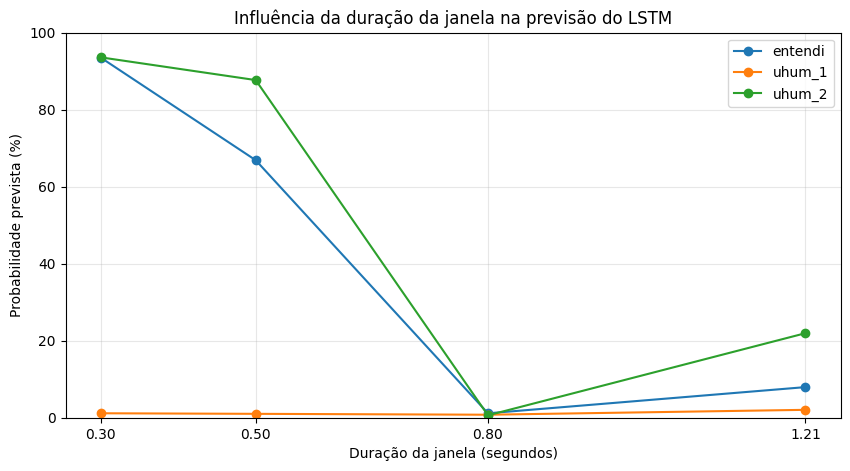

In [244]:
plt.figure(figsize=(10, 5))

for nome, grupo in df_janelas.groupby("trecho"):
    plt.plot(
        grupo["duracao_s"],
        grupo["probabilidade"] * 100,
        marker="o",
        label=nome
    )

plt.xlabel("Duração da janela (segundos)")
plt.ylabel("Probabilidade prevista (%)")
plt.title("Influência da duração da janela na previsão do LSTM")
plt.xticks(duracoes)
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [245]:
def prever_com_time_stretch(trecho, sr_original):
    audio_f = trecho.astype(np.float32)

    # Normalizar amplitude
    pico = np.max(np.abs(audio_f))
    if pico > 0:
        audio_f = audio_f / pico

    # Converter para 16 kHz
    if sr_original != 16000:
        audio_f = librosa.resample(
            audio_f,
            orig_sr=sr_original,
            target_sr=16000
        )

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio_f,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    seq = mfcc.T

    # Ajustar temporalmente para 121 quadros
    taxa = len(seq) / 121

    mfcc_ajustado = librosa.effects.time_stretch(
        y=audio_f,
        rate=taxa
    )

    mfcc_novo = librosa.feature.mfcc(
        y=mfcc_ajustado,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    ).T

    # Garantir o formato esperado
    seq_final = pad_sequences(
        [mfcc_novo],
        maxlen=121,
        dtype="float32",
        padding="post",
        truncating="post",
        value=0.0
    )

    seq_norm = (seq_final - media) / desvio

    prob = modelo_lstm.predict(
        seq_norm,
        verbose=0
    )[0][0]

    return float(prob), len(seq), len(mfcc_novo)

In [246]:
resultados_stretch = []

for nome, trecho in trechos_teste.items():

    prob_padding = prever_janela(trecho, sr_novo)

    prob_stretch, quadros_originais, quadros_ajustados = (
        prever_com_time_stretch(trecho, sr_novo)
    )

    resultados_stretch.append({
        "trecho": nome,
        "padding": prob_padding,
        "time_stretch": prob_stretch,
        "quadros_originais": quadros_originais,
        "quadros_ajustados": quadros_ajustados
    })

df_stretch = pd.DataFrame(resultados_stretch)

display(df_stretch.round(4))

,trecho,padding,time_stretch,quadros_originais,quadros_ajustados
0,uhum_1,0.0101,0.0082,51,119
1,entendi,0.5267,0.5311,61,120
2,uhum_2,0.8770,0.0347,51,119


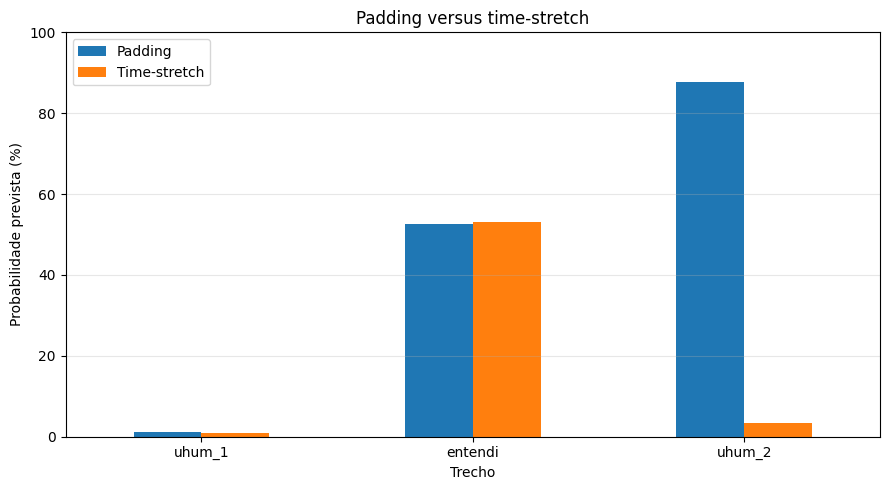

In [247]:
df_plot = df_stretch.set_index("trecho")[
    ["padding", "time_stretch"]
] * 100

ax = df_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_ylabel("Probabilidade prevista (%)")
ax.set_xlabel("Trecho")
ax.set_title("Padding versus time-stretch")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.legend(["Padding", "Time-stretch"])
plt.tight_layout()
plt.show()

In [248]:
arquivos = files.upload()

nome_audio = next(iter(arquivos.keys()))
print("Arquivo selecionado:", nome_audio)


Saving Sobreposicao.m4a to Sobreposicao (2).m4a
Arquivo selecionado: Sobreposicao (2).m4a


In [249]:
audio_original, sr_original = librosa.load(
    nome_audio,
    sr=None,
    mono=False
)

print("Frequência de amostragem:", sr_original, "Hz")
print("Formato do áudio:", audio_original.shape)

if audio_original.ndim == 1:
    duracao = len(audio_original) / sr_original
    print("Canais: mono (1 canal)")
else:
    duracao = audio_original.shape[-1] / sr_original
    print("Canais:", audio_original.shape[0])

print("Duração:", round(duracao, 2), "segundos")



/tmp/ipykernel_1853/1101534637.py:1: UserWarning: PySoundFile failed. Trying audioread instead.
  audio_original, sr_original = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Frequência de amostragem: 48000 Hz
Formato do áudio: (706560,)
Canais: mono (1 canal)
Duração: 14.72 segundos


In [250]:
display(Audio(audio_original, rate=sr_original))

In [251]:
def ouvir_trecho(inicio, fim):
    amostra_inicio = int(inicio * sr_original)
    amostra_fim = int(fim * sr_original)

    trecho = audio_original[..., amostra_inicio:amostra_fim]

    print(f"Trecho: {inicio:.2f}s até {fim:.2f}s")
    display(Audio(trecho, rate=sr_original))

ouvir_trecho(10, 11)

Trecho: 10.00s até 11.00s


In [252]:
anotacoes = pd.DataFrame([
    {"inicio": 3.2, "fim": 3.5, "classe": "backchannel_sobreposto"},
    {"inicio": 7.5, "fim": 8.5, "classe": "backchannel_sobreposto"},
    {"inicio": 9.0, "fim": 11.0, "classe": "backchannel_sobreposto"},
    {"inicio": 10.0, "fim": 11.0, "classe": "backchannel_sobreposto"},
])

display(anotacoes)


,inicio,fim,classe
0,3.2,3.5,backchannel_sobreposto
1,7.5,8.5,backchannel_sobreposto
2,9.0,11.0,backchannel_sobreposto
3,10.0,11.0,backchannel_sobreposto


In [253]:
nomes_necessarios = [
    "modelo",
    "media_norm",
    "desvio_norm",
    "TARGET_SR",
    "n_mfcc",
    "HOP_LENGTH",
    "N_FFT",
    "maxlen",
    "preparar_audio_para_lstm",
]

for nome in nomes_necessarios:
    print(f"{nome}: {'OK' if nome in globals() else 'FALTANDO'}")

modelo: OK
media_norm: OK
desvio_norm: OK
TARGET_SR: FALTANDO
n_mfcc: OK
HOP_LENGTH: FALTANDO
N_FFT: FALTANDO
maxlen: OK
preparar_audio_para_lstm: FALTANDO


In [254]:
TARGET_SR = 16000
HOP_LENGTH = 160
N_FFT = 400

print("Parâmetros definidos:")
print("TARGET_SR:", TARGET_SR)
print("HOP_LENGTH:", HOP_LENGTH)
print("N_FFT:", N_FFT)
print("n_mfcc:", n_mfcc)
print("maxlen:", maxlen)

Parâmetros definidos:
TARGET_SR: 16000
HOP_LENGTH: 160
N_FFT: 400
n_mfcc: 13
maxlen: 121


In [255]:
def preparar_audio_para_lstm(audio):
    # Garantir que o áudio esteja em formato de array
    audio = np.asarray(audio, dtype=np.float32)

    # Evitar divisão por zero
    maior_amplitude = np.max(np.abs(audio))

    if maior_amplitude > 0:
        audio = audio / maior_amplitude

    # Extrair MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=TARGET_SR,
        n_mfcc=n_mfcc,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    # Formato: frames x coeficientes
    mfcc = mfcc.T

    # Ajustar para o tamanho esperado pelo modelo
    if len(mfcc) < maxlen:
        padding = maxlen - len(mfcc)
        mfcc = np.pad(
            mfcc,
            ((0, padding), (0, 0)),
            mode="constant"
        )
    else:
        mfcc = mfcc[:maxlen]

    # Normalizar com os parâmetros salvos
    mfcc = (mfcc - media_norm) / desvio_norm

    # Adicionar dimensão do lote
    return np.expand_dims(mfcc, axis=0)

In [259]:
nomes_necessarios = [
    "modelo",
    "media_norm",
    "desvio_norm",
    "TARGET_SR",
    "n_mfcc",
    "HOP_LENGTH",
    "N_FFT",
    "maxlen",
    "preparar_audio_para_lstm",
]

for nome in nomes_necessarios:
    print(f"{nome}: {'OK' if nome in globals() else 'FALTANDO'}")

modelo: OK
media_norm: OK
desvio_norm: OK
TARGET_SR: OK
n_mfcc: OK
HOP_LENGTH: OK
N_FFT: OK
maxlen: OK
preparar_audio_para_lstm: OK


In [260]:
caminho_audio = "Sobreposicao.m4a"

audio, sr = librosa.load(
    caminho_audio,
    sr=16000,
    mono=True
)

duracao = len(audio) / sr

print(f"Taxa de amostragem: {sr} Hz")
print(f"Duração: {duracao:.2f} segundos")

display(Audio(audio, rate=sr))

Taxa de amostragem: 16000 Hz
Duração: 14.72 segundos


/tmp/ipykernel_1853/291111002.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


In [264]:
print("Entrada esperada:", modelo.input_shape)
print("Saída esperada:", modelo.output_shape)
print("Formato de entrada:", type(entrada))
print("Shape da entrada:", np.shape(entrada))
print("Tipo dos dados:", np.asarray(entrada).dtype)
print("Valores finitos:", np.isfinite(entrada).all())

Entrada esperada: (None, 121, 13)
Saída esperada: (None, 1)


NameError: name 'entrada' is not defined

In [262]:
print("MFCC:", mfcc.shape)
print("Média:", np.shape(media_norm))
print("Desvio:", np.shape(desvio_norm))

MFCC: (13, 51)
Média: (1, 1, 13)
Desvio: (1, 1, 13)


In [263]:
def preparar_audio_para_lstm(audio):
    audio = np.asarray(audio, dtype=np.float32)

    # Normalização da amplitude
    max_amplitude = np.max(np.abs(audio))
    if max_amplitude > 0:
        audio = audio / max_amplitude

    # Extração dos MFCCs
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=TARGET_SR,
        n_mfcc=n_mfcc,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    # Transforma de (13, frames) para (frames, 13)
    mfcc = mfcc.T

    # Ajusta para maxlen frames
    if mfcc.shape[0] < maxlen:
        mfcc = np.pad(
            mfcc,
            ((0, maxlen - mfcc.shape[0]), (0, 0)),
            mode="constant"
        )
    else:
        mfcc = mfcc[:maxlen, :]

    # Ajusta os parâmetros de normalização para (1, 13)
    media = np.asarray(media_norm).reshape(-1)
    desvio = np.asarray(desvio_norm).reshape(-1)

    if media.size != n_mfcc or desvio.size != n_mfcc:
        raise ValueError(
            f"Parâmetros incompatíveis: média={media.shape}, "
            f"desvio={desvio.shape}, n_mfcc={n_mfcc}"
        )

    mfcc_norm = (mfcc - media) / desvio

    # Adiciona apenas a dimensão do lote
    return np.expand_dims(mfcc_norm, axis=0).astype(np.float32)

In [265]:
entrada_teste = preparar_audio_para_lstm(audio[:int(1.21 * sr)])

print("Shape:", entrada_teste.shape)
print("Valores finitos:", np.isfinite(entrada_teste).all())

previsao_teste = modelo.predict(entrada_teste, verbose=0)
print("Probabilidade:", previsao_teste[0][0])

Shape: (1, 121, 13)
Valores finitos: True
Probabilidade: 0.14002092


In [266]:
tamanho_janela = int(1.21 * sr)
passo = int(0.1 * sr)

resultados = []

for inicio_amostra in range(0, len(audio), passo):
    fim_amostra = inicio_amostra + tamanho_janela

    janela = audio[inicio_amostra:min(fim_amostra, len(audio))]

    if len(janela) < tamanho_janela:
        janela = np.pad(
            janela,
            (0, tamanho_janela - len(janela)),
            mode="constant"
        )

    entrada = preparar_audio_para_lstm(janela)
    saida = modelo.predict(entrada, verbose=0)
    probabilidade = float(saida[0][0])

    resultados.append({
        "inicio_s": inicio_amostra / sr,
        "fim_s": min(fim_amostra / sr, duracao),
        "probabilidade": probabilidade
    })

previsoes = pd.DataFrame(resultados)

print("Janelas analisadas:", len(previsoes))
display(previsoes.sort_values("probabilidade", ascending=False).head(15))

Janelas analisadas: 148


,inicio_s,fim_s,probabilidade
72,7.2,8.41,0.538735
51,5.1,6.31,0.533504
122,12.2,13.41,0.478810
37,3.7,4.91,0.472748
56,5.6,6.81,0.467701
36,3.6,4.81,0.466475
30,3.0,4.21,0.461377
127,12.7,13.91,0.458584
8,0.8,2.01,0.455943
50,5.0,6.21,0.442712


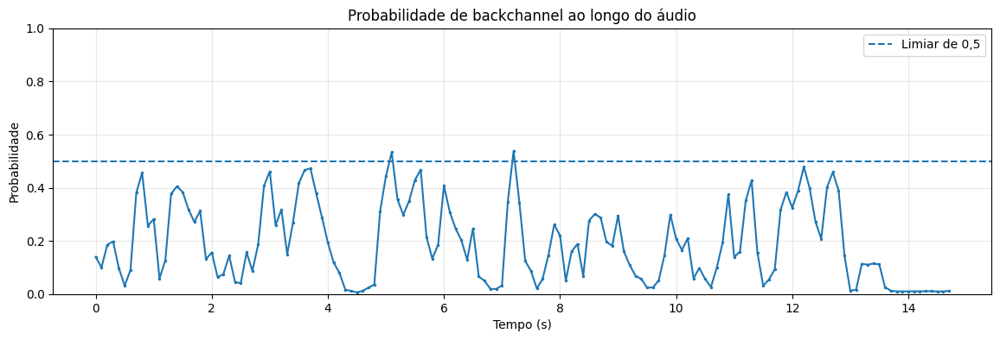

In [267]:
plt.figure(figsize=(14, 4))
plt.plot(
    previsoes["inicio_s"],
    previsoes["probabilidade"],
    marker=".",
    markersize=3
)
plt.axhline(0.5, linestyle="--", label="Limiar de 0,5")
plt.xlabel("Tempo (s)")
plt.ylabel("Probabilidade")
plt.title("Probabilidade de backchannel ao longo do áudio")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [268]:
intervalos = [
    (3.2, 3.5),
    (7.5, 8.5),
    (9.0, 11.0),
    (10.0, 11.0)
]

for inicio, fim in intervalos:
    trecho = previsoes[
        (previsoes["inicio_s"] <= fim) &
        (previsoes["fim_s"] >= inicio)
    ]

    print(f"\nIntervalo anotado: {inicio:.1f}–{fim:.1f} s")

    if not trecho.empty:
        print(f"Maior probabilidade: {trecho['probabilidade'].max():.3f}")
        print(f"Tempo do pico: {trecho.loc[trecho['probabilidade'].idxmax(), 'inicio_s']:.2f} s")


Intervalo anotado: 3.2–3.5 s
Maior probabilidade: 0.461
Tempo do pico: 3.00 s

Intervalo anotado: 7.5–8.5 s
Maior probabilidade: 0.539
Tempo do pico: 7.20 s

Intervalo anotado: 9.0–11.0 s
Maior probabilidade: 0.376
Tempo do pico: 10.90 s

Intervalo anotado: 10.0–11.0 s
Maior probabilidade: 0.376
Tempo do pico: 10.90 s


In [269]:
eventos = [
    ("Evento 1", 3.2, 3.5),
    ("Evento 2", 7.5, 8.5),
    ("Evento 3", 9.0, 11.0)
]

for nome, inicio, fim in eventos:
    print(f"\n{nome}: {inicio:.1f}–{fim:.1f} s")

    trecho = previsoes[
        (previsoes["fim_s"] >= inicio) &
        (previsoes["inicio_s"] <= fim)
    ].copy()

    display(
        trecho[["inicio_s", "fim_s", "probabilidade"]]
        .sort_values("probabilidade", ascending=False)
        .head(8)
        .round(3)
    )


Evento 1: 3.2–3.5 s


,inicio_s,fim_s,probabilidade
30,3.0,4.21,0.461
35,3.5,4.71,0.417
29,2.9,4.11,0.407
32,3.2,4.41,0.318
34,3.4,4.61,0.270
31,3.1,4.31,0.258
28,2.8,4.01,0.187
26,2.6,3.81,0.157



Evento 2: 7.5–8.5 s


,inicio_s,fim_s,probabilidade
72,7.2,8.41,0.539
71,7.1,8.31,0.346
73,7.3,8.51,0.344
85,8.5,9.71,0.277
79,7.9,9.11,0.262
65,6.5,7.71,0.247
80,8.0,9.21,0.219
63,6.3,7.51,0.203



Evento 3: 9.0–11.0 s


,inicio_s,fim_s,probabilidade
109,10.9,12.11,0.376
86,8.6,9.81,0.301
99,9.9,11.11,0.299
90,9.0,10.21,0.295
87,8.7,9.91,0.287
85,8.5,9.71,0.277
79,7.9,9.11,0.262
80,8.0,9.21,0.219


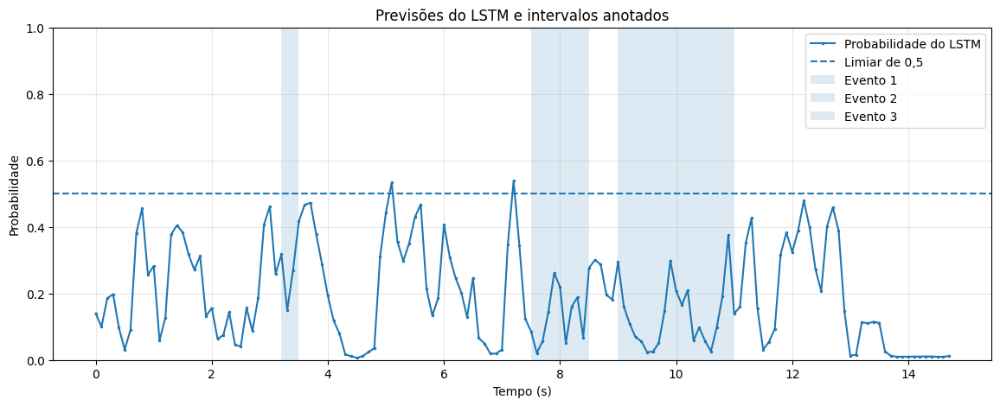

In [270]:
eventos = [
    (3.2, 3.5, "Evento 1"),
    (7.5, 8.5, "Evento 2"),
    (9.0, 11.0, "Evento 3")
]

plt.figure(figsize=(14, 5))

plt.plot(
    previsoes["inicio_s"],
    previsoes["probabilidade"],
    marker=".",
    markersize=3,
    label="Probabilidade do LSTM"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Limiar de 0,5"
)

for inicio, fim, nome in eventos:
    plt.axvspan(inicio, fim, alpha=0.15, label=nome)

plt.xlabel("Tempo (s)")
plt.ylabel("Probabilidade")
plt.title("Previsões do LSTM e intervalos anotados")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [271]:
def preparar_audio_para_lstm(audio):
    audio = np.asarray(audio, dtype=np.float32)

    # Normaliza a amplitude, como no notebook de treinamento
    if np.max(np.abs(audio)) > 0:
        audio = audio / np.max(np.abs(audio))

    # Extrai MFCCs com os parâmetros originais
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=16000,
        n_mfcc=13,
        hop_length=160,
        n_fft=400
    )

    # (13, frames) -> (frames, 13)
    seq = mfcc.T

    # Preenche ou trunca para 121 frames
    seq_padded = pad_sequences(
        [seq],
        maxlen=121,
        dtype="float32",
        padding="post",
        truncating="post"
    )

    # Normaliza usando os parâmetros do treinamento
    seq_norm = (seq_padded - media_norm) / desvio_norm

    return seq_norm.astype(np.float32)

In [272]:
entrada_teste = preparar_audio_para_lstm(audio[:int(1.21 * sr)])

print("Shape:", entrada_teste.shape)
print("Valores finitos:", np.isfinite(entrada_teste).all())

previsao_teste = modelo.predict(entrada_teste, verbose=0)
print("Probabilidade:", float(previsao_teste[0][0]))

Shape: (1, 121, 13)
Valores finitos: True
Probabilidade: 0.1400209218263626


In [273]:
tamanho_janela = int(1.21 * sr)
passo = int(0.1 * sr)

resultados = []

for inicio_amostra in range(0, len(audio), passo):
    fim_amostra = inicio_amostra + tamanho_janela

    janela = audio[inicio_amostra:min(fim_amostra, len(audio))]

    if len(janela) < tamanho_janela:
        janela = np.pad(
            janela,
            (0, tamanho_janela - len(janela)),
            mode="constant"
        )

    entrada = preparar_audio_para_lstm(janela)
    probabilidade = float(modelo.predict(entrada, verbose=0)[0][0])

    resultados.append({
        "inicio_s": inicio_amostra / sr,
        "fim_s": min(fim_amostra / sr, duracao),
        "probabilidade": probabilidade
    })

previsoes = pd.DataFrame(resultados)

print("Total de janelas:", len(previsoes))
print("\n15 maiores probabilidades:")
display(
    previsoes.nlargest(15, "probabilidade").round(3)
)

Total de janelas: 148

15 maiores probabilidades:


,inicio_s,fim_s,probabilidade
72,7.2,8.41,0.539
51,5.1,6.31,0.534
122,12.2,13.41,0.479
37,3.7,4.91,0.473
56,5.6,6.81,0.468
36,3.6,4.81,0.466
30,3.0,4.21,0.461
127,12.7,13.91,0.459
8,0.8,2.01,0.456
50,5.0,6.21,0.443


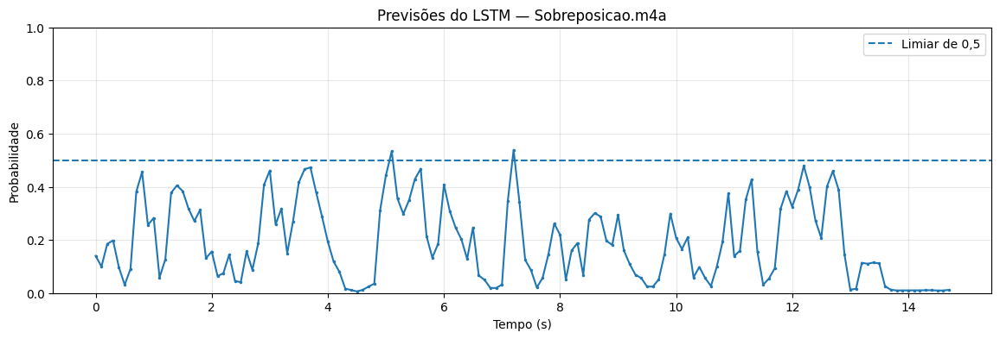

In [274]:
plt.figure(figsize=(14, 4))
plt.plot(previsoes["inicio_s"], previsoes["probabilidade"], marker=".", markersize=3)
plt.axhline(0.5, linestyle="--", label="Limiar de 0,5")

plt.xlabel("Tempo (s)")
plt.ylabel("Probabilidade")
plt.title("Previsões do LSTM — Sobreposicao.m4a")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [275]:
tamanho_janela = int(1.21 * sr)
passo = int(0.1 * sr)

resultados = []

# Só analisar janelas que contêm 1,21 s completos
for inicio_amostra in range(
    0,
    len(audio) - tamanho_janela + 1,
    passo
):
    fim_amostra = inicio_amostra + tamanho_janela
    janela = audio[inicio_amostra:fim_amostra]

    entrada = preparar_audio_para_lstm(janela)

    probabilidade = float(
        modelo.predict(entrada, verbose=0)[0][0]
    )

    resultados.append({
        "inicio_s": inicio_amostra / sr,
        "fim_s": fim_amostra / sr,
        "probabilidade": probabilidade
    })

previsoes = pd.DataFrame(resultados)

print("Duração do áudio:", round(duracao, 2), "s")
print("Janelas completas analisadas:", len(previsoes))
print("Maior probabilidade:", round(
    previsoes["probabilidade"].max(), 3
))

display(
    previsoes.nlargest(10, "probabilidade").round(3)
)

Duração do áudio: 14.72 s
Janelas completas analisadas: 136
Maior probabilidade: 0.539


,inicio_s,fim_s,probabilidade
72,7.2,8.41,0.539
51,5.1,6.31,0.534
122,12.2,13.41,0.479
37,3.7,4.91,0.473
56,5.6,6.81,0.468
36,3.6,4.81,0.466
30,3.0,4.21,0.461
127,12.7,13.91,0.459
8,0.8,2.01,0.456
50,5.0,6.21,0.443


In [276]:
eventos = [
    ("Evento 1", 3.2, 3.5),
    ("Evento 2", 7.5, 8.5),
    ("Evento 3", 9.0, 11.0)
]

comparacao = []

for nome, inicio, fim in eventos:
    trecho = previsoes[
        (previsoes["inicio_s"] <= fim) &
        (previsoes["fim_s"] >= inicio)
    ]

    if trecho.empty:
        continue

    indice_pico = trecho["probabilidade"].idxmax()
    pico = previsoes.loc[indice_pico]

    comparacao.append({
        "evento": nome,
        "intervalo_real": f"{inicio:.1f}–{fim:.1f} s",
        "maior_probabilidade": pico["probabilidade"],
        "inicio_janela_pico": pico["inicio_s"],
        "acima_de_0.5": pico["probabilidade"] >= 0.5
    })

tabela_eventos = pd.DataFrame(comparacao)

display(tabela_eventos.round(3))

,evento,intervalo_real,maior_probabilidade,inicio_janela_pico,acima_de_0.5
0,Evento 1,3.2–3.5 s,0.461,3.0,False
1,Evento 2,7.5–8.5 s,0.539,7.2,True
2,Evento 3,9.0–11.0 s,0.376,10.9,False


In [277]:
# Mostrar as janelas mais prováveis que não se sobrepõem
# aos eventos anotados

positivas = previsoes[
    previsoes["probabilidade"] >= 0.5
].copy()

def eventos_intersectados(linha):
    encontrados = []

    for nome, inicio, fim in eventos:
        if (
            linha["inicio_s"] < fim
            and linha["fim_s"] > inicio
        ):
            encontrados.append(nome)

    return ", ".join(encontrados) if encontrados else "Nenhum evento anotado"

positivas["evento_anotado"] = positivas.apply(
    eventos_intersectados, axis=1
)

display(positivas.round(3))

,inicio_s,fim_s,probabilidade,evento_anotado
51,5.1,6.31,0.534,Nenhum evento anotado
72,7.2,8.41,0.539,Evento 2


In [278]:
def ouvir_trecho(inicio, fim):
    trecho = audio[int(inicio * sr):int(fim * sr)]
    print(f"Trecho: {inicio:.2f}–{fim:.2f} s")
    display(Audio(trecho, rate=sr))

ouvir_trecho(5.1, 6.4)
ouvir_trecho(7.0, 8.7)

Trecho: 5.10–6.40 s


Trecho: 7.00–8.70 s


In [279]:
def ouvir_trecho(inicio, fim):
    trecho = audio[int(inicio * sr):int(fim * sr)]
    print(f"Trecho: {inicio:.2f}–{fim:.2f} s")
    display(Audio(trecho, rate=sr))

ouvir_trecho(5.1, 6.4)

Trecho: 5.10–6.40 s


In [280]:
eventos = [
    ("Uhum sobreposto", 5.1, 6.31),
    ("Entendi sobreposto", 7.2, 8.41)
]

print("Eventos registrados:")
for nome, inicio, fim in eventos:
    print(f"{nome}: {inicio:.2f}–{fim:.2f} s")

Eventos registrados:
Uhum sobreposto: 5.10–6.31 s
Entendi sobreposto: 7.20–8.41 s


In [281]:
comparacao = []

for nome, inicio, fim in eventos:
    trecho = previsoes[
        (previsoes["inicio_s"] <= fim) &
        (previsoes["fim_s"] >= inicio)
    ]

    if trecho.empty:
        continue

    pico = trecho.loc[trecho["probabilidade"].idxmax()]

    comparacao.append({
        "evento": nome,
        "intervalo_provisorio": f"{inicio:.2f}–{fim:.2f} s",
        "maior_probabilidade": pico["probabilidade"],
        "inicio_janela_pico": pico["inicio_s"],
        "acima_de_0.5": pico["probabilidade"] >= 0.5
    })

display(pd.DataFrame(comparacao).round(3))

,evento,intervalo_provisorio,maior_probabilidade,inicio_janela_pico,acima_de_0.5
0,Uhum sobreposto,5.10–6.31 s,0.534,5.1,True
1,Entendi sobreposto,7.20–8.41 s,0.539,7.2,True


In [282]:
def ouvir_trecho_lento(inicio, fim, velocidade=0.8):
    trecho = audio[int(inicio * sr):int(fim * sr)]

    print(f"Trecho original: {inicio:.2f}–{fim:.2f} s")
    display(Audio(trecho, rate=int(sr * velocidade)))

# Uhum sobreposto à fala principal
ouvir_trecho_lento(5.4, 5.9)

# Entendi sobreposto à fala principal
ouvir_trecho_lento(7.8, 8.2)

Trecho original: 5.40–5.90 s


Trecho original: 7.80–8.20 s


In [283]:
eventos_confirmados = [
    ("Uhum sobreposto", 5.4, 5.9),
    ("Entendi sobreposto", 7.8, 8.2)
]

In [284]:
comparacao_eventos = []

limiar = 0.5

for nome, inicio_real, fim_real in eventos_confirmados:

    # Janelas que se sobrepõem temporalmente à fala real
    trecho = previsoes[
        (previsoes["inicio_s"] < fim_real) &
        (previsoes["fim_s"] > inicio_real)
    ]

    if trecho.empty:
        continue

    pico = trecho.loc[trecho["probabilidade"].idxmax()]

    # Alguma janela positiva cobre o evento?
    janelas_positivas = trecho[
        trecho["probabilidade"] >= limiar
    ]

    comparacao_eventos.append({
        "evento": nome,
        "inicio_real": inicio_real,
        "fim_real": fim_real,
        "maior_probabilidade": pico["probabilidade"],
        "inicio_janela_pico": pico["inicio_s"],
        "alguma_janela_acima_0.5": not janelas_positivas.empty
    })

tabela_eventos = pd.DataFrame(comparacao_eventos)

display(tabela_eventos.round(3))

,evento,inicio_real,fim_real,maior_probabilidade,inicio_janela_pico,alguma_janela_acima_0.5
0,Uhum sobreposto,5.4,5.9,0.534,5.1,True
1,Entendi sobreposto,7.8,8.2,0.539,7.2,True


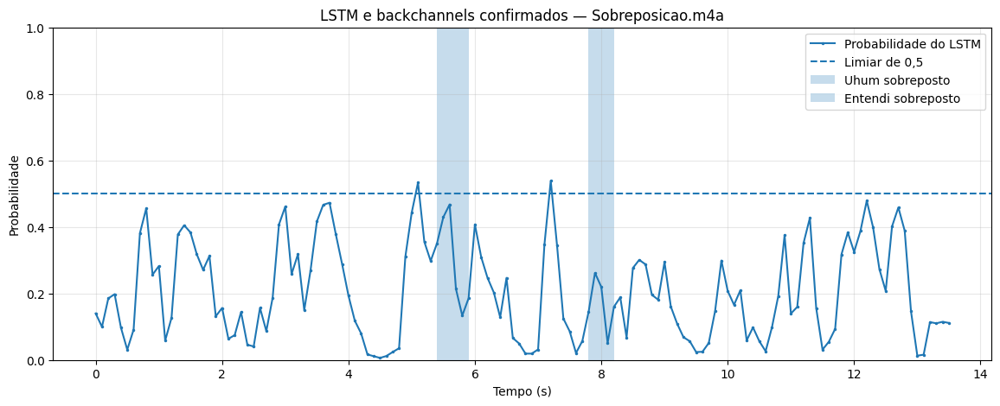

In [285]:
plt.figure(figsize=(14, 5))

plt.plot(
    previsoes["inicio_s"],
    previsoes["probabilidade"],
    marker=".",
    markersize=3,
    label="Probabilidade do LSTM"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Limiar de 0,5"
)

for nome, inicio, fim in eventos_confirmados:
    plt.axvspan(inicio, fim, alpha=0.25, label=nome)

plt.xlabel("Tempo (s)")
plt.ylabel("Probabilidade")
plt.title("LSTM e backchannels confirmados — Sobreposicao.m4a")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [286]:
eventos_confirmados = [
    ("Uhum sobreposto", 5.4, 5.9),
    ("Entendi sobreposto", 7.8, 8.2)
]

limiar = 0.5
resultados_eventos = []

for nome, inicio_real, fim_real in eventos_confirmados:
    trecho = previsoes[
        (previsoes["inicio_s"] < fim_real) &
        (previsoes["fim_s"] > inicio_real)
    ]

    if trecho.empty:
        continue

    pico = trecho.loc[trecho["probabilidade"].idxmax()]
    positivas = trecho[trecho["probabilidade"] >= limiar]

    resultados_eventos.append({
        "evento": nome,
        "inicio_real_s": inicio_real,
        "fim_real_s": fim_real,
        "maior_probabilidade": pico["probabilidade"],
        "inicio_janela_pico_s": pico["inicio_s"],
        "detectado_pelo_limiar": not positivas.empty
    })

avaliacao_eventos = pd.DataFrame(resultados_eventos)
display(avaliacao_eventos.round(3))

,evento,inicio_real_s,fim_real_s,maior_probabilidade,inicio_janela_pico_s,detectado_pelo_limiar
0,Uhum sobreposto,5.4,5.9,0.534,5.1,True
1,Entendi sobreposto,7.8,8.2,0.539,7.2,True


In [287]:
limiar = 0.5

# Eventos reais confirmados
eventos_confirmados = [
    ("Uhum", 5.4, 5.9),
    ("Entendi", 7.8, 8.2)
]

# Todas as janelas que ultrapassam o limiar
janelas_positivas = previsoes[
    previsoes["probabilidade"] >= limiar
].copy()

print("Janelas positivas:", len(janelas_positivas))
display(janelas_positivas.round(3))

# Resumo por evento real
resumo = []

for nome, inicio, fim in eventos_confirmados:
    janelas_do_evento = previsoes[
        (previsoes["inicio_s"] < fim) &
        (previsoes["fim_s"] > inicio)
    ]

    positivas_do_evento = janelas_do_evento[
        janelas_do_evento["probabilidade"] >= limiar
    ]

    resumo.append({
        "evento": nome,
        "inicio_real_s": inicio,
        "fim_real_s": fim,
        "max_probabilidade": janelas_do_evento["probabilidade"].max(),
        "detectado": not positivas_do_evento.empty
    })

display(pd.DataFrame(resumo).round(3))

Janelas positivas: 2


,inicio_s,fim_s,probabilidade
51,5.1,6.31,0.534
72,7.2,8.41,0.539


,evento,inicio_real_s,fim_real_s,max_probabilidade,detectado
0,Uhum,5.4,5.9,0.534,True
1,Entendi,7.8,8.2,0.539,True


In [288]:
ouvir_trecho_lento(2.8, 4.3)
ouvir_trecho_lento(10.4, 10.8)

Trecho original: 2.80–4.30 s


Trecho original: 10.40–10.80 s


In [289]:
# Ouvir o trecho
ouvir_trecho_lento(10.2, 11.0)

# Consultar as janelas que se sobrepõem ao intervalo
inicio_evento = 10.4
fim_evento = 10.8

trecho_previsoes = previsoes[
    (previsoes["inicio_s"] < fim_evento) &
    (previsoes["fim_s"] > inicio_evento)
]

display(
    trecho_previsoes[
        ["inicio_s", "fim_s", "probabilidade"]
    ].round(3)
)

Trecho original: 10.20–11.00 s


,inicio_s,fim_s,probabilidade
92,9.2,10.41,0.109
93,9.3,10.51,0.069
94,9.4,10.61,0.056
95,9.5,10.71,0.024
96,9.6,10.81,0.025
97,9.7,10.91,0.051
98,9.8,11.01,0.147
99,9.9,11.11,0.299
100,10.0,11.21,0.208
101,10.1,11.31,0.166


In [290]:
eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8)
]

In [291]:
limiar = 0.5
resultados_eventos = []

for nome, inicio_real, fim_real in eventos_confirmados:
    trecho = previsoes[
        (previsoes["inicio_s"] < fim_real) &
        (previsoes["fim_s"] > inicio_real)
    ]

    if trecho.empty:
        continue

    pico = trecho.loc[trecho["probabilidade"].idxmax()]
    janelas_positivas = trecho[trecho["probabilidade"] >= limiar]

    resultados_eventos.append({
        "evento": nome,
        "inicio_real_s": inicio_real,
        "fim_real_s": fim_real,
        "max_probabilidade": pico["probabilidade"],
        "inicio_janela_pico_s": pico["inicio_s"],
        "detectado": not janelas_positivas.empty
    })

avaliacao_eventos = pd.DataFrame(resultados_eventos)

display(avaliacao_eventos.round(3))

total_detectados = avaliacao_eventos["detectado"].sum()
total_eventos = len(avaliacao_eventos)

print(f"Eventos detectados: {total_detectados}/{total_eventos}")
print(f"Recall observado: {total_detectados / total_eventos:.1%}")

,evento,inicio_real_s,fim_real_s,max_probabilidade,inicio_janela_pico_s,detectado
0,Uhum 1,5.4,5.9,0.534,5.1,True
1,Entendi,7.8,8.2,0.539,7.2,True
2,Uhum 2,10.4,10.8,0.299,9.9,False


Eventos detectados: 2/3
Recall observado: 66.7%


In [292]:
ouvir_trecho_lento(2.8, 4.3)

Trecho original: 2.80–4.30 s


In [293]:
limiares = [0.5, 0.4, 0.3, 0.25]
resultados_limiares = []

for limiar in limiares:
    eventos_detectados = 0

    for nome, inicio, fim in eventos_confirmados:
        trecho = previsoes[
            (previsoes["inicio_s"] < fim) &
            (previsoes["fim_s"] > inicio)
        ]

        detectado = (
            not trecho.empty
            and (trecho["probabilidade"] >= limiar).any()
        )

        eventos_detectados += int(detectado)

    resultados_limiares.append({
        "limiar": limiar,
        "eventos_detectados": eventos_detectados,
        "total_eventos": len(eventos_confirmados),
        "recall_observado": eventos_detectados / len(eventos_confirmados)
    })

display(pd.DataFrame(resultados_limiares).round(3))

,limiar,eventos_detectados,total_eventos,recall_observado
0,0.50,2,3,0.667
1,0.40,2,3,0.667
2,0.30,2,3,0.667
3,0.25,3,3,1.000


In [294]:
limiares = [0.50, 0.40, 0.30, 0.25]

eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8)
]

regioes_sem_evento = [(2.8, 4.3)]

resumo = []

for limiar in limiares:
    detectados = 0

    for nome, inicio, fim in eventos_confirmados:
        trecho = previsoes[
            (previsoes["inicio_s"] < fim) &
            (previsoes["fim_s"] > inicio)
        ]
        if not trecho.empty and (trecho["probabilidade"] >= limiar).any():
            detectados += 1

    positivas = previsoes[previsoes["probabilidade"] >= limiar]

    janelas_positivas_negativas = positivas[
        positivas.apply(
            lambda linha: any(
                linha["inicio_s"] < fim and linha["fim_s"] > inicio
                for inicio, fim in regioes_sem_evento
            ),
            axis=1
        )
    ]

    resumo.append({
        "limiar": limiar,
        "eventos_detectados": f"{detectados}/3",
        "recall_observado": detectados / 3,
        "janelas_positivas_na_regiao_negativa": len(janelas_positivas_negativas)
    })

display(pd.DataFrame(resumo).round(3))

,limiar,eventos_detectados,recall_observado,janelas_positivas_na_regiao_negativa
0,0.50,2/3,0.667,0
1,0.40,2/3,0.667,5
2,0.30,2/3,0.667,9
3,0.25,3/3,1.000,13


In [295]:
limiares = [0.50, 0.40, 0.30, 0.25]

inicio_negativo, fim_negativo = 2.8, 4.3
passo_segundos = 0.1

resumo_episodios = []

for limiar in limiares:
    negativas = previsoes[
        (previsoes["probabilidade"] >= limiar) &
        (previsoes["inicio_s"] < fim_negativo) &
        (previsoes["fim_s"] > inicio_negativo)
    ].sort_values("inicio_s").copy()

    if negativas.empty:
        episodios = 0
    else:
        # Agrupa janelas positivas consecutivas em um mesmo episódio
        diferencas = negativas["inicio_s"].diff()
        negativas["grupo"] = (
            (diferencas > passo_segundos * 1.5)
            .fillna(False)
            .cumsum()
        )
        episodios = negativas["grupo"].nunique()

    resumo_episodios.append({
        "limiar": limiar,
        "janelas_positivas": len(negativas),
        "episodios_na_regiao_negativa": episodios
    })

display(pd.DataFrame(resumo_episodios))

,limiar,janelas_positivas,episodios_na_regiao_negativa
0,0.50,0,0
1,0.40,5,2
2,0.30,9,5
3,0.25,13,3


In [296]:
limiares = [0.50, 0.40, 0.30, 0.25]

eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8)
]

resumo_geral = []
episodios_por_limiar = {}

for limiar in limiares:
    positivas = (
        previsoes[previsoes["probabilidade"] >= limiar]
        .sort_values("inicio_s")
        .copy()
    )

    if positivas.empty:
        episodios_por_limiar[limiar] = pd.DataFrame()
        resumo_geral.append({
            "limiar": limiar,
            "janelas_positivas": 0,
            "episodios": 0,
            "episodios_sobrepostos_a_eventos": 0,
            "episodios_sem_evento_anotado": 0
        })
        continue

    # Agrupa janelas positivas consecutivas
    positivas["grupo"] = (
        (positivas["inicio_s"].diff().fillna(0) > 0.15)
        .cumsum()
    )

    episodios = []

    for grupo, trecho in positivas.groupby("grupo"):
        inicio = trecho["inicio_s"].min()
        fim = trecho["fim_s"].max()

        eventos_cobertos = [
            nome
            for nome, ini_real, fim_real in eventos_confirmados
            if ((trecho["inicio_s"] < fim_real) &
                (trecho["fim_s"] > ini_real)).any()
        ]

        episodios.append({
            "inicio_s": inicio,
            "fim_s": fim,
            "maior_probabilidade": trecho["probabilidade"].max(),
            "eventos_cobertos": ", ".join(eventos_cobertos) or "Nenhum anotado"
        })

    tabela = pd.DataFrame(episodios)
    episodios_por_limiar[limiar] = tabela

    resumo_geral.append({
        "limiar": limiar,
        "janelas_positivas": len(positivas),
        "episodios": len(tabela),
        "episodios_sobrepostos_a_eventos":
            (tabela["eventos_cobertos"] != "Nenhum anotado").sum(),
        "episodios_sem_evento_anotado":
            (tabela["eventos_cobertos"] == "Nenhum anotado").sum()
    })

display(pd.DataFrame(resumo_geral))

# Consulte os episódios encontrados com o limiar original
display(episodios_por_limiar[0.50].round(3))

,limiar,janelas_positivas,episodios,episodios_sobrepostos_a_eventos,episodios_sem_evento_anotado
0,0.50,2,2,2,0
1,0.40,17,11,3,8
2,0.30,39,15,3,12
3,0.25,52,15,4,11


,inicio_s,fim_s,maior_probabilidade,eventos_cobertos
0,5.1,6.31,0.534,Uhum 1
1,7.2,8.41,0.539,Entendi


In [297]:
def agrupar_episodios(previsoes, limiar):
    positivas = (
        previsoes[previsoes["probabilidade"] >= limiar]
        .sort_values("inicio_s")
    )

    episodios = []

    for _, linha in positivas.iterrows():
        inicio = float(linha["inicio_s"])
        fim = float(linha["fim_s"])
        prob = float(linha["probabilidade"])

        # Se a janela se sobrepõe ao episódio atual,
        # ela pertence ao mesmo episódio
        if episodios and inicio <= episodios[-1]["fim_s"]:
            episodios[-1]["fim_s"] = max(
                episodios[-1]["fim_s"], fim
            )
            episodios[-1]["maior_probabilidade"] = max(
                episodios[-1]["maior_probabilidade"], prob
            )
        else:
            episodios.append({
                "inicio_s": inicio,
                "fim_s": fim,
                "maior_probabilidade": prob
            })

    return pd.DataFrame(episodios)


for limiar in [0.50, 0.40, 0.30, 0.25]:
    episodios = agrupar_episodios(previsoes, limiar)

    print(f"\nLimiar: {limiar:.2f}")
    print("Episódios agrupados:", len(episodios))
    display(episodios.round(3))


Limiar: 0.50
Episódios agrupados: 2


,inicio_s,fim_s,maior_probabilidade
0,5.1,6.31,0.534
1,7.2,8.41,0.539



Limiar: 0.40
Episódios agrupados: 4


,inicio_s,fim_s,maior_probabilidade
0,0.8,2.61,0.456
1,2.9,4.91,0.473
2,5.0,8.41,0.539
3,11.3,13.91,0.479



Limiar: 0.30
Episódios agrupados: 3


,inicio_s,fim_s,maior_probabilidade
0,0.7,8.51,0.539
1,8.6,9.81,0.301
2,10.9,14.01,0.479



Limiar: 0.25
Episódios agrupados: 1


,inicio_s,fim_s,maior_probabilidade
0,0.7,14.01,0.539


In [298]:
eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8)
]

resultados = []

for limiar in [0.50, 0.40, 0.30, 0.25]:
    detectados = 0

    for nome, inicio, fim in eventos_confirmados:
        janelas_evento = previsoes[
            (previsoes["inicio_s"] < fim) &
            (previsoes["fim_s"] > inicio)
        ]

        detectado = (
            not janelas_evento.empty
            and (janelas_evento["probabilidade"] >= limiar).any()
        )

        detectados += int(detectado)

        resultados.append({
            "limiar": limiar,
            "evento": nome,
            "detectado": detectado
        })

avaliacao = pd.DataFrame(resultados)
display(avaliacao.pivot(
    index="limiar",
    columns="evento",
    values="detectado"
))

print("\nRecall observado por limiar:")
display(
    avaliacao.groupby("limiar")["detectado"]
    .mean()
    .rename("recall_observado")
    .reset_index()
)

evento,Entendi,Uhum 1,Uhum 2
limiar,,,
0.25,True,True,True
0.30,True,True,False
0.40,True,True,False
0.50,True,True,False



Recall observado por limiar:


,limiar,recall_observado
0,0.25,1.000000
1,0.30,0.666667
2,0.40,0.666667
3,0.50,0.666667


In [299]:
limiar = 0.25

positivas = (
    previsoes[previsoes["probabilidade"] >= limiar]
    .sort_values("inicio_s")
    .copy()
)

positivas["grupo"] = (
    (positivas["inicio_s"].diff().fillna(0) > 0.15)
    .cumsum()
)

eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8)
]

episodios = []

for grupo, trecho in positivas.groupby("grupo"):
    inicio = trecho["inicio_s"].min()
    fim = trecho["fim_s"].max()

    eventos_cobertos = [
        nome
        for nome, ini, fim_real in eventos_confirmados
        if ((trecho["inicio_s"] < fim_real) &
            (trecho["fim_s"] > ini)).any()
    ]

    episodios.append({
        "inicio_s": inicio,
        "fim_s": fim,
        "probabilidade_maxima": trecho["probabilidade"].max(),
        "eventos_cobertos": ", ".join(eventos_cobertos) or "Nenhum anotado"
    })

episodios_025 = pd.DataFrame(episodios)
display(episodios_025.round(3))

,inicio_s,fim_s,probabilidade_maxima,eventos_cobertos
0,0.7,2.21,0.456,Nenhum anotado
1,1.3,3.01,0.405,Nenhum anotado
2,2.9,4.41,0.461,Nenhum anotado
3,3.4,5.11,0.473,Nenhum anotado
4,4.9,6.81,0.534,Uhum 1
5,6.0,7.31,0.408,Nenhum anotado
6,7.1,8.51,0.539,Entendi
7,7.9,9.11,0.262,Entendi
8,8.5,9.91,0.301,Nenhum anotado
9,9.0,10.21,0.295,Nenhum anotado


In [300]:
candidatos = episodios_025[
    episodios_025["eventos_cobertos"] == "Nenhum anotado"
].sort_values("probabilidade_maxima", ascending=False)

for _, episodio in candidatos.iterrows():
    inicio = max(0, float(episodio["inicio_s"]))
    fim = min(float(episodio["fim_s"]), duracao)

    print(
        f"Trecho: {inicio:.2f}–{fim:.2f} s | "
        f"Probabilidade máxima: "
        f"{episodio['probabilidade_maxima']:.3f}"
    )

    display(
        Audio(
            audio[int(inicio * sr):int(fim * sr)],
            rate=sr
        )
    )

Trecho: 11.80–13.61 s | Probabilidade máxima: 0.479


Trecho: 3.40–5.11 s | Probabilidade máxima: 0.473


Trecho: 2.90–4.41 s | Probabilidade máxima: 0.461


Trecho: 12.60–14.01 s | Probabilidade máxima: 0.459


Trecho: 0.70–2.21 s | Probabilidade máxima: 0.456


...

Trecho: 6.00–7.31 s | Probabilidade máxima: 0.408


Trecho: 1.30–3.01 s | Probabilidade máxima: 0.405


Trecho: 10.90–12.11 s | Probabilidade máxima: 0.376


Trecho: 8.50–9.91 s | Probabilidade máxima: 0.301


Trecho: 9.00–10.21 s | Probabilidade máxima: 0.295


In [301]:
ouvir_trecho_lento(11.2, 12.8)

Trecho original: 11.20–12.80 s


In [302]:
inicio_evento = 11.2
fim_evento = 12.8

trecho = previsoes[
    (previsoes["inicio_s"] < fim_evento) &
    (previsoes["fim_s"] > inicio_evento)
]

display(
    trecho[["inicio_s", "fim_s", "probabilidade"]]
    .sort_values("probabilidade", ascending=False)
    .round(3)
)

,inicio_s,fim_s,probabilidade
122,12.2,13.41,0.479
127,12.7,13.91,0.459
113,11.3,12.51,0.427
126,12.6,13.81,0.402
123,12.3,13.51,0.399
121,12.1,13.31,0.388
119,11.9,13.11,0.383
109,10.9,12.11,0.376
112,11.2,12.41,0.352
120,12.0,13.21,0.325


In [303]:
ouvir_trecho_lento(12.0, 12.4)

Trecho original: 12.00–12.40 s


In [304]:
eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi 1", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8),
    ("Entendi 2", 12.0, 12.4)
]

In [305]:
limiares = [0.50, 0.40, 0.30, 0.25]
resultados = []

for limiar in limiares:
    for nome, inicio, fim in eventos_confirmados:
        trecho = previsoes[
            (previsoes["inicio_s"] < fim) &
            (previsoes["fim_s"] > inicio)
        ]

        detectado = (
            not trecho.empty
            and (trecho["probabilidade"] >= limiar).any()
        )

        resultados.append({
            "limiar": limiar,
            "evento": nome,
            "max_probabilidade": (
                trecho["probabilidade"].max()
                if not trecho.empty else np.nan
            ),
            "detectado": detectado
        })

avaliacao = pd.DataFrame(resultados)

display(
    avaliacao.pivot(
        index="limiar",
        columns="evento",
        values="detectado"
    )
)

print("\nRecall observado por limiar:")
display(
    avaliacao.groupby("limiar")["detectado"]
    .mean()
    .rename("recall_observado")
    .reset_index()
)

evento,Entendi 1,Entendi 2,Uhum 1,Uhum 2
limiar,,,,
0.25,True,True,True,True
0.30,True,True,True,False
0.40,True,True,True,False
0.50,True,False,True,False



Recall observado por limiar:


,limiar,recall_observado
0,0.25,1.00
1,0.30,0.75
2,0.40,0.75
3,0.50,0.50


In [306]:
tamanho_janela = int(1.21 * sr)
passo = int(0.1 * sr)

resultados = []

for inicio_amostra in range(
    0,
    len(audio) - tamanho_janela + 1,
    passo
):
    janela = audio[
        inicio_amostra:inicio_amostra + tamanho_janela
    ]

    entrada = preparar_audio_para_lstm(janela)

    probabilidade = float(
        modelo.predict(entrada, verbose=0)[0][0]
    )

    resultados.append({
        "inicio_s": inicio_amostra / sr,
        "fim_s": (inicio_amostra + tamanho_janela) / sr,
        "probabilidade": probabilidade
    })

previsoes = pd.DataFrame(resultados)

print("Janelas analisadas:", len(previsoes))
print(
    "Maior probabilidade:",
    round(previsoes["probabilidade"].max(), 3)
)

Janelas analisadas: 136
Maior probabilidade: 0.539


In [307]:
eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi 1", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8),
    ("Entendi 2", 12.0, 12.4)
]

regiao_negativa = (2.8, 4.3)
limiares = [0.50, 0.40, 0.30, 0.25]

resumo = []

for limiar in limiares:
    positivas = previsoes[
        previsoes["probabilidade"] >= limiar
    ]

    detectados = 0

    for nome, inicio, fim in eventos_confirmados:
        janelas_evento = previsoes[
            (previsoes["inicio_s"] < fim) &
            (previsoes["fim_s"] > inicio)
        ]

        if (
            not janelas_evento.empty
            and (janelas_evento["probabilidade"] >= limiar).any()
        ):
            detectados += 1

    inicio_neg, fim_neg = regiao_negativa

    positivas_na_regiao_negativa = positivas[
        (positivas["inicio_s"] < fim_neg) &
        (positivas["fim_s"] > inicio_neg)
    ]

    resumo.append({
        "limiar": limiar,
        "eventos_detectados": f"{detectados}/4",
        "recall_observado": detectados / 4,
        "janelas_positivas_total": len(positivas),
        "janelas_na_regiao_sem_backchannel": len(
            positivas_na_regiao_negativa
        )
    })

display(pd.DataFrame(resumo).round(3))

,limiar,eventos_detectados,recall_observado,janelas_positivas_total,janelas_na_regiao_sem_backchannel
0,0.50,2/4,0.50,2,0
1,0.40,3/4,0.75,17,5
2,0.30,3/4,0.75,39,9
3,0.25,4/4,1.00,52,13


In [308]:
limiar = 0.25

eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi 1", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8),
    ("Entendi 2", 12.0, 12.4)
]

positivas = (
    previsoes[previsoes["probabilidade"] >= limiar]
    .sort_values("inicio_s")
    .copy()
)

# Agrupa janelas positivas consecutivas
positivas["grupo"] = (
    (positivas["inicio_s"].diff().fillna(0) > 0.15)
    .cumsum()
)

candidatos_revisao = []

for grupo, trecho in positivas.groupby("grupo"):
    eventos_no_grupo = []

    for nome, inicio_real, fim_real in eventos_confirmados:
        sobreposicao = (
            (trecho["inicio_s"] < fim_real) &
            (trecho["fim_s"] > inicio_real)
        ).any()

        if sobreposicao:
            eventos_no_grupo.append(nome)

    if not eventos_no_grupo:
        candidatos_revisao.append({
            "inicio_s": trecho["inicio_s"].min(),
            "fim_s": trecho["fim_s"].max(),
            "probabilidade_maxima": trecho["probabilidade"].max()
        })

candidatos_revisao = pd.DataFrame(candidatos_revisao)

display(candidatos_revisao.round(3))

,inicio_s,fim_s,probabilidade_maxima
0,0.7,2.21,0.456
1,1.3,3.01,0.405
2,2.9,4.41,0.461
3,3.4,5.11,0.473
4,6.0,7.31,0.408
5,8.5,9.91,0.301
6,9.0,10.21,0.295
7,12.6,14.01,0.459


In [309]:
candidatos = episodios_025[
    episodios_025["eventos_cobertos"] == "Nenhum anotado"
].sort_values("probabilidade_maxima", ascending=False)

for _, episodio in candidatos.iterrows():
    inicio = max(0, float(episodio["inicio_s"]))
    fim = min(float(episodio["fim_s"]), duracao)

    print(
        f"Trecho: {inicio:.2f}–{fim:.2f} s | "
        f"Probabilidade máxima: "
        f"{episodio['probabilidade_maxima']:.3f}"
    )

    display(Audio(audio[int(inicio * sr):int(fim * sr)], rate=sr))

Trecho: 11.80–13.61 s | Probabilidade máxima: 0.479


Trecho: 3.40–5.11 s | Probabilidade máxima: 0.473


Trecho: 2.90–4.41 s | Probabilidade máxima: 0.461


Trecho: 12.60–14.01 s | Probabilidade máxima: 0.459


Trecho: 0.70–2.21 s | Probabilidade máxima: 0.456


...

Trecho: 6.00–7.31 s | Probabilidade máxima: 0.408


Trecho: 1.30–3.01 s | Probabilidade máxima: 0.405


Trecho: 10.90–12.11 s | Probabilidade máxima: 0.376


Trecho: 8.50–9.91 s | Probabilidade máxima: 0.301


Trecho: 9.00–10.21 s | Probabilidade máxima: 0.295


In [310]:
eventos_confirmados = [
    ("Uhum 1", 5.4, 5.9),
    ("Entendi 1", 7.8, 8.2),
    ("Uhum 2", 10.4, 10.8),
    ("Entendi 2", 12.0, 12.4)
]

limiares = [0.50, 0.40, 0.30, 0.25]
resumo_final = []

for limiar in limiares:

    # Seleciona janelas positivas para este limiar
    positivas = (
        previsoes[previsoes["probabilidade"] >= limiar]
        .sort_values("inicio_s")
        .copy()
    )

    episodios = []

    if not positivas.empty:
        # Agrupa previsões positivas consecutivas
        positivas["grupo"] = (
            positivas["inicio_s"].diff().fillna(0).gt(0.15).cumsum()
        )

        for _, grupo in positivas.groupby("grupo"):

            eventos_cobertos = []

            # Verifica quais eventos reais têm uma janela positiva
            # sobreposta ao intervalo anotado
            for nome, inicio_real, fim_real in eventos_confirmados:

                cobre_evento = (
                    (grupo["inicio_s"] < fim_real) &
                    (grupo["fim_s"] > inicio_real)
                ).any()

                if cobre_evento:
                    eventos_cobertos.append(nome)

            episodios.append({
                "inicio_s": grupo["inicio_s"].min(),
                "fim_s": grupo["fim_s"].max(),
                "eventos_cobertos": eventos_cobertos
            })

    # Conta quantos eventos reais tiveram detecção positiva
    detectados = set(
        nome
        for episodio in episodios
        for nome in episodio["eventos_cobertos"]
    )

    # Episódios sem sobreposição com nenhum evento anotado
    episodios_sem_evento = sum(
        len(episodio["eventos_cobertos"]) == 0
        for episodio in episodios
    )

    resumo_final.append({
        "limiar": limiar,
        "eventos_detectados": f"{len(detectados)}/4",
        "recall_observado": len(detectados) / len(eventos_confirmados),
        "episodios_positivos": len(episodios),
        "episodios_sem_evento_anotado": episodios_sem_evento
    })

tabela_final = pd.DataFrame(resumo_final)

display(tabela_final.round(3))

,limiar,eventos_detectados,recall_observado,episodios_positivos,episodios_sem_evento_anotado
0,0.50,2/4,0.50,2,0
1,0.40,3/4,0.75,11,6
2,0.30,3/4,0.75,15,9
3,0.25,4/4,1.00,15,8
